In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from scipy import stats

random.seed(42)

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, LeaveOneOut, StratifiedKFold
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier

from sklearn.linear_model import Lasso, LogisticRegression, SGDClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score
import feyn
from feyn.plots.interactive import interactive_activation_flow
feyn._qlattice._USE_V2_API=True
feyn.__version__

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import RFE, mutual_info_classif, SelectKBest, f_classif,chi2, mutual_info_classif
from sklearn.metrics import log_loss, accuracy_score
from mrmr import mrmr_classif
from sklearn.base import clone
import itertools
from sklearn.pipeline import Pipeline

import concurrent.futures 
from concurrent.futures import ThreadPoolExecutor, as_completed

This version of Feyn and the QLattice is available for academic, personal, and non-commercial use. By using the community version of this software you agree to the terms and conditions which can be found at https://abzu.ai/eula.

In [2]:
from fuzzywuzzy import process
df_original = pd.read_csv('../data/merged_data/omics_aibl_demo.csv',index_col=0)
df_updated = pd.read_csv('../data/merged_data/omics_aibl_demo_impute.csv',index_col=0)

original_columns = df_original.columns.tolist()
updated_columns = df_updated.columns.tolist()

# Create a mapping based on fuzzy string matching
mapping = {}
for orig_col in original_columns:
    match, score = process.extractOne(orig_col, updated_columns)
    mapping[orig_col] = match

# Convert the mapping into a DataFrame
mapping_df = pd.DataFrame(list(mapping.items()), columns=['Original_Name', 'Updated_Name'])
mapping_dict = dict(zip(mapping_df['Updated_Name'], mapping_df['Original_Name']))


In [3]:
mapping_df[mapping_df['Original_Name'].str.contains('FA')].head(2)

,Original_Name,Updated_Name
194,FA hydroxy(7:0),FA.hydroxy.7.0.
262,FA methyl(8:0),FA.methyl.8.0.


In [4]:
# omics_df_normalise_no_missing = pd.read_csv('../data/merged_data/omics_aibl_demo_no_missing.csv',index_col=0)
omics_df_normalise_no_missing = pd.read_csv('../data/merged_data/omics_aibl_demo_impute.csv',index_col=0)
# print(omics_df_normalise_no_missing.select_dtypes(include=['object', 'category']).columns)
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['Gender','Collection','AIBL.ID','Demographic.ApoE.genotype','Demographic.Years.of.Education',
                                                                    'Demographic.Primary.Occupation','Demographic.Retirement.Status',
                                                                    'Demographic.Current.Marital.Status', 'Demographic.Country.of.Birth',], axis=1)
omics_df_normalise_no_missing['label'] = omics_df_normalise_no_missing['label'].replace({"H": 1, "N": 0})
omics_df_normalise_no_missing['Demographic.Sex'] = omics_df_normalise_no_missing['Demographic.Sex'].replace({"Male": 1, "Female": 0})
omics_df_normalise_no_missing.rename(columns={col: col.replace(':', '_') for col in omics_df_normalise_no_missing.columns if ':' in col}, inplace=True)

columns_to_drop_no_missing = omics_df_normalise_no_missing[['label', 'APOE4','Demographic.Sex']]
one_hot_encoded_handedness = pd.get_dummies(omics_df_normalise_no_missing['Demographic.Handedness'], prefix='Demographic.Handedness')
one_hot_encoded_handedness_names=one_hot_encoded_handedness.columns.to_list()
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['label', 'APOE4','Demographic.Sex', 'Demographic.Handedness'], axis=1)

# # # ##### MinMax scaling
# scaler = StandardScaler()
scaler = MinMaxScaler()
normalized_features_no_missing = pd.DataFrame(scaler.fit_transform(omics_df_normalise_no_missing), columns=omics_df_normalise_no_missing.columns)
# one_hot_encoded_handedness.isna().sum().sum()
columns_to_drop_no_missing
omics_demo_normalise_df_no_missing = pd.concat([normalized_features_no_missing, columns_to_drop_no_missing.reset_index(drop=True), one_hot_encoded_handedness.reset_index(drop=True)], axis=1)
omics_demo_normalise_df_no_missing.head(2)



,Acetone.cyanohydrin.1,Diacetyl,X2.Butyne.1_4.diol,X2.Butyne.1_4.diol.1,X2.Aminoacrylic.acid,Malonic.semialdehyde,Pyruvic.acid,Butyric.acid,Butyric.acid.1,Alanine,...,Age,Vital.Signs.Body.Mass.Index,Demographic.GDS,label,APOE4,Demographic.Sex,Demographic.Handedness_Ambidextrous,Demographic.Handedness_Learned-Right,Demographic.Handedness_Left,Demographic.Handedness_Right
0,0.316707,0.446643,0.251892,0.354579,0.721714,0.309543,0.355803,0.536190,0.539969,0.421935,...,0.227273,0.060951,0.000000,1,1,0,0,0,0,1
1,0.262732,0.278469,0.295970,0.245188,0.563264,0.188008,0.378540,0.614814,0.514175,0.400317,...,0.136364,0.226462,0.142857,1,0,0,0,0,0,1


### Functions for model construction/evaluation and plots
Model considered: Logistic Regression with Lasso/Ridge penalty; SVM; Random Forest;  QLattice; 

In [5]:
from sklearn.base import BaseEstimator, ClassifierMixin

class QLatticeClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_epochs, max_complexity,stypes=None):
        self.n_epochs = n_epochs
        self.max_complexity = max_complexity
        self.model = None  
        self.stypes = stypes

    def fit(self, data):
        ql = feyn.QLattice(random_seed=42)
        models = ql.auto_run(data, stypes=self.stypes,n_epochs=self.n_epochs, output_name='label', kind='classification', criterion='aic', max_complexity=self.max_complexity)
        self.model = models[0]
        return self

    def predict_proba(self, X):
        if self.model is not None:
            return self.model.predict(X)
        else:
            raise Exception("Model is not trained yet.")

    def predict(self, X):
        proba = self.predict_proba(X)
        return [1 if p > 0.5 else 0 for p in proba] # p is the probability of the positive class (class '1')
    
    def get_features(self):
        """ Extracts and returns the features used by the QLattice model """
        if self.model is not None:
            return list(self.model.features)
        else:
            raise Exception("Model is not trained yet. No features available.")

In [6]:
def perform_feature_selection(method, params, model, X, y, rng=None):
    if method == "rfe":
        print("Do RFE feature Selection")
        selector = RFE(model, n_features_to_select=params, step=50)
        selector.fit(X, y)
        selected_features = X.columns[selector.get_support(indices=True)]
    elif method == 'mrmr':
        print("Do MRMR feature selection")
        selected_features = mrmr_classif(X=X, y=y, K=params)
    elif method == 'select_k_best':
        print("Do SelectKBest feature selection")
        selector = SelectKBest(score_func=f_classif, k=params)
        selector.fit(X, y)
        selected_features = X.columns[selector.get_support(indices=True)]
    elif method == 'correlation':
        print("Do Correlation-Based feature selection")
        target_correlation = X.apply(lambda col: col.corr(pd.Series(y)))
        selected_features = target_correlation.abs().nlargest(params).index.tolist()
    elif method == 'mutual_info':
        print("Do Mutual Information feature selection")
        mi = mutual_info_classif(X, y, random_state=rng.integers(0, 100000) if rng else None)
        mi_series = pd.Series(mi, index=X.columns)
        selected_features = mi_series.nlargest(params).index.tolist()
    else:
        selected_features = X.columns 
    return selected_features

In [7]:
def parameter_tuning_cf(model_type, params, X_train, y_train, X_test, y_test, feature_selection_method=None, num_features = None, rng=None):
    ## initialise the models
    if model_type == 'random_forest':
        n_estimators, max_depth, min_samples_split, min_samples_leaf = params
        model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,
                                       min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
                                       class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
    elif model_type == 'svm':
        C, kernel, gamma = params
        model = SVC(C=C, kernel=kernel, gamma=gamma, class_weight='balanced', probability=True, random_state=rng.integers(0, 100000) if rng else 42)
    elif model_type == 'logistic_regression':
        C, penalty, solver = params
        if penalty == 'elasticnet' and solver != 'saga':
            return
        if penalty == 'elasticnet' and solver == 'saga':
            model = LogisticRegression(C=C, penalty=penalty, l1_ratio=0.5, solver=solver, class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
        else:
            model = LogisticRegression(C=C, penalty=penalty, solver=solver, class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
    elif model_type == 'sgd':
        alpha, penalty, l1_ratio, loss = params
        if penalty == 'elasticnet' or (penalty in ['l1', 'l2'] and l1_ratio == 0.15):
            model = SGDClassifier(alpha=alpha, penalty=penalty, l1_ratio=l1_ratio, loss=loss,
                                class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
        else:
            return
    elif model_type == 'qlattice':
        n_epochs, max_complexity = params
        model = QLatticeClassifier(n_epochs=n_epochs, max_complexity=max_complexity)

    if feature_selection_method == "rfe":
        # print("only rfe feature selection")
        selected_features = perform_feature_selection(feature_selection_method, num_features, model, X_train, y_train)
        X_train, X_test = X_train[selected_features], X_test[selected_features]


    if model_type == 'qlattice':
        train = pd.concat([X_train, y_train], axis=1)
        model.fit(train)
        test = pd.concat([X_test, y_test], axis=1)
        y_pred_prob = model.predict_proba(test)
        test_auc = roc_auc_score(y_test, y_pred_prob)
    else:
        model.fit(X_train, y_train)
        y_pred_prob = model.predict_proba(X_test)[:, 1]
        test_auc = roc_auc_score(y_test, y_pred_prob)

    return {
        'model': model, 
        'params': params, 
        'test_auc': test_auc, 
        'feature_selection_method': feature_selection_method,
        'num_features': num_features, 
        'selected_features':  selected_features if feature_selection_method == "rfe" else None
    }

In [8]:
def tune_model_parameters(model_name, param_combinations, X, y, n_splits=5, feature_selection_method=None, num_features = None, rng=None):
    results_list = []
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=rng.integers(0, 100000) if rng else 42)
    for train_ix, test_ix in skf.split(X, y):
        X_train, X_test = X.iloc[train_ix], X.iloc[test_ix]
        y_train, y_test = y.iloc[train_ix], y.iloc[test_ix]
        if feature_selection_method and feature_selection_method != "rfe":
            selected_features = perform_feature_selection(feature_selection_method, num_features, None, X_train, y_train, rng=rng)
            X_train, X_test = X_train[selected_features], X_test[selected_features]

        for params in param_combinations:
            result = parameter_tuning_cf(model_name, params, X_train, y_train, X_test, y_test, feature_selection_method, num_features, rng=rng)
            if result is not None:
                results_list.append({'params': params, 'test_auc': result['test_auc']})
            

    results_df = pd.concat([pd.DataFrame([result]) for result in results_list], ignore_index=True)
    mean_auc_by_parameter = results_df.groupby('params')['test_auc'].mean().reset_index()
    best_parameters_row = mean_auc_by_parameter.sort_values(by='test_auc', ascending=False).iloc[0]
    display(best_parameters_row)

    best_model = parameter_tuning_cf(model_name, best_parameters_row['params'], X, y, X, y)['model']
    
    return best_model, best_parameters_row


In [9]:
def evaluate_model_with_stratified_cf(df, model_type,param_combinations, inner_n_split = 5, outer_n_split = 5, feature_selection_method=None, num_features = None,random_seed=42, rng=None):
    skf = StratifiedKFold(n_splits=outer_n_split, shuffle=True, random_state=random_seed)
    y_true_list, y_pred_list, y_pred_prob_list, auc_scores = [], [], [], []
    learning_curve = {'train_loss': [], 'test_loss': [], 
                        'train_acc':[], 'test_acc':[],
                        'train_auc':[]}

    X, y=df.drop('label', axis=1), df['label']
    feature_names = X.columns.to_list()
    feature_selection_count = {feature: 0 for feature in X.columns}
    feature_coefficient_sum = {feature: 0.0 for feature in X.columns} 
    total_feature_count = 0

    for train_val_index, test_index in skf.split(X, y):
        X_train_val, X_test = X.iloc[train_val_index], X.iloc[test_index]
        y_train_val, y_test = y.iloc[train_val_index], y.iloc[test_index]

        ## here do the inner 10-fold cv to do the hyperparameter tunning +/ feature selection methods => get the best model hyperparameter
        best_model, best_parameters_row= tune_model_parameters(model_type, param_combinations, X_train_val, y_train_val, inner_n_split, feature_selection_method, num_features)

        ## retrain the model on the train_val data
        selected_features = perform_feature_selection(feature_selection_method, num_features, best_model, X_train_val, y_train_val)
        X_train_selected = X_train_val.loc[:, selected_features]
        X_test_selected = X_test.loc[:, selected_features]
        if model_type == 'qlattice':
            train_val = pd.concat([X_train_selected, y_train_val], axis=1)
            best_model.fit(train_val)
            y_test_pred = best_model.predict(train_val)
            test = pd.concat([X_test_selected, y_test], axis=1)
            y_test_pred_prob = best_model.predict_proba(test)
            y_test_pred = best_model.predict(test)
            selected_features = best_model.get_features()

            y_train_pred_prob = best_model.predict_proba(train_val)
            y_train_pred = best_model.predict(train_val)
            
        else:
            best_model.fit(X_train_selected, y_train_val)
            y_test_pred = best_model.predict(X_test_selected).tolist()
            y_test_pred_prob = best_model.predict_proba(X_test_selected)[:, 1].tolist()
            y_train_pred_prob = best_model.predict_proba(X_train_selected)[:, 1].tolist()
            y_train_pred = best_model.predict(X_train_selected).tolist()

            if hasattr(best_model, 'coef_'):
                coefs = abs(best_model.coef_[0])  ########## add the absolute value here
                for i, feature in enumerate(selected_features):
                    feature_coefficient_sum[feature] += coefs[i]
                    
            if isinstance(best_model, LogisticRegression) and best_model.penalty == 'l1':
                coefs = best_model.coef_[0]
                selected_features = [feature_names[i] for i, coef in enumerate(coefs) if coef != 0]

            if model_type == 'random_forest':
                root_features = []
                for estimator in best_model.estimators_:
                    root_feature_index = estimator.tree_.feature[0]
                    root_feature_name = X_train_selected.columns[root_feature_index]
                    root_features.append(root_feature_name)
        
        train_loss = log_loss(y_train_val, y_train_pred_prob)
        test_loss = log_loss(y_test, y_test_pred_prob)
        train_acc = accuracy_score(y_train_val, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        learning_curve['train_loss'].append(train_loss)
        learning_curve['test_loss'].append(test_loss)
        learning_curve['train_acc'].append(train_acc)
        learning_curve['test_acc'].append(test_acc)
        train_auc = roc_auc_score(y_train_val, y_train_pred_prob)
        learning_curve['train_auc'].append(train_auc)
            
        fold_auc = roc_auc_score(y_test, y_test_pred_prob)
        auc_scores.append(fold_auc)
        y_true_list.extend(y_test.tolist())
        y_pred_list.extend(y_test_pred)
        y_pred_prob_list.extend(y_test_pred_prob)

        for ft in selected_features:
            feature_selection_count[ft] += 1
        total_feature_count += len(selected_features)

    # Prepare Feature Selection DataFrame
    feature_selection_df = pd.DataFrame(list(feature_selection_count.items()), columns=['Feature', 'Count'])
    feature_selection_df = feature_selection_df.sort_values(by='Count', ascending=False)
    feature_selection_df = feature_selection_df[feature_selection_df['Count'] > 0]
    average_feature_count = total_feature_count/10

    feature_coefficient_df = pd.DataFrame(list(feature_coefficient_sum.items()), columns=['Feature', 'CoefficientSum'])
    feature_coefficient_df = feature_coefficient_df.sort_values(by='CoefficientSum', ascending=False)
    feature_coefficient_df = feature_coefficient_df[feature_coefficient_df['CoefficientSum'] != 0]            
    return y_true_list, y_pred_prob_list, y_pred_list, feature_selection_df, average_feature_count, feature_coefficient_df, auc_scores, learning_curve

In [10]:
from concurrent.futures import ThreadPoolExecutor
import random
import numpy as np
from sklearn.metrics import roc_auc_score
from scipy import stats


def run_multiple_evaluations_parallel(df, model_type, param_combinations, n_runs=10, inner_n_split=5, outer_n_split=5, feature_selection_method=None, num_features=None, global_seed=42):
    all_auc_scores = []
    all_y_true = []
    all_y_pred_prob = []
    all_results = []

    random.seed(global_seed)  # Set the global seed
    seeds = [random.randint(0, 100000) for _ in range(n_runs)]

    def evaluate_run(run_seed):
        rng = np.random.default_rng(run_seed)  # Create a random number generator with the given seed
        y_true, y_pred_prob, y_pred, feature_selection_df, avg_feature_count, feature_coef_df, auc_scores, learning_curve = evaluate_model_with_stratified_cf(
            df, model_type, param_combinations, inner_n_split=inner_n_split, outer_n_split=outer_n_split,
            feature_selection_method=feature_selection_method, num_features=num_features, random_seed=run_seed, rng=rng
        )
        result = {
            'run_seed': run_seed,
            'y_true': y_true,
            'y_pred_prob': y_pred_prob,
            'y_pred': y_pred,
            'feature_selection_df': feature_selection_df,
            'avg_feature_count': avg_feature_count,
            'feature_coef_df': feature_coef_df,
            'auc_scores_fold': auc_scores,
            'auc_scores_all': [roc_auc_score(y_true, y_pred_prob)],
            'learning_curve': learning_curve
        }
        return result, y_true, y_pred_prob, auc_scores

    with ThreadPoolExecutor(max_workers=5) as executor:  # utilize parallelism
        futures = [executor.submit(evaluate_run, seed) for seed in seeds]
        for future in futures:
            result, y_true, y_pred_prob, auc_scores = future.result()
            all_results.append(result)
            all_y_true.extend(y_true)
            all_y_pred_prob.extend(y_pred_prob)
            all_auc_scores.extend([roc_auc_score(y_true, y_pred_prob)])

    # Calculate overall AUC, median AUC and IQR based on individual fold AUC scores
    median_auc = np.median(all_auc_scores)
    iqr_auc = stats.iqr(all_auc_scores)
    auc_25th = np.percentile(all_auc_scores, 25)
    auc_75th = np.percentile(all_auc_scores, 75)
    overall_auc = roc_auc_score(all_y_true, all_y_pred_prob)

    return all_results, overall_auc, median_auc, iqr_auc, (auc_25th, auc_75th)

In [11]:
def extract_results(all_results, key):
    extracted_data = []
    if key == 'feature_selection_df':
        feature_counts = {}
        for result in all_results:
            for feature, count in result['feature_selection_df'].values:
                if feature in feature_counts:
                    feature_counts[feature] += count
                else:
                    feature_counts[feature] = count
        extracted_data = pd.DataFrame(list(feature_counts.items()), columns=['Feature', 'Total Count'])
    elif key == 'feature_coef_df':
        coef_sums = {}
        for result in all_results:
            for feature, coef_sum in result['feature_coef_df'].values:
                if feature in coef_sums:
                    coef_sums[feature] += coef_sum
                else:
                    coef_sums[feature] = coef_sum
        extracted_data = pd.DataFrame(list(coef_sums.items()), columns=['Feature', 'Coefficient Sum'])
    elif key in ['y_true', 'y_pred_prob', 'y_pred', 'auc_scores_fold', 'auc_scores_all']:
        for result in all_results:
            extracted_data.extend(result[key])
    return extracted_data

In [12]:
def evaluate_full_dataset(df, model_type, param_combinations, feature_selection_method=None, num_features=None):
    X, y = df.drop('label', axis=1), df['label']
    feature_names = X.columns.to_list()
    feature_coefficient_sum = {feature: 0.0 for feature in X.columns}

    # Tune model parameters using the entire dataset
    best_model, best_parameters_row = tune_model_parameters(model_type, param_combinations, X, y, n_splits=5, feature_selection_method=feature_selection_method, num_features=num_features)

    # Perform feature selection if specified
    selected_features = perform_feature_selection(feature_selection_method, num_features, best_model, X, y)
    X_selected = X.loc[:, selected_features]


    # Fit the model on the entire dataset
    if model_type == 'qlattice':
        data = pd.concat([X_selected, y], axis=1)
        best_model.fit(data)
        y_pred = best_model.predict(data)
        y_pred_prob = best_model.predict_proba(data)
        selected_features = best_model.get_features()
    else:
        best_model.fit(X_selected, y)
        y_pred = best_model.predict(X_selected).tolist()
        y_pred_prob = best_model.predict_proba(X_selected)[:, 1].tolist()

    # Extract feature coefficients if available
    if hasattr(best_model, 'coef_'):
        coefs = best_model.coef_[0]  ########## add the absolute value here
        for i, feature in enumerate(selected_features):
            feature_coefficient_sum[feature] += coefs[i]
            
    if isinstance(best_model, LogisticRegression) and best_model.penalty == 'l1':
        coefs = best_model.coef_[0]
        selected_features = [feature_names[i] for i, coef in enumerate(coefs) if coef != 0]

    if model_type == 'random_forest':
        root_features = []
        for estimator in best_model.estimators_:
            root_feature_index = estimator.tree_.feature[0]
            root_feature_name = X_selected.columns[root_feature_index]
            root_features.append(root_feature_name)

    # Prepare feature coefficient DataFrame
    feature_coefficient_df = pd.DataFrame(list(feature_coefficient_sum.items()), columns=['Feature', 'CoefficientSum'])
    feature_coefficient_df = feature_coefficient_df.sort_values(by='CoefficientSum', ascending=False)
    feature_coefficient_df = feature_coefficient_df[feature_coefficient_df['CoefficientSum'] != 0]

    return y.tolist(), y_pred_prob, y_pred, feature_coefficient_df

In [13]:
def evaluate_10_splits(df, model_type, param_combinations, feature_selection_method=None, num_features=None):
    auc_scores = []

    # Perform the 10 splits
    for _ in range(10):
        # Split dataset into training and test sets (60-40 split)
        train_df, test_df = train_test_split(df, test_size=0.4, random_state=np.random.randint(10000))
        X_train, y_train = train_df.drop('label', axis=1), train_df['label']
        X_test, y_test = test_df.drop('label', axis=1), test_df['label']
        feature_names = X_train.columns.to_list()
        feature_coefficient_sum = {feature: 0.0 for feature in X_train.columns}

        # Tune model parameters using the training dataset only
        best_model, best_parameters_row = tune_model_parameters(
            model_type, param_combinations, X_train, y_train, n_splits=5, 
            feature_selection_method=feature_selection_method, num_features=num_features
        )

        # Perform feature selection if specified
        selected_features = perform_feature_selection(feature_selection_method, num_features, best_model, X_train, y_train)
        X_train_selected = X_train.loc[:, selected_features]
        X_test_selected = X_test.loc[:, selected_features]

        # Fit the model on the training dataset
        if model_type == 'qlattice':
            data_train = pd.concat([X_train_selected, y_train], axis=1)
            best_model.fit(data_train)
            y_pred_prob = best_model.predict_proba(X_test_selected)
        else:
            best_model.fit(X_train_selected, y_train)
            y_pred_prob = best_model.predict_proba(X_test_selected)[:, 1]

        # Calculate AUC and store the result
        auc_score = roc_auc_score(y_test, y_pred_prob)
        auc_scores.append(auc_score)

        # Extract feature coefficients if available
        if hasattr(best_model, 'coef_'):
            coefs = abs(best_model.coef_[0])  # Using absolute value of coefficients
            for i, feature in enumerate(selected_features):
                feature_coefficient_sum[feature] += coefs[i]

        if isinstance(best_model, LogisticRegression) and best_model.penalty == 'l1':
            coefs = best_model.coef_[0]
            selected_features = [feature_names[i] for i, coef in enumerate(coefs) if coef != 0]

        if model_type == 'random_forest':
            root_features = []
            for estimator in best_model.estimators_:
                root_feature_index = estimator.tree_.feature[0]
                root_feature_name = X_train_selected.columns[root_feature_index]
                root_features.append(root_feature_name)

    return auc_scores


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.utils import resample

def auc_plot(yt, ypp):
    y_true = np.array(yt)
    y_scores = np.array(ypp)
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(4, 3)) 
    lw = 2  # Line width
    plt.plot(fpr, tpr, color='darkorange', lw=lw, label=f'ROC curve (AUC = {roc_auc:.2f})')
    # plt.fill_between(fpr, tpr_lower, tpr_upper, color='grey', alpha=0.3, label=f'{ci}% Confidence interval')
    plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

In [15]:
import numpy as np
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score
from sklearn.utils import resample

def compute_evaluation_matrix(y_true, y_scores, n_bootstraps=1000, ci=95):
    y_true = np.array(y_true)
    y_scores = np.array(y_scores)

    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    original_cm = confusion_matrix(y_true, y_scores.round())
    original_accuracy = accuracy_score(y_true, y_scores.round())
    results = {
        "Confusion Matrix\n": original_cm,
        "Accuracy": original_accuracy,
        "Original AUC": roc_auc,
    }

    return results

In [16]:
def plot_boxplot(data):
    sns.boxplot(data=data)
    plt.xlabel('Value')
    plt.title('Violin Plot of Distribution')
    plt.show()

## Demographic only

In [49]:
# one_hot_encoded_handedness_names
# demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']
# demo_lst1 =['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age'] + one_hot_encoded_handedness_names
# demo_lst =['Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age'] + one_hot_encoded_handedness_names
demo_lst =[ 'Demographic.Sex', 'Demographic.Years.of.Education.Exact','Age'] 
# demo_lst =['Demographic.Sex', 'APOE4', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS','Age'] 

In [50]:
model_demo_df = omics_demo_normalise_df_no_missing.copy()
model_demo_df = model_demo_df[demo_lst+['label']]
model_demo_df.columns

Index(['Demographic.Sex', 'Demographic.Years.of.Education.Exact', 'Age',
       'label'],
      dtype='object')

In [51]:
model_demo_df_M = model_demo_df[model_demo_df['Demographic.Sex']==1]
model_demo_df_M = model_demo_df_M.drop(['Demographic.Sex'], axis=1)
model_demo_df_F = model_demo_df[model_demo_df['Demographic.Sex']==0]
model_demo_df_F = model_demo_df_F.drop(['Demographic.Sex'], axis=1)

In [52]:
# model_demo_df = model_demo_df.drop(['Demographic.Sex'], axis=1)

#### LR-Full No feature selection

In [53]:
# lr_param_grid = {
#     'C': [ 0.01, 0.1, 1, 10, 100],  
#     'penalty': ['l1'],  
#     'solver': ['saga','liblinear']  
# }

lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo, overall_auc_lr_demo, median_auc_lr_demo, iqr_auc_lr_demo, iqr13_auc_lr_demo= run_multiple_evaluations_parallel(model_demo_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, None, saga)
test_auc             0.3225
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.459259
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.393009
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.526111
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.347778
Name: 0, dtype: object

...

params      (1, None, saga)
test_auc           0.444398
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.308241
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.489259
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.520093
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.493426
Name: 0, dtype: object

In [55]:
results_lr_demo_auc_scores_all = extract_results(results_lr_demo, 'auc_scores_all')
overall_evaluation_df = pd.DataFrame({'Model': "LR (Demographic)", "AUC": results_lr_demo_auc_scores_all})

Overall AUC: 0.42193246753246755, Median AUC: 0.43012987012987014, IQR : 0.05097402597402595, IQ1-IQ3: (0.39623376623376627, 0.4472077922077922)


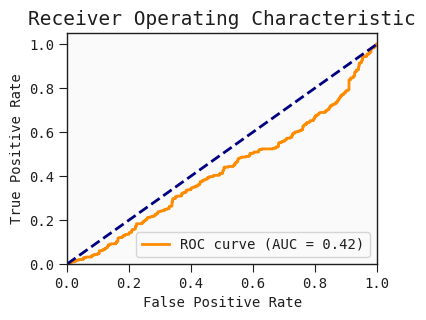

In [56]:
y_true_list_lr_demo = extract_results(results_lr_demo, 'y_true')
y_pred_prob_list_lr_demo= extract_results(results_lr_demo, 'y_pred_prob')
y_pred_list_lr_demo= extract_results(results_lr_demo, 'y_pred')
feature_selection_df_lr_demo= extract_results(results_lr_demo, 'feature_selection_df')
feature_sum_coef_df_lr_demo= extract_results(results_lr_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo}, Median AUC: {median_auc_lr_demo}, IQR : {iqr_auc_lr_demo}, IQ1-IQ3: {iqr13_auc_lr_demo}") 
auc_plot(extract_results(results_lr_demo, 'y_true'), extract_results(results_lr_demo, 'y_pred_prob'))

#### LR-Female No feature selection

In [57]:
# lr_param_grid = {
#     'C': [ 0.01, 0.1, 1, 10, 100],  
#     'penalty': ['l1'],  
#     'solver': ['saga','liblinear']  
# }

lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demoF, overall_auc_lr_demoF, median_auc_lr_demoF, iqr_auc_lr_demoF, iqr13_auc_lr_demoF = run_multiple_evaluations_parallel(model_demo_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, None, saga)
test_auc           0.646667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.626667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.546667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.666667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.666667
Name: 0, dtype: object

...

params      (1, None, saga)
test_auc           0.586667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.471667
Name: 0, dtype: object

params      (1, None, saga)
test_auc               0.42
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.576667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.353333
Name: 0, dtype: object

Overall AUC: 0.5388879456706281, Median AUC: 0.5458404074702886, IQR : 0.08637521222410871, IQ1-IQ3: (0.4866298811544991, 0.5730050933786078)


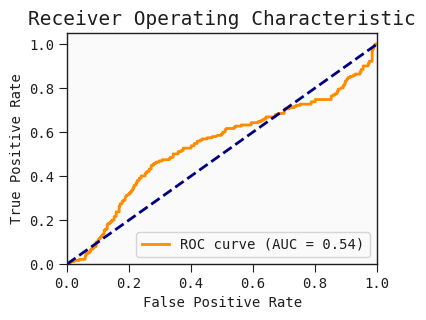

In [59]:
y_true_list_lr_demoF = extract_results(results_lr_demoF, 'y_true')
y_pred_prob_list_lr_demoF= extract_results(results_lr_demoF, 'y_pred_prob')
y_pred_list_lr_demoF= extract_results(results_lr_demoF, 'y_pred')
feature_selection_df_lr_demoF= extract_results(results_lr_demoF, 'feature_selection_df')
feature_sum_coef_df_lr_demoF= extract_results(results_lr_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demoF}, Median AUC: {median_auc_lr_demoF}, IQR : {iqr_auc_lr_demoF}, IQ1-IQ3: {iqr13_auc_lr_demoF}") 
auc_plot(extract_results(results_lr_demoF, 'y_true'), extract_results(results_lr_demoF, 'y_pred_prob'))

#### LR-Male No feature selection

In [60]:
# lr_param_grid = {
#     'C': [ 0.01, 0.1, 1, 10, 100],  
#     'penalty': ['l1'],  
#     'solver': ['saga','liblinear']  
# }

lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demoM, overall_auc_lr_demoM, median_auc_lr_demoM, iqr_auc_lr_demoM, iqr13_auc_lr_demoM  = run_multiple_evaluations_parallel(model_demo_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, None, saga)
test_auc              0.575
Name: 0, dtype: object

params      (1, None, saga)
test_auc               0.65
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.470833
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.658333
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.433333
Name: 0, dtype: object

...

params      (1, None, saga)
test_auc           0.516667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.572222
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.555556
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.483333
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.236111
Name: 0, dtype: object

Overall AUC: 0.5462499999999999, Median AUC: 0.552734375, IQR : 0.06608072916666674, IQ1-IQ3: (0.5048828125, 0.5709635416666667)


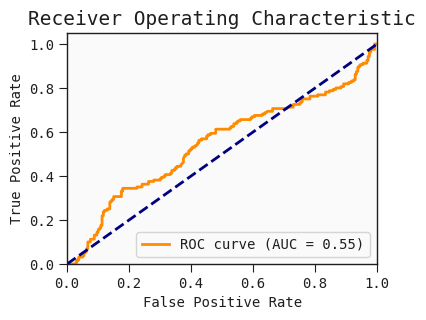

In [62]:
y_true_list_lr_demoM = extract_results(results_lr_demoM, 'y_true')
y_pred_prob_list_lr_demoM= extract_results(results_lr_demoM, 'y_pred_prob')
y_pred_list_lr_demoM= extract_results(results_lr_demoM, 'y_pred')
feature_selection_df_lr_demoM= extract_results(results_lr_demoM, 'feature_selection_df')
feature_sum_coef_df_lr_demoM= extract_results(results_lr_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demoM}, Median AUC: {median_auc_lr_demoM}, IQR : {iqr_auc_lr_demoM}, IQ1-IQ3: {iqr13_auc_lr_demoM}") 
auc_plot(extract_results(results_lr_demoM, 'y_true'), extract_results(results_lr_demoM, 'y_pred_prob'))

## Demo +APOE4

In [18]:
demo_APOE4_lst =[ 'Demographic.Sex', 'Demographic.Years.of.Education.Exact','Age','APOE4'] 
model_demo_APOE4_df = omics_demo_normalise_df_no_missing.copy()
model_demo_APOE4_df = model_demo_APOE4_df[demo_APOE4_lst+['label']]
model_demo_APOE4_df.columns

Index(['Demographic.Sex', 'Demographic.Years.of.Education.Exact', 'Age',
       'APOE4', 'label'],
      dtype='object')

In [19]:
model_demo_APOE4_df_M = model_demo_APOE4_df[model_demo_APOE4_df['Demographic.Sex']==1]
model_demo_APOE4_df_M = model_demo_APOE4_df_M.drop(['Demographic.Sex'], axis=1)
model_demo_APOE4_df_F = model_demo_APOE4_df[model_demo_APOE4_df['Demographic.Sex']==0]
model_demo_APOE4_df_F = model_demo_APOE4_df_F.drop(['Demographic.Sex'], axis=1)

#### LR-Full No feature selection

In [65]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo_APOE4, overall_auc_lr_demo_APOE4, median_auc_lr_demo_APOE4, iqr_auc_lr_demo_APOE4, iqr13_auc_lr_demo_APOE4 = run_multiple_evaluations_parallel(model_demo_APOE4_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, None, saga)
test_auc           0.524444
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.506065
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.501944
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.479537
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.501019
Name: 0, dtype: object

...

params      (1, None, saga)
test_auc           0.432963
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.491574
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.440139
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.474722
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.546852
Name: 0, dtype: object

In [67]:
results_lr_demo_APOE4_auc_scores_all = extract_results(results_lr_demo_APOE4, 'auc_scores_all')
evaluation_df2 = pd.DataFrame({'Model': "LR (Demographic+APOE4)", "AUC": results_lr_demo_APOE4_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df2], ignore_index=True)

Overall AUC: 0.4983844155844156, Median AUC: 0.5033766233766234, IQR : 0.03753246753246753, IQ1-IQ3: (0.4821428571428571, 0.5196753246753246)


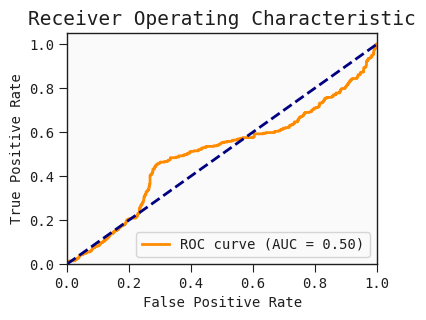

In [68]:
y_true_list_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'y_true')
y_pred_prob_list_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'y_pred_prob')
y_pred_list_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'y_pred')
feature_selection_df_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'feature_selection_df')
feature_sum_coef_df_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo_APOE4}, Median AUC: {median_auc_lr_demo_APOE4}, IQR : {iqr_auc_lr_demo_APOE4}, IQ1-IQ3: {iqr13_auc_lr_demo_APOE4}") 
auc_plot(extract_results(results_lr_demo_APOE4, 'y_true'), extract_results(results_lr_demo_APOE4, 'y_pred_prob'))

#### LR-Female No feature selection

In [69]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo_APOE4F, overall_auc_lr_demo_APOE4F, median_auc_lr_demo_APOE4F, iqr_auc_lr_demo_APOE4F, iqr13_auc_lr_demo_APOE4F = run_multiple_evaluations_parallel(model_demo_APOE4_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, None, saga)
test_auc           0.706667
Name: 0, dtype: object

params      (1, None, saga)
test_auc               0.72
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.533333
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.773333
Name: 0, dtype: object

params      (1, None, saga)
test_auc               0.66
Name: 0, dtype: object

...

params      (1, None, saga)
test_auc              0.445
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.590833
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.684167
Name: 0, dtype: object

params      (1, None, saga)
test_auc              0.585
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.434167
Name: 0, dtype: object

Overall AUC: 0.5830984719864176, Median AUC: 0.5772495755517826, IQR : 0.03753246753246753, IQ1-IQ3: (0.5719439728353141, 0.6037775891341256)


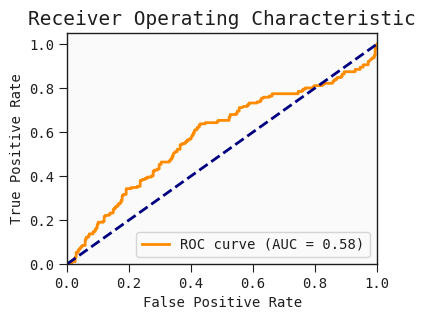

In [71]:
y_true_list_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'y_true')
y_pred_prob_list_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'y_pred_prob')
y_pred_list_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'y_pred')
feature_selection_df_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'feature_selection_df')
feature_sum_coef_df_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo_APOE4F}, Median AUC: {median_auc_lr_demo_APOE4F}, IQR : {iqr_auc_lr_demo_APOE4}, IQ1-IQ3: {iqr13_auc_lr_demo_APOE4F}") 
auc_plot(extract_results(results_lr_demo_APOE4F, 'y_true'), extract_results(results_lr_demo_APOE4F, 'y_pred_prob'))

#### LR-Male No feature selection

In [72]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo_APOE4M, overall_auc_lr_demo_APOE4M, median_auc_lr_demo_APOE4M, iqr_auc_lr_demo_APOE4M, iqr13_auc_lr_demo_APOE4M = run_multiple_evaluations_parallel(model_demo_APOE4_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, None, saga)
test_auc           0.708333
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.508333
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.633333
Name: 0, dtype: object

params      (1, None, saga)
test_auc                0.6
Name: 0, dtype: object

params      (1, None, saga)
test_auc             0.5875
Name: 0, dtype: object

...

params      (1, None, saga)
test_auc           0.380556
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.391667
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.469444
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.538889
Name: 0, dtype: object

params      (1, None, saga)
test_auc           0.383333
Name: 0, dtype: object

Overall AUC: 0.5297135416666667, Median AUC: 0.5221354166666666, IQR : 0.06412760416666674, IQ1-IQ3: (0.49641927083333326, 0.560546875)


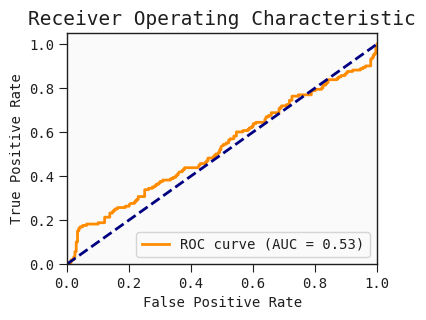

In [74]:
y_true_list_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'y_true')
y_pred_prob_list_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'y_pred_prob')
y_pred_list_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'y_pred')
feature_selection_df_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'feature_selection_df')
feature_sum_coef_df_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo_APOE4M}, Median AUC: {median_auc_lr_demo_APOE4M}, IQR : {iqr_auc_lr_demo_APOE4M}, IQ1-IQ3: {iqr13_auc_lr_demo_APOE4M}") 
auc_plot(extract_results(results_lr_demo_APOE4M, 'y_true'), extract_results(results_lr_demo_APOE4M, 'y_pred_prob'))

## Omics

In [75]:
model_omics_df = omics_demo_normalise_df_no_missing.copy()
print(len(model_omics_df.columns))

1952


In [76]:
################ OMICS Only ####################
omics_only = ['Demographic.Sex']
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_lst = list((set(model_omics_df.columns.to_list()) - set(demo_lst_full)) | set(omics_only))
model_omics_df = omics_demo_normalise_df_no_missing.copy()
model_omics_df = model_omics_df[omics_lst]
print(len(model_omics_df.columns))
model_omics_df_M = model_omics_df[model_omics_df['Demographic.Sex']==1]
model_omics_df_M = model_omics_df_M.drop(['Demographic.Sex'], axis=1)
model_omics_df_F = model_omics_df[model_omics_df['Demographic.Sex']==0]
model_omics_df_F = model_omics_df_F.drop(['Demographic.Sex'], axis=1)
# model_omics_df = model_omics_df.drop(['Demographic.Sex'], axis=1)

1943


### Logistic Regression with Lasso


#### L1-Full No feature selection

In [77]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics, overall_auc_lr_omics, median_auc_lr_omics, iqr_auc_lr_omics, iqr13_auc_lr_omics = run_multiple_evaluations_parallel(model_omics_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (10, l1, liblinear)
test_auc               0.618611
Name: 10, dtype: object

params      (1, l1, liblinear)
test_auc               0.62037
Name: 6, dtype: object

params      (5, l1, liblinear)
test_auc              0.665926
Name: 8, dtype: object

params      (0.01, l1, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (5, l1, liblinear)
test_auc              0.711389
Name: 8, dtype: object

...

params      (100, l1, saga)
test_auc            0.56213
Name: 13, dtype: object

params      (1, l1, liblinear)
test_auc              0.754537
Name: 6, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.726574
Name: 4, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.544167
Name: 4, dtype: object

params      (100, l1, saga)
test_auc           0.601574
Name: 13, dtype: object

In [79]:
results_lr_omics_auc_scores_all = extract_results(results_lr_omics, 'auc_scores_all')
evaluation_df3 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics)", "AUC": results_lr_omics_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df3], ignore_index=True)

Overall AUC: 0.47206493506493513, Median AUC: 0.46688311688311684, IQR : 0.06798701298701293, IQ1-IQ3: (0.4337662337662338, 0.5017532467532467)


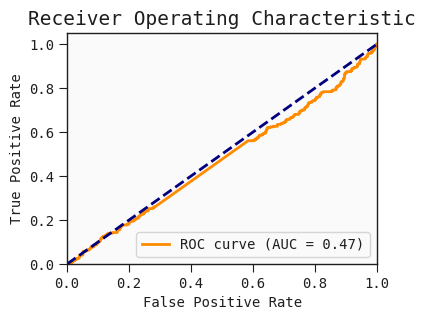

In [80]:
y_true_list_lr_omics = extract_results(results_lr_omics, 'y_true')
y_pred_prob_list_lr_omics= extract_results(results_lr_omics, 'y_pred_prob')
y_pred_list_lr_omics= extract_results(results_lr_omics, 'y_pred')
feature_selection_df_lr_omics= extract_results(results_lr_omics, 'feature_selection_df')
feature_sum_coef_df_lr_omics= extract_results(results_lr_omics, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics}, Median AUC: {median_auc_lr_omics}, IQR : {iqr_auc_lr_omics}, IQ1-IQ3: {iqr13_auc_lr_omics}") 
auc_plot(extract_results(results_lr_omics, 'y_true'), extract_results(results_lr_omics, 'y_pred_prob'))

#### L1-Female No feature selection

In [81]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omicsF, overall_auc_lr_omicsF, median_auc_lr_omicsF, iqr_auc_lr_omicsF, iqr13_auc_lr_omicsF = run_multiple_evaluations_parallel(model_omics_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (0.5, l1, saga)
test_auc               0.84
Name: 5, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.826667
Name: 4, dtype: object

params      (100, l1, liblinear)
test_auc                    0.88
Name: 12, dtype: object

params      (5, l1, liblinear)
test_auc              0.893333
Name: 8, dtype: object

params      (1, l1, liblinear)
test_auc              0.906667
Name: 6, dtype: object

...

params      (0.5, l1, saga)
test_auc           0.840833
Name: 5, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.920833
Name: 4, dtype: object

params      (0.5, l1, saga)
test_auc             0.7775
Name: 5, dtype: object

params      (0.5, l1, saga)
test_auc           0.740833
Name: 5, dtype: object

params      (0.5, l1, saga)
test_auc               0.92
Name: 5, dtype: object

In [83]:
results_lr_omicsF_auc_scores_all = extract_results(results_lr_omicsF, 'auc_scores_all')
evaluation_df5 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics Female)", "AUC": results_lr_omicsF_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df5], ignore_index=True)

Overall AUC: 0.7869269949066213, Median AUC: 0.8064516129032258, IQR : 0.06791171477079805, IQ1-IQ3: (0.7580645161290321, 0.8259762308998302)


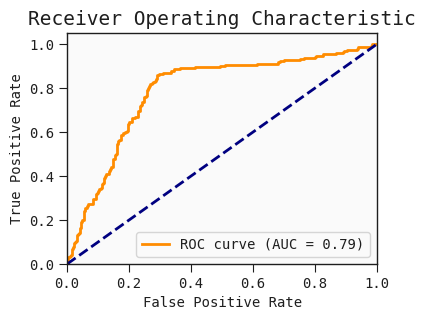

In [84]:
y_true_list_lr_omicsF = extract_results(results_lr_omicsF, 'y_true')
y_pred_prob_list_lr_omicsF= extract_results(results_lr_omicsF, 'y_pred_prob')
y_pred_list_lr_omicsF= extract_results(results_lr_omicsF, 'y_pred')
feature_selection_df_lr_omicsF= extract_results(results_lr_omicsF, 'feature_selection_df')
feature_sum_coef_df_lr_omicsF= extract_results(results_lr_omicsF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omicsF}, Median AUC: {median_auc_lr_omicsF}, IQR : {iqr_auc_lr_omicsF}, IQ1-IQ3: {iqr13_auc_lr_omicsF}") 
auc_plot(extract_results(results_lr_omicsF, 'y_true'), extract_results(results_lr_omicsF, 'y_pred_prob'))

In [85]:
feature_selection_df_lr_omicsF.head(10)

,Feature,Total Count
0,threo.1..p.Hydroxyphenyl.propylene.glycol.4..g...,50
1,C8A,30
2,DG.22.5.22.6.0.0.,34
3,Quinic.acid,34
4,N.acetyl.L.2.aminoadipate.2...1,22
5,sulfonic.acid.3,9
6,X2_5.Dioxopentanoate,1
7,LysoPE.0.0.16.1.,1
8,ENPEP,1
9,X2.Aminoacrylic.acid,6


In [86]:
feature_sum_coef_df_lr_omicsF.head(10)

,Feature,Coefficient Sum
0,threo.1..p.Hydroxyphenyl.propylene.glycol.4..g...,91.369664
1,SERPIND1,6.145096
2,C2,6.739779
3,X1.deoxyxylonojirimycin,5.472754
4,IGKV1D.39,16.370650
5,Quinic.acid,20.938319
6,DG.22.5.22.6.0.0.,22.945553
7,C8A,18.467301
8,X12_13_17.trihydroxyoctadeca.9.enoate,1.849662
9,ENPEP,0.982388


#### L1-Male No feature selection

In [87]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omicsM, overall_auc_lr_omicsM, median_auc_lr_omicsM, iqr_auc_lr_omicsM, iqr13_auc_lr_omicsM = run_multiple_evaluations_parallel(model_omics_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (5, l1, liblinear)
test_auc                   0.7
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.883333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.633333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc                  0.95
Name: 8, dtype: object

params      (100, l1, liblinear)
test_auc                0.908333
Name: 12, dtype: object

...

params      (1, l1, liblinear)
test_auc              0.741667
Name: 6, dtype: object

params      (10, l1, liblinear)
test_auc               0.858333
Name: 10, dtype: object

params      (5, l1, liblinear)
test_auc              0.869444
Name: 8, dtype: object

params      (10, l1, liblinear)
test_auc               0.713889
Name: 10, dtype: object

params      (1, l1, liblinear)
test_auc              0.908333
Name: 6, dtype: object

In [89]:
results_lr_omicsM_auc_scores_all = extract_results(results_lr_omicsM, 'auc_scores_all')
evaluation_df6 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics Male)", "AUC": results_lr_omicsM_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df6], ignore_index=True)

Overall AUC: 0.8254036458333335, Median AUC: 0.82421875, IQR : 0.072265625, IQ1-IQ3: (0.7981770833333334, 0.8704427083333334)


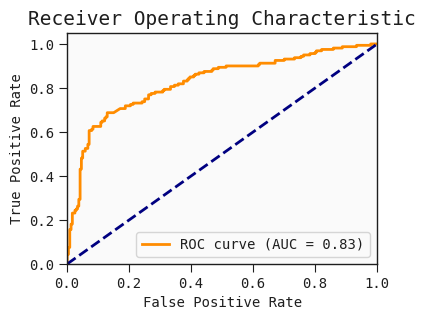

In [90]:
y_true_list_lr_omicsM = extract_results(results_lr_omicsM, 'y_true')
y_pred_prob_list_lr_omicsM= extract_results(results_lr_omicsM, 'y_pred_prob')
y_pred_list_lr_omicsM= extract_results(results_lr_omicsM, 'y_pred')
feature_selection_df_lr_omicsM= extract_results(results_lr_omicsM, 'feature_selection_df')
feature_sum_coef_df_lr_omicsM= extract_results(results_lr_omicsM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omicsM}, Median AUC: {median_auc_lr_omicsM}, IQR : {iqr_auc_lr_omicsM}, IQ1-IQ3: {iqr13_auc_lr_omicsM}") 
auc_plot(extract_results(results_lr_omicsM, 'y_true'), extract_results(results_lr_omicsM, 'y_pred_prob'))

In [91]:
feature_selection_df_lr_omicsM.head(10)

,Feature,Total Count
0,Pyrroline.hydroxycarboxylic.acid,49
1,LPA,42
2,threo.1..p.Hydroxyphenyl.propylene.glycol.4..g...,38
3,Citroside.A.4,30
4,LPL,23
5,FA.hydroxy.7.0.,38
6,Methylimidazole.acetaldehyde,37
7,epithio.seco.cholestadienetriol.S_S.dioxide,42
8,ANGPTL3,7
9,Ethyl.7.epi.12.hydroxyjasmonate.glucoside.1,8


In [92]:
feature_sum_coef_df_lr_omicsM.head(10)

,Feature,Coefficient Sum
0,Pyrroline.hydroxycarboxylic.acid,234.639071
1,epithio.seco.cholestadienetriol.S_S.dioxide,106.749137
2,Methylimidazole.acetaldehyde,65.211177
3,FA.hydroxy.7.0.,57.763502
4,LPA,63.629524
5,threo.1..p.Hydroxyphenyl.propylene.glycol.4..g...,77.274812
6,Citroside.A.4,54.244659
7,LPL,30.640778
8,Ecdysone,14.200443
9,X6.Butyryl.5_7.dihydroxy.8..3._3..dimethylally...,11.370001


### Logistic Regression with Ridge

#### L2-Full No feature selection

In [67]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics, overall_auc_lr2_omics, median_auc_lr2_omics, iqr_auc_lr2_omics, iqr13_auc_lr2_omics = run_multiple_evaluations_parallel(model_omics_df, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (5, l2, liblinear)
test_auc              0.488426
Name: 8, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.432778
Name: 0, dtype: object

params      (1, l2, liblinear)
test_auc              0.536759
Name: 6, dtype: object

params      (100, l2, liblinear)
test_auc                0.479259
Name: 12, dtype: object

params      (10, l2, liblinear)
test_auc               0.413611
Name: 10, dtype: object

...

params      (0.5, l2, liblinear)
test_auc                0.504352
Name: 4, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.487593
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.571204
Name: 0, dtype: object

params      (0.5, l2, saga)
test_auc           0.523148
Name: 5, dtype: object

params      (1, l2, liblinear)
test_auc              0.605741
Name: 6, dtype: object

Overall AUC: 0.487090909090909, Median AUC: 0.478961038961039, IQR : 0.030259740259740264, IQ1-IQ3: (0.4627272727272727, 0.492987012987013)


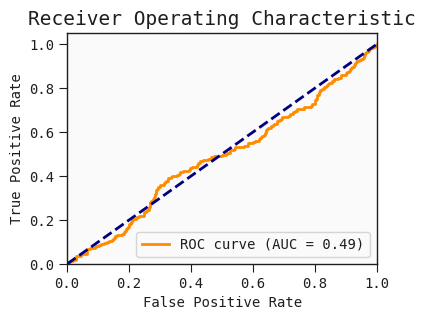

In [69]:
y_true_list_lr2_omics = extract_results(results_lr2_omics, 'y_true')
y_pred_prob_list_lr2_omics= extract_results(results_lr2_omics, 'y_pred_prob')
y_pred_list_lr2_omics= extract_results(results_lr2_omics, 'y_pred')
feature_selection_df_lr2_omics= extract_results(results_lr2_omics, 'feature_selection_df')
feature_sum_coef_df_lr2_omics= extract_results(results_lr2_omics, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics}, Median AUC: {median_auc_lr2_omics}, IQR : {iqr_auc_lr2_omics}, IQ1-IQ3: {iqr13_auc_lr2_omics}") 
auc_plot(extract_results(results_lr2_omics, 'y_true'), extract_results(results_lr2_omics, 'y_pred_prob'))

#### L2-Full RFE20

In [70]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_rfe, overall_auc_lr2_omics_rfe, median_auc_lr2_omics_rfe, iqr_auc_lr2_omics_rfe, iqr13_auc_lr2_omics_rfe = run_multiple_evaluations_parallel(model_omics_df, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, l2, saga)
test_auc          0.634907
Name: 11, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, l2, liblinear)
test_auc                 0.676574
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, l2, liblinear)
test_auc               0.574074
Name: 10, dtype: object

Do RFE feature Selection


params      (5, l2, liblinear)
test_auc              0.593426
Name: 8, dtype: object

Do RFE feature Selection


Overall AUC: 0.4997038961038961, Median AUC: 0.48597402597402595, IQR : 0.07233766233766226, IQ1-IQ3: (0.47090909090909094, 0.5432467532467532)


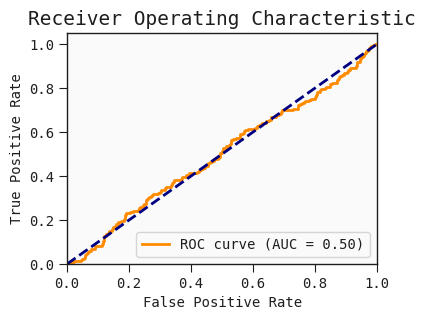

In [72]:
y_true_list_lr2_omics_rfe = extract_results(results_lr2_omics_rfe, 'y_true')
y_pred_prob_list_lr2_omics_rfe= extract_results(results_lr2_omics_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_rfe= extract_results(results_lr2_omics_rfe, 'y_pred')
feature_selection_df_lr2_omics_rfe= extract_results(results_lr2_omics_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_rfe= extract_results(results_lr2_omics_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_rfe}, Median AUC: {median_auc_lr2_omics_rfe}, IQR : {iqr_auc_lr2_omics_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_rfe}") 
auc_plot(extract_results(results_lr2_omics_rfe, 'y_true'), extract_results(results_lr2_omics_rfe, 'y_pred_prob'))

#### L2-Full MRMR20

In [73]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_mrmr, overall_auc_lr2_omics_mrmr, median_auc_lr2_omics_mrmr, iqr_auc_lr2_omics_mrmr, iqr13_auc_lr2_omics_mrmr = run_multiple_evaluations_parallel(model_omics_df, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection
Do MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:09,  1.84it/s]





 15%|█▌        | 3/20 [00:01<00:07,  2.27it/s]





 20%|██        | 4/20 [00:01<00:06,  2.44it/s]





 25%|██▌       | 5/20 [00:02<00:05,  2.72it/s]





 30%|███       | 6/20 [00:02<00:04,  2.94it/s]





 35%|███▌      | 7/20 [00:02<00:04,  3.16it/s]





 40%|████      | 8/20 [00:02<00:03,  3.19it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.36it/s]




 50%|█████     | 10/20 [00:03<00:03,  3.29it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.40it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.40it/s]





 65%|██████▌   | 13/20 [00:04<00:01,  3.53it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.47it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.44it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.49it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.37it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.38it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.48it/s]





100%|█████████

Do MRMR feature selection
Do MRMR feature selection





100%|██████████| 20/20 [00:05<00:00,  3.59it/s]

Do MRMR feature selection
Do MRMR feature selection


...

params      (100, l2, saga)
test_auc           0.630741
Name: 13, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.566296
Name: 0, dtype: object




 45%|████▌     | 9/20 [00:02<00:03,  3.23it/s]

Do MRMR feature selection
Do MRMR feature selection



 50%|█████     | 10/20 [00:03<00:04,  2.23it/s]


 60%|██████    | 12/20 [00:03<00:02,  2.74it/s]


 65%|██████▌   | 13/20 [00:03<00:02,  3.17it/s]


 70%|███████   | 14/20 [00:04<00:01,  3.45it/s]


 75%|███████▌  | 15/20 [00:04<00:01,  3.75it/s]


 80%|████████  | 16/20 [00:04<00:01,  3.77it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.19it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.34it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  4.49it/s]


100%|██████████| 20/20 [00:05<00:00,  3.71it/s]



























100%|██████████| 20/20 [00:04<00:00,  4.99it/s]


100%|██████████| 20/20 [00:03<00:00,  5.42it/s]


Overall AUC: 0.47332987012987016, Median AUC: 0.4592207792207792, IQR : 0.05597402597402601, IQ1-IQ3: (0.4388311688311688, 0.4948051948051948)


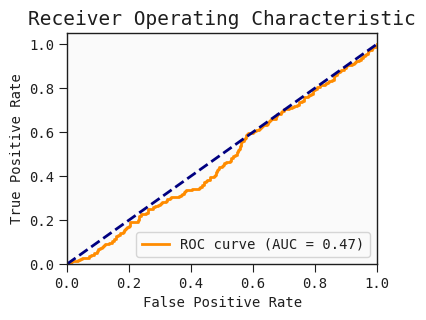

In [75]:
y_true_list_lr2_omics_mrmr = extract_results(results_lr2_omics_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_mrmr= extract_results(results_lr2_omics_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_mrmr= extract_results(results_lr2_omics_mrmr, 'y_pred')
feature_selection_df_lr2_omics_mrmr= extract_results(results_lr2_omics_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_mrmr= extract_results(results_lr2_omics_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_mrmr}, Median AUC: {median_auc_lr2_omics_mrmr}, IQR : {iqr_auc_lr2_omics_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_mrmr}") 
auc_plot(extract_results(results_lr2_omics_mrmr, 'y_true'), extract_results(results_lr2_omics_mrmr, 'y_pred_prob'))

#### L2-Full correlation20

In [76]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_corr, overall_auc_lr2_omics_corr, median_auc_lr2_omics_corr, iqr_auc_lr2_omics_corr, iqr13_auc_lr2_omics_corr = run_multiple_evaluations_parallel(model_omics_df, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                  0.5575
Name: 12, dtype: object

params      (1, l2, saga)
test_auc         0.431204
Name: 7, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.705648
Name: 0, dtype: object

Do Correlation-Based feature selection


...

Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.408148
Name: 12, dtype: object

params      (100, l2, liblinear)
test_auc                0.489907
Name: 12, dtype: object

params      (10, l2, saga)
test_auc          0.563704
Name: 11, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.4647012987012987, Median AUC: 0.46259740259740256, IQR : 0.018961038961038956, IQ1-IQ3: (0.45246753246753246, 0.4714285714285714)


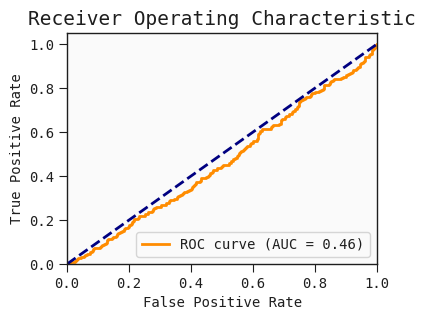

In [78]:
y_true_list_lr2_omics_corr = extract_results(results_lr2_omics_corr, 'y_true')
y_pred_prob_list_lr2_omics_corr= extract_results(results_lr2_omics_corr, 'y_pred_prob')
y_pred_list_lr2_omics_corr= extract_results(results_lr2_omics_corr, 'y_pred')
feature_selection_df_lr2_omics_corr= extract_results(results_lr2_omics_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_corr= extract_results(results_lr2_omics_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_corr}, Median AUC: {median_auc_lr2_omics_corr}, IQR : {iqr_auc_lr2_omics_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_corr}") 
auc_plot(extract_results(results_lr2_omics_corr, 'y_true'), extract_results(results_lr2_omics_corr, 'y_pred_prob'))

#### L2-Female No feature selection

In [79]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsF, overall_auc_lr2_omicsF, median_auc_lr2_omicsF, iqr_auc_lr2_omicsF, iqr13_auc_lr2_omicsF = run_multiple_evaluations_parallel(model_omics_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, l2, liblinear)
test_auc                 0.693333
Name: 0, dtype: object

params      (0.01, l2, liblinear)
test_auc                     0.64
Name: 0, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.706667
Name: 2, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.693333
Name: 2, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.586667
Name: 4, dtype: object

...

params      (0.5, l2, liblinear)
test_auc                  0.7125
Name: 4, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.670833
Name: 0, dtype: object

params      (5, l2, liblinear)
test_auc                0.4475
Name: 8, dtype: object

params      (0.5, l2, saga)
test_auc           0.566667
Name: 5, dtype: object

params      (1, l2, liblinear)
test_auc              0.726667
Name: 6, dtype: object

Overall AUC: 0.5825127334465194, Median AUC: 0.5908319185059422, IQR : 0.028862478777589184, IQ1-IQ3: (0.5768251273344651, 0.6056876061120543)


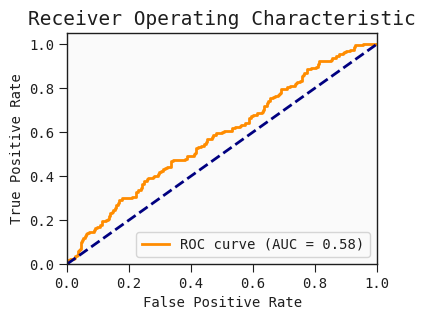

In [81]:
y_true_list_lr2_omicsF = extract_results(results_lr2_omicsF, 'y_true')
y_pred_prob_list_lr2_omicsF= extract_results(results_lr2_omicsF, 'y_pred_prob')
y_pred_list_lr2_omicsF= extract_results(results_lr2_omicsF, 'y_pred')
feature_selection_df_lr2_omicsF= extract_results(results_lr2_omicsF, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsF= extract_results(results_lr2_omicsF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsF}, Median AUC: {median_auc_lr2_omicsF}, IQR : {iqr_auc_lr2_omicsF}, IQ1-IQ3: {iqr13_auc_lr2_omicsF}") 
auc_plot(extract_results(results_lr2_omicsF, 'y_true'), extract_results(results_lr2_omicsF, 'y_pred_prob'))

#### L2-Female RFE20

In [82]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsF_rfe, overall_auc_lr2_omicsF_rfe, median_auc_lr2_omicsF_rfe, iqr_auc_lr2_omicsF_rfe, iqr13_auc_lr2_omicsF_rfe = run_multiple_evaluations_parallel(model_omics_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, liblinear)
test_auc                  0.88
Name: 8, dtype: object

Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                0.693333
Name: 12, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, saga)
test_auc           0.723333
Name: 13, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                    0.83
Name: 12, dtype: object

Do RFE feature Selection


Overall AUC: 0.7312224108658744, Median AUC: 0.7563667232597623, IQR : 0.07258064516129037, IQ1-IQ3: (0.6982173174872666, 0.7707979626485569)


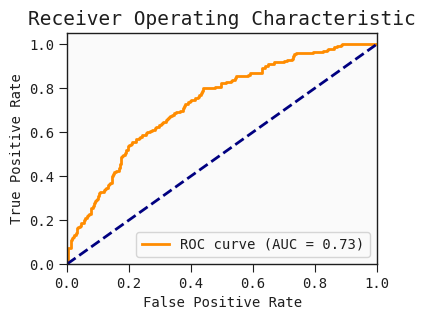

In [84]:
y_true_list_lr2_omicsF_rfe = extract_results(results_lr2_omicsF_rfe, 'y_true')
y_pred_prob_list_lr2_omicsF_rfe = extract_results(results_lr2_omicsF_rfe, 'y_pred_prob')
y_pred_list_lr2_omicsF_rfe = extract_results(results_lr2_omicsF_rfe, 'y_pred')
feature_selection_df_lr2_omicsF_rfe = extract_results(results_lr2_omicsF_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsF_rfe = extract_results(results_lr2_omicsF_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsF_rfe}, Median AUC: {median_auc_lr2_omicsF_rfe}, IQR : {iqr_auc_lr2_omicsF_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omicsF_rfe}") 
auc_plot(extract_results(results_lr2_omicsF_rfe, 'y_true'), extract_results(results_lr2_omicsF_rfe, 'y_pred_prob'))

#### L2-Female MRMR20

In [85]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsF_mrmr, overall_auc_lr2_omicsF_mrmr, median_auc_lr2_omicsF_mrmr, iqr_auc_lr2_omicsF_mrmr, iqr13_auc_lr2_omicsF_mrmr = run_multiple_evaluations_parallel(model_omics_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selectionDo MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:07,  2.35it/s]





 15%|█▌        | 3/20 [00:01<00:05,  2.84it/s]





 20%|██        | 4/20 [00:01<00:05,  3.00it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.18it/s]





 30%|███       | 6/20 [00:01<00:04,  3.40it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.48it/s]





 40%|████      | 8/20 [00:02<00:03,  3.59it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.40it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.60it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.08it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.10it/s]





 65%|██████▌   | 13/20 [00:04<00:02,  3.01it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.17it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.32it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.43it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.23it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.35it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.43it/s]





100%|██████████|

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.23it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.80it/s]





 20%|██        | 4/20 [00:01<00:05,  2.73it/s]



 25%|██▌       | 5/20 [00:01<00:05,  2.84it/s]





 30%|███       | 6/20 [00:02<00:04,  3.29it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.46it/s]





 40%|████      | 8/20 [00:02<00:03,  3.50it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.56it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.67it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.74it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.73it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.73it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.63it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.70it/s]




 80%|████████  | 16/20 [00:04<00:01,  3.97it/s]





 85%|████████▌ | 17/20 [00:04<00:00,  3.91it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.91it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.88it/s]





100%|██████████|

Do MRMR feature selection


...

  0%|          | 0/20 [00:00<?, ?it/s]





 10%|█         | 2/20 [00:00<00:06,  2.95it/s]





 15%|█▌        | 3/20 [00:01<00:05,  3.07it/s]




100%|██████████| 20/20 [00:06<00:00,  3.10it/s]

 20%|██        | 4/20 [00:01<00:04,  3.22it/s]



params      (0.1, l2, liblinear)
test_auc                0.840833
Name: 2, dtype: object

 20%|██        | 4/20 [00:00<00:02,  6.10it/s]

Do MRMR feature selection


 25%|██▌       | 5/20 [00:01<00:05,  2.77it/s]


 30%|███       | 6/20 [00:01<00:04,  3.26it/s]


 35%|███▌      | 7/20 [00:02<00:03,  3.75it/s]


 40%|████      | 8/20 [00:02<00:02,  4.02it/s]


 50%|█████     | 10/20 [00:02<00:02,  4.18it/s]


 55%|█████▌    | 11/20 [00:03<00:02,  4.32it/s]


 60%|██████    | 12/20 [00:03<00:01,  4.25it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  4.03it/s]


 70%|███████   | 14/20 [00:03<00:01,  3.87it/s]


 75%|███████▌  | 15/20 [00:04<00:01,  3.94it/s]

 80%|████████  | 16/20 [00:04<00:00,  4.20it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.55it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.51it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.19it/s]


100%|██████████| 20/20 [00:05<00:00,  3.92it/s]



100%|██████████| 20/20 [00:04<00:00,  4.14it/s]

100%|██████████| 20/20 [00:04<00:00,  4.32it/s]






100%|██████████| 20/20 [00:03<00:00,  5.13it/s]


Overall AUC: 0.6996434634974534, Median AUC: 0.7079796264855688, IQR : 0.07555178268251284, IQ1-IQ3: (0.664685908319185, 0.7402376910016978)


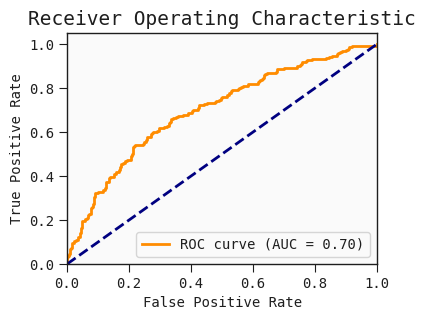

In [87]:
y_true_list_lr2_omicsF_mrmr = extract_results(results_lr2_omicsF_mrmr, 'y_true')
y_pred_prob_list_lr2_omicsF_mrmr = extract_results(results_lr2_omicsF_mrmr, 'y_pred_prob')
y_pred_list_lr2_omicsF_mrmr = extract_results(results_lr2_omicsF_mrmr, 'y_pred')
feature_selection_df_lr2_omicsF_mrmr = extract_results(results_lr2_omicsF_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsF_mrmr = extract_results(results_lr2_omicsF_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsF_mrmr}, Median AUC: {median_auc_lr2_omicsF_mrmr}, IQR : {iqr_auc_lr2_omicsF_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omicsF_mrmr}") 
auc_plot(extract_results(results_lr2_omicsF_mrmr, 'y_true'), extract_results(results_lr2_omicsF_mrmr, 'y_pred_prob'))

#### L2-Female correlation20

In [88]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsF_corr, overall_auc_lr2_omicsF_corr, median_auc_lr2_omicsF_corr, iqr_auc_lr2_omicsF_corr, iqr13_auc_lr2_omicsF_corr = run_multiple_evaluations_parallel(model_omics_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (5, l2, liblinear)
test_auc              0.853333
Name: 8, dtype: object

Do Correlation-Based feature selection


params      (0.5, l2, liblinear)
test_auc                0.813333
Name: 4, dtype: object

params      (0.1, l2, liblinear)
test_auc                    0.72
Name: 2, dtype: object

...

Do Correlation-Based feature selection


params      (10, l2, saga)
test_auc          0.761667
Name: 11, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, l2, liblinear)
test_auc               0.696667
Name: 10, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.7057215619694398, Median AUC: 0.7113752122241086, IQR : 0.06154499151103576, IQ1-IQ3: (0.6719015280135823, 0.733446519524618)


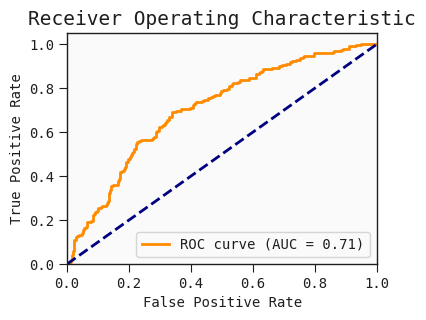

In [90]:
y_true_list_lr2_omicsF_corr = extract_results(results_lr2_omicsF_corr, 'y_true')
y_pred_prob_list_lr2_omicsF_corr= extract_results(results_lr2_omicsF_corr, 'y_pred_prob')
y_pred_list_lr2_omicsF_corr= extract_results(results_lr2_omicsF_corr, 'y_pred')
feature_selection_df_lr2_omicsF_corr= extract_results(results_lr2_omicsF_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsF_corr= extract_results(results_lr2_omicsF_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsF_corr}, Median AUC: {median_auc_lr2_omicsF_corr}, IQR : {iqr_auc_lr2_omicsF_corr}, IQ1-IQ3: {iqr13_auc_lr2_omicsF_corr}") 
auc_plot(extract_results(results_lr2_omicsF_corr, 'y_true'), extract_results(results_lr2_omicsF_corr, 'y_pred_prob'))

#### L2-Male No Feature Selection

In [91]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsM, overall_auc_lr2_omicsM, median_auc_lr2_omicsM, iqr_auc_lr2_omicsM, iqr13_auc_lr2_omicsM = run_multiple_evaluations_parallel(model_omics_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (100, l2, liblinear)
test_auc                0.616667
Name: 12, dtype: object

params      (0.01, l2, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (0.1, l2, liblinear)
test_auc                     0.4
Name: 2, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.433333
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                    0.475
Name: 0, dtype: object

...

params      (0.1, l2, liblinear)
test_auc                0.319444
Name: 2, dtype: object

params      (1, l2, liblinear)
test_auc              0.383333
Name: 6, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.541667
Name: 0, dtype: object

params      (10, l2, liblinear)
test_auc               0.519444
Name: 10, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.519444
Name: 0, dtype: object

Overall AUC: 0.4494010416666667, Median AUC: 0.46223958333333337, IQR : 0.06119791666666663, IQ1-IQ3: (0.43684895833333337, 0.498046875)


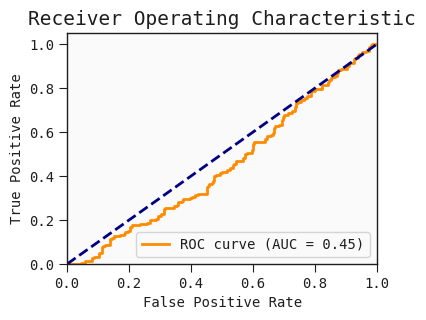

In [93]:
y_true_list_lr2_omicsM = extract_results(results_lr2_omicsM, 'y_true')
y_pred_prob_list_lr2_omicsM= extract_results(results_lr2_omicsM, 'y_pred_prob')
y_pred_list_lr2_omicsM= extract_results(results_lr2_omicsM, 'y_pred')
feature_selection_df_lr2_omicsM= extract_results(results_lr2_omicsM, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsM= extract_results(results_lr2_omicsM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsM}, Median AUC: {median_auc_lr2_omicsM}, IQR : {iqr_auc_lr2_omicsM}, IQ1-IQ3: {iqr13_auc_lr2_omicsM}") 
auc_plot(extract_results(results_lr2_omicsM, 'y_true'), extract_results(results_lr2_omicsM, 'y_pred_prob'))

#### L2-Male RFE= 20

In [94]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsM_rfe, overall_auc_lr2_omicsM_rfe, median_auc_lr2_omicsM_rfe, iqr_auc_lr2_omicsM_rfe, iqr13_auc_lr2_omicsM_rfe = run_multiple_evaluations_parallel(model_omics_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, saga)
test_auc               0.65
Name: 13, dtype: object

Do RFE feature Selection
Do RFE feature Selection


params      (0.5, l2, saga)
test_auc           0.916667
Name: 5, dtype: object

Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, saga)
test_auc              0.9
Name: 9, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                0.616667
Name: 12, dtype: object

Do RFE feature Selection


Overall AUC: 0.7306770833333334, Median AUC: 0.7109375, IQR : 0.10872395833333326, IQ1-IQ3: (0.68359375, 0.7923177083333333)


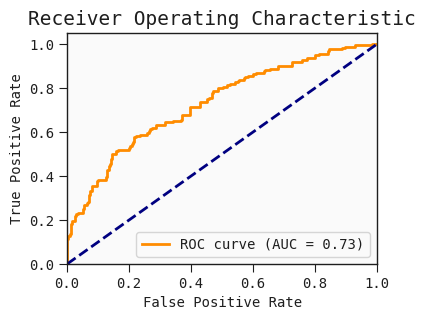

In [96]:
y_true_list_lr2_omicsM_rfe = extract_results(results_lr2_omicsM_rfe, 'y_true')
y_pred_prob_list_lr2_omicsM_rfe = extract_results(results_lr2_omicsM_rfe, 'y_pred_prob')
y_pred_list_lr2_omicsM_rfe = extract_results(results_lr2_omicsM_rfe, 'y_pred')
feature_selection_df_lr2_omicsM_rfe = extract_results(results_lr2_omicsM_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsM_rfe = extract_results(results_lr2_omicsM_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsM_rfe}, Median AUC: {median_auc_lr2_omicsM_rfe}, IQR : {iqr_auc_lr2_omicsM_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omicsM_rfe}") 
auc_plot(extract_results(results_lr2_omicsM_rfe, 'y_true'), extract_results(results_lr2_omicsM_rfe, 'y_pred_prob'))

#### L2-Male MRMR= 20

In [97]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsM_mrmr, overall_auc_lr2_omicsM_mrmr, median_auc_lr2_omicsM_mrmr, iqr_auc_lr2_omicsM_mrmr, iqr13_auc_lr2_omicsM_mrmr = run_multiple_evaluations_parallel(model_omics_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selectionDo MRMR feature selection

Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:07,  2.47it/s]





 15%|█▌        | 3/20 [00:01<00:05,  3.08it/s]





 20%|██        | 4/20 [00:01<00:04,  3.28it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.39it/s]





 30%|███       | 6/20 [00:01<00:03,  3.61it/s]



 35%|███▌      | 7/20 [00:02<00:03,  3.70it/s]





 40%|████      | 8/20 [00:02<00:03,  3.74it/s]





 45%|████▌     | 9/20 [00:02<00:02,  3.79it/s]





 50%|█████     | 10/20 [00:02<00:02,  3.81it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.84it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.58it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.59it/s]





 70%|███████   | 14/20 [00:03<00:01,  3.66it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.72it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.76it/s]





 85%|████████▌ | 17/20 [00:04<00:00,  3.78it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.68it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.70it/s]





100%|██████████| 2

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]

Do MRMR feature selection


...

Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]



100%|██████████| 20/20 [00:06<00:00,  3.05it/s]


params      (0.1, l2, liblinear)
test_auc                0.577778
Name: 2, dtype: object

Do MRMR feature selection



 10%|█         | 2/20 [00:00<00:07,  2.38it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.60it/s]







 20%|██        | 4/20 [00:01<00:05,  2.71it/s]



 25%|██▌       | 5/20 [00:01<00:04,  3.05it/s]





 30%|███       | 6/20 [00:02<00:04,  3.22it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.35it/s]


 40%|████      | 8/20 [00:02<00:03,  3.70it/s]


 45%|████▌     | 9/20 [00:02<00:03,  3.60it/s]


 50%|█████     | 10/20 [00:03<00:02,  3.86it/s]


 55%|█████▌    | 11/20 [00:03<00:02,  3.97it/s]


 60%|██████    | 12/20 [00:03<00:02,  3.86it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  3.82it/s]


 70%|███████   | 14/20 [00:04<00:01,  3.89it/s]


 80%|████████  | 16/20 [00:04<00:01,  3.95it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.19it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.48it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  4.44it/s]


100%|██████████| 20/20 [00:05<00:00,  3.64it/s]



100%|██████████| 20/20 [00:04<00:00,  4.27it/s]


100%|██████████| 20/20 [00:04<00:00,  4.3

Overall AUC: 0.6559375000000001, Median AUC: 0.64453125, IQR : 0.04427083333333326, IQ1-IQ3: (0.625, 0.6692708333333333)


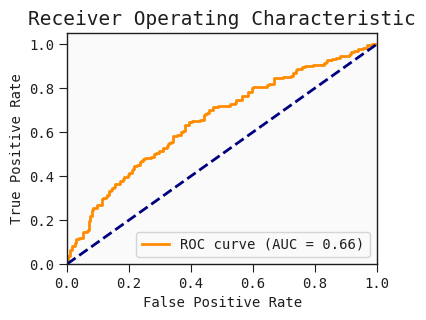

In [99]:
y_true_list_lr2_omicsM_mrmr = extract_results(results_lr2_omicsM_mrmr, 'y_true')
y_pred_prob_list_lr2_omicsM_mrmr = extract_results(results_lr2_omicsM_mrmr, 'y_pred_prob')
y_pred_list_lr2_omicsM_mrmr = extract_results(results_lr2_omicsM_mrmr, 'y_pred')
feature_selection_df_lr2_omicsM_mrmr = extract_results(results_lr2_omicsM_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsM_mrmr = extract_results(results_lr2_omicsM_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsM_mrmr}, Median AUC: {median_auc_lr2_omicsM_mrmr}, IQR : {iqr_auc_lr2_omicsM_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omicsM_mrmr}") 
auc_plot(extract_results(results_lr2_omicsM_mrmr, 'y_true'), extract_results(results_lr2_omicsM_mrmr, 'y_pred_prob'))

#### L2-Male correlation20

In [100]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omicsM_corr, overall_auc_lr2_omicsM_corr, median_auc_lr2_omicsM_corr, iqr_auc_lr2_omicsM_corr, iqr13_auc_lr2_omicsM_corr = run_multiple_evaluations_parallel(model_omics_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, l2, liblinear)
test_auc               0.791667
Name: 10, dtype: object

Do Correlation-Based feature selection


params      (5, l2, saga)
test_auc            0.625
Name: 9, dtype: object

Do Correlation-Based feature selection


...

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, l2, saga)
test_auc          0.513889
Name: 11, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.730556
Name: 12, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.6742708333333334, Median AUC: 0.6770833333333334, IQR : 0.09895833333333326, IQ1-IQ3: (0.646484375, 0.7454427083333333)


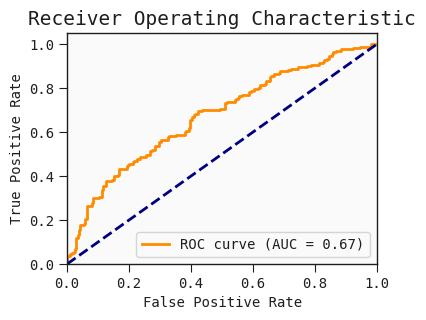

In [102]:
y_true_list_lr2_omicsM_corr = extract_results(results_lr2_omicsM_corr, 'y_true')
y_pred_prob_list_lr2_omicsM_corr= extract_results(results_lr2_omicsM_corr, 'y_pred_prob')
y_pred_list_lr2_omicsM_corr= extract_results(results_lr2_omicsM_corr, 'y_pred')
feature_selection_df_lr2_omicsM_corr= extract_results(results_lr2_omicsM_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omicsM_corr= extract_results(results_lr2_omicsM_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omicsM_corr}, Median AUC: {median_auc_lr2_omicsM_corr}, IQR : {iqr_auc_lr2_omicsM_corr}, IQ1-IQ3: {iqr13_auc_lr2_omicsM_corr}") 
auc_plot(extract_results(results_lr2_omicsM_corr, 'y_true'), extract_results(results_lr2_omicsM_corr, 'y_pred_prob'))

### SVM

#### SVM-Full No feature selection

In [121]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics, overall_auc_svm_omics, median_auc_svm_omics, iqr_auc_svm_omics, iqr13_auc_svm_omics = run_multiple_evaluations_parallel(model_omics_df, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, linear, auto)
test_auc                0.485556
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.462593
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.623333
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                 0.47213
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.593148
Name: 2, dtype: object

...

params      (0.01, linear, auto)
test_auc                0.546574
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.397778
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.437778
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.391019
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.422315
Name: 2, dtype: object

Overall AUC: 0.4501688311688311, Median AUC: 0.4381818181818182, IQR : 0.06103896103896106, IQ1-IQ3: (0.4139610389610389, 0.475)


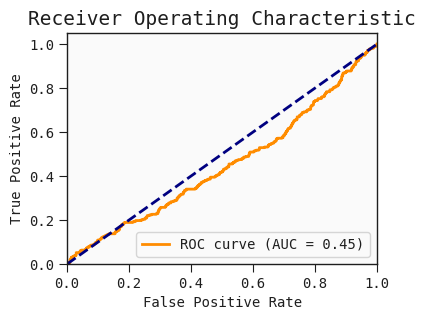

In [123]:
y_true_list_svm_omics = extract_results(results_svm_omics, 'y_true')
y_pred_prob_list_svm_omics= extract_results(results_svm_omics, 'y_pred_prob')
y_pred_list_svm_omics= extract_results(results_svm_omics, 'y_pred')
feature_selection_df_svm_omics= extract_results(results_svm_omics, 'feature_selection_df')
feature_sum_coef_df_svm_omics= extract_results(results_svm_omics, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics}, Median AUC: {median_auc_svm_omics}, IQR : {iqr_auc_svm_omics}, IQ1-IQ3: {iqr13_auc_svm_omics}") 
auc_plot(extract_results(results_svm_omics, 'y_true'), extract_results(results_svm_omics, 'y_pred_prob'))

#### SVM-Full RFE20

In [124]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_rfe, overall_auc_svm_omics_rfe, median_auc_svm_omics_rfe, iqr_auc_svm_omics_rfe, iqr13_auc_svm_omics_rfe = run_multiple_evaluations_parallel(model_omics_df, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.521389
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, linear, auto)
test_auc              0.671481
Name: 6, dtype: object

Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.578241
Name: 0, dtype: object

Do RFE feature Selection


params      (10, linear, auto)
test_auc              0.568519
Name: 6, dtype: object

Do RFE feature Selection


Overall AUC: 0.5174493506493507, Median AUC: 0.5158441558441558, IQR : 0.07999999999999985, IQ1-IQ3: (0.4828571428571429, 0.5628571428571427)


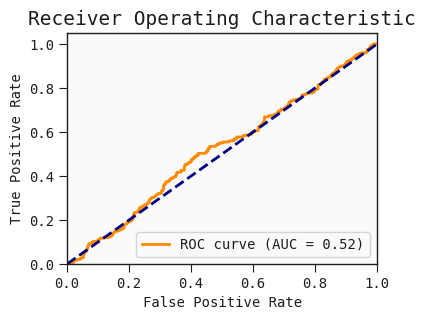

In [126]:
y_true_list_svm_omics_rfe = extract_results(results_svm_omics_rfe, 'y_true')
y_pred_prob_list_svm_omics_rfe= extract_results(results_svm_omics_rfe, 'y_pred_prob')
y_pred_list_svm_omics_rfe= extract_results(results_svm_omics_rfe, 'y_pred')
feature_selection_df_svm_omics_rfe= extract_results(results_svm_omics_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_rfe= extract_results(results_svm_omics_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_rfe}, Median AUC: {median_auc_svm_omics_rfe}, IQR : {iqr_auc_svm_omics_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_rfe}") 
auc_plot(extract_results(results_svm_omics_rfe, 'y_true'), extract_results(results_svm_omics_rfe, 'y_pred_prob'))

#### SVM-Full MRMR20

In [127]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_mrmr, overall_auc_svm_omics_mrmr, median_auc_svm_omics_mrmr, iqr_auc_svm_omics_mrmr, iqr13_auc_svm_omics_mrmr = run_multiple_evaluations_parallel(model_omics_df, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]





 10%|█         | 2/20 [00:00<00:07,  2.52it/s]





 15%|█▌        | 3/20 [00:01<00:05,  2.96it/s]





 20%|██        | 4/20 [00:01<00:05,  3.14it/s]





 25%|██▌       | 5/20 [00:01<00:04,  3.37it/s]





 30%|███       | 6/20 [00:01<00:03,  3.54it/s]





 35%|███▌      | 7/20 [00:02<00:04,  2.67it/s]


 40%|████      | 8/20 [00:02<00:04,  2.99it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.26it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.25it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.14it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.29it/s]





 65%|██████▌   | 13/20 [00:04<00:02,  3.48it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.48it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.58it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.62it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.62it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.64it/s]



 95%|█████████▌| 19/20 [00:05<00:00,  3.61it/s]





100%|██████████

Do MRMR feature selection




100%|██████████| 20/20 [00:05<00:00,  3.51it/s]


Do MRMR feature selection


...

params      (1, linear, auto)
test_auc             0.558148
Name: 4, dtype: object

params      (100, linear, auto)
test_auc               0.628889
Name: 8, dtype: object

 20%|██        | 4/20 [00:00<00:03,  4.90it/s]

Do MRMR feature selectionDo MRMR feature selection



 30%|███       | 6/20 [00:01<00:05,  2.50it/s]


 35%|███▌      | 7/20 [00:01<00:04,  3.01it/s]


 45%|████▌     | 9/20 [00:02<00:03,  2.78it/s]


 50%|█████     | 10/20 [00:03<00:03,  2.65it/s]


 55%|█████▌    | 11/20 [00:03<00:03,  2.82it/s]


 60%|██████    | 12/20 [00:03<00:02,  3.19it/s]


 65%|██████▌   | 13/20 [00:03<00:02,  3.44it/s]


 70%|███████   | 14/20 [00:04<00:01,  3.82it/s]


 75%|███████▌  | 15/20 [00:04<00:01,  4.13it/s]


 80%|████████  | 16/20 [00:04<00:00,  4.35it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.71it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.94it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  4.87it/s]


100%|██████████| 20/20 [00:05<00:00,  3.76it/s]















100%|██████████| 20/20 [00:04<00:00,  4.17it/s]


100%|██████████| 20/20 [00:04<00:00,  4.65it/s]


Overall AUC: 0.46362597402597405, Median AUC: 0.46545454545454545, IQR : 0.07701298701298709, IQ1-IQ3: (0.4342857142857143, 0.5112987012987014)


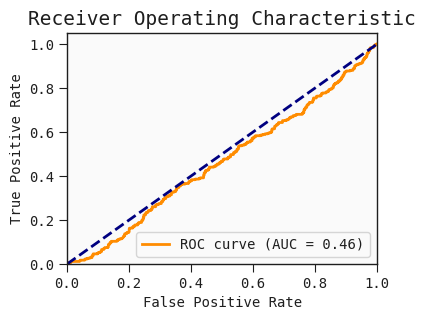

In [129]:
y_true_list_svm_omics_mrmr = extract_results(results_svm_omics_mrmr, 'y_true')
y_pred_prob_list_svm_omics_mrmr= extract_results(results_svm_omics_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_mrmr= extract_results(results_svm_omics_mrmr, 'y_pred')
feature_selection_df_svm_omics_mrmr= extract_results(results_svm_omics_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_mrmr= extract_results(results_svm_omics_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_mrmr}, Median AUC: {median_auc_svm_omics_mrmr}, IQR : {iqr_auc_svm_omics_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_mrmr}") 
auc_plot(extract_results(results_svm_omics_mrmr, 'y_true'), extract_results(results_svm_omics_mrmr, 'y_pred_prob'))

#### SVM-Full correlation20

In [130]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_corr, overall_auc_svm_omics_corr, median_auc_svm_omics_corr, iqr_auc_svm_omics_corr, iqr13_auc_svm_omics_corr = run_multiple_evaluations_parallel(model_omics_df, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.593241
Name: 0, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.582315
Name: 0, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


...

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.663056
Name: 0, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.603426
Name: 0, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.4672571428571428, Median AUC: 0.44753246753246756, IQR : 0.06194805194805214, IQ1-IQ3: (0.4328571428571428, 0.4948051948051949)


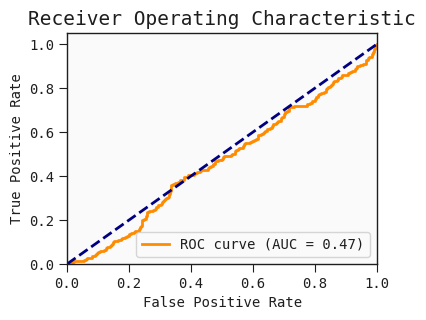

In [132]:
y_true_list_svm_omics_corr = extract_results(results_svm_omics_corr, 'y_true')
y_pred_prob_list_svm_omics_corr = extract_results(results_svm_omics_corr, 'y_pred_prob')
y_pred_list_svm_omics_corr = extract_results(results_svm_omics_corr, 'y_pred')
feature_selection_df_svm_omics_corr = extract_results(results_svm_omics_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_corr = extract_results(results_svm_omics_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_corr}, Median AUC: {median_auc_svm_omics_corr}, IQR : {iqr_auc_svm_omics_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_corr}") 
auc_plot(extract_results(results_svm_omics_corr, 'y_true'), extract_results(results_svm_omics_corr, 'y_pred_prob'))

#### SVM-Female No feature selection

In [133]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omicsF, overall_auc_svm_omicsF, median_auc_svm_omicsF, iqr_auc_svm_omicsF, iqr13_auc_svm_omicsF = run_multiple_evaluations_parallel(model_omics_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.1, linear, auto)
test_auc               0.453333
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.48
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.666667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.546667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.493333
Name: 2, dtype: object

...

params      (0.1, linear, auto)
test_auc                 0.7125
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.540833
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                  0.4875
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc                   0.35
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.753333
Name: 2, dtype: object

Overall AUC: 0.46267402376910016, Median AUC: 0.4516129032258065, IQR : 0.057300509337860794, IQ1-IQ3: (0.4291171477079796, 0.4864176570458404)


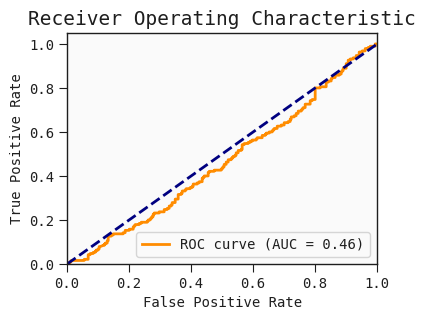

In [135]:
y_true_list_svm_omicsF = extract_results(results_svm_omicsF, 'y_true')
y_pred_prob_list_svm_omicsF= extract_results(results_svm_omicsF, 'y_pred_prob')
y_pred_list_svm_omicsF= extract_results(results_svm_omicsF, 'y_pred')
feature_selection_df_svm_omicsF= extract_results(results_svm_omicsF, 'feature_selection_df')
feature_sum_coef_df_svm_omicsF= extract_results(results_svm_omicsF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsF}, Median AUC: {median_auc_svm_omicsF}, IQR : {iqr_auc_svm_omicsF}, IQ1-IQ3: {iqr13_auc_svm_omicsF}") 
auc_plot(extract_results(results_svm_omicsF, 'y_true'), extract_results(results_svm_omicsF, 'y_pred_prob'))

#### SVM-Female RFE20

In [136]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omicsF_rfe, overall_auc_svm_omicsF_rfe, median_auc_svm_omicsF_rfe, iqr_auc_svm_omicsF_rfe, iqr13_auc_svm_omicsF_rfe = run_multiple_evaluations_parallel(model_omics_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.813333
Name: 4, dtype: object

Do RFE feature Selection


params      (1, linear, auto)
test_auc                  0.8
Name: 4, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

params      (1, linear, auto)
test_auc             0.699167
Name: 4, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc               0.6825
Name: 4, dtype: object

params      (1, linear, auto)
test_auc             0.816667
Name: 4, dtype: object

Do RFE feature Selection
Do RFE feature Selection


Overall AUC: 0.6941256366723259, Median AUC: 0.7147707979626485, IQR : 0.09040747028862473, IQ1-IQ3: (0.6417657045840407, 0.7321731748726654)


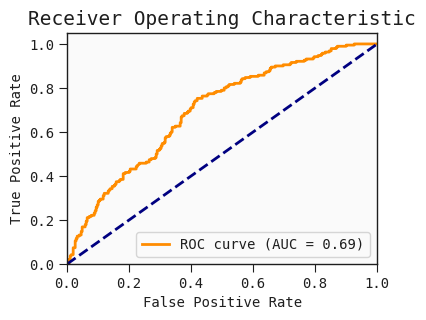

In [138]:
y_true_list_svm_omicsF_rfe = extract_results(results_svm_omicsF_rfe, 'y_true')
y_pred_prob_list_svm_omicsF_rfe= extract_results(results_svm_omicsF_rfe, 'y_pred_prob')
y_pred_list_svm_omicsF_rfe= extract_results(results_svm_omicsF_rfe, 'y_pred')
feature_selection_df_svm_omicsF_rfe= extract_results(results_svm_omicsF_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omicsF_rfe= extract_results(results_svm_omicsF_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsF_rfe}, Median AUC: {median_auc_svm_omicsF_rfe}, IQR : {iqr_auc_svm_omicsF_rfe}, IQ1-IQ3: {iqr13_auc_svm_omicsF_rfe}") 
auc_plot(extract_results(results_svm_omicsF_rfe, 'y_true'), extract_results(results_svm_omicsF_rfe, 'y_pred_prob'))

#### SVM-Female MRMR20

In [139]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omicsF_mrmr, overall_auc_svm_omicsF_mrmr, median_auc_svm_omicsF_mrmr, iqr_auc_svm_omicsF_mrmr, iqr13_auc_svm_omicsF_mrmr = run_multiple_evaluations_parallel(model_omics_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection

Do MRMR feature selection
Do MRMR feature selectionDo MRMR feature selection



  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:07,  2.50it/s]



 15%|█▌        | 3/20 [00:01<00:05,  3.10it/s]





 20%|██        | 4/20 [00:01<00:04,  3.29it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.29it/s]





 30%|███       | 6/20 [00:01<00:04,  3.42it/s]


 35%|███▌      | 7/20 [00:02<00:04,  2.99it/s]




 40%|████      | 8/20 [00:02<00:03,  3.44it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.46it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.52it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.39it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.42it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.57it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.50it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.62it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.64it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.63it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.72it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.41it/s]





100%|██████████| 20/20

Do MRMR feature selection





100%|██████████| 20/20 [00:05<00:00,  2.69it/s]

Do MRMR feature selection
Do MRMR feature selection


...

Do MRMR feature selection


params      (0.01, linear, auto)
test_auc                0.585417
Name: 0, dtype: object





 25%|██▌       | 5/20 [00:01<00:03,  3.89it/s]


Do MRMR feature selection


 20%|██        | 4/20 [00:01<00:04,  3.73it/s]


 30%|███       | 6/20 [00:01<00:04,  3.48it/s]





 35%|███▌      | 7/20 [00:01<00:03,  3.65it/s]





 40%|████      | 8/20 [00:02<00:03,  3.67it/s]





 45%|████▌     | 9/20 [00:02<00:02,  3.69it/s]





 50%|█████     | 10/20 [00:02<00:02,  3.55it/s]


 55%|█████▌    | 11/20 [00:02<00:02,  3.67it/s]


 60%|██████    | 12/20 [00:03<00:01,  4.20it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  4.22it/s]


 70%|███████   | 14/20 [00:03<00:01,  4.50it/s]


 75%|███████▌  | 15/20 [00:03<00:01,  4.69it/s]


 80%|████████  | 16/20 [00:03<00:00,  4.63it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.72it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.71it/s]


100%|██████████| 20/20 [00:04<00:00,  4.31it/s]






100%|██████████| 20/20 [00:04<00:00,  4.29it/s]





100%|██████████| 20/20 [00:04<00:00,  4.78it/s]


100%|██████████| 20/20 [00:03<00:00,  5.06it/s]


Overall AUC: 0.702741935483871, Median AUC: 0.7003395585738541, IQR : 0.053904923599320864, IQ1-IQ3: (0.6833616298811545, 0.7372665534804753)


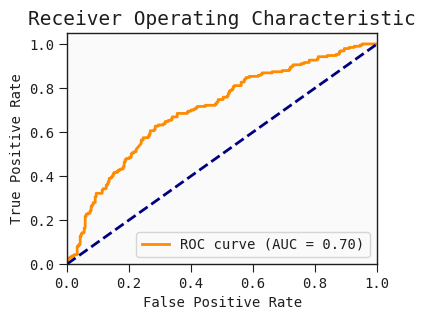

In [141]:
y_true_list_svm_omicsF_mrmr = extract_results(results_svm_omicsF_mrmr, 'y_true')
y_pred_prob_list_svm_omicsF_mrmr= extract_results(results_svm_omicsF_mrmr, 'y_pred_prob')
y_pred_list_svm_omicsF_mrmr= extract_results(results_svm_omicsF_mrmr, 'y_pred')
feature_selection_df_svm_omicsF_mrmr= extract_results(results_svm_omicsF_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omicsF_mrmr= extract_results(results_svm_omicsF_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsF_mrmr}, Median AUC: {median_auc_svm_omicsF_mrmr}, IQR : {iqr_auc_svm_omicsF_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omicsF_mrmr}") 
auc_plot(extract_results(results_svm_omicsF_mrmr, 'y_true'), extract_results(results_svm_omicsF_mrmr, 'y_pred_prob'))

#### SVM-Female correlation20

In [142]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omicsF_corr, overall_auc_svm_omicsF_corr, median_auc_svm_omicsF_corr, iqr_auc_svm_omicsF_corr, iqr13_auc_svm_omicsF_corr = run_multiple_evaluations_parallel(model_omics_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc               0.706667
Name: 2, dtype: object

params      (1, linear, auto)
test_auc                 0.76
Name: 4, dtype: object

params      (0.1, linear, auto)
test_auc               0.693333
Name: 2, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


...

params      (10, linear, auto)
test_auc              0.749167
Name: 6, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc                 0.6425
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.698333
Name: 0, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.7091171477079796, Median AUC: 0.6876061120543293, IQR : 0.05814940577249583, IQ1-IQ3: (0.6706281833616299, 0.7287775891341257)


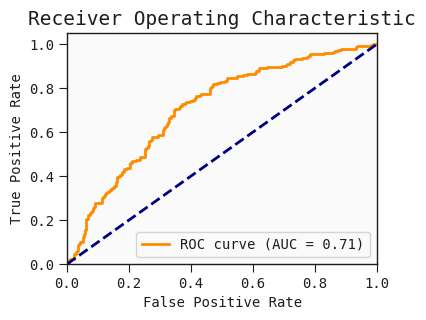

In [144]:
y_true_list_svm_omicsF_corr = extract_results(results_svm_omicsF_corr, 'y_true')
y_pred_prob_list_svm_omicsF_corr = extract_results(results_svm_omicsF_corr, 'y_pred_prob')
y_pred_list_svm_omicsF_corr = extract_results(results_svm_omicsF_corr, 'y_pred')
feature_selection_df_svm_omicsF_corr = extract_results(results_svm_omicsF_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omicsF_corr = extract_results(results_svm_omicsF_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsF_corr}, Median AUC: {median_auc_svm_omicsF_corr}, IQR : {iqr_auc_svm_omicsF_corr}, IQ1-IQ3: {iqr13_auc_svm_omicsF_corr}") 
auc_plot(extract_results(results_svm_omicsF_corr, 'y_true'), extract_results(results_svm_omicsF_corr, 'y_pred_prob'))

#### SVM-Male No feature selection

In [145]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omicsM, overall_auc_svm_omicsM, median_auc_svm_omicsM, iqr_auc_svm_omicsM, iqr13_auc_svm_omicsM = run_multiple_evaluations_parallel(model_omics_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, linear, auto)
test_auc                   0.575
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.516667
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.433333
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.533333
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.616667
Name: 0, dtype: object

...

params      (0.1, linear, auto)
test_auc                   0.65
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.472222
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.697222
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.363889
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.441667
Name: 2, dtype: object

Overall AUC: 0.46061197916666663, Median AUC: 0.49088541666666663, IQR : 0.13216145833333343, IQ1-IQ3: (0.3997395833333333, 0.5319010416666667)


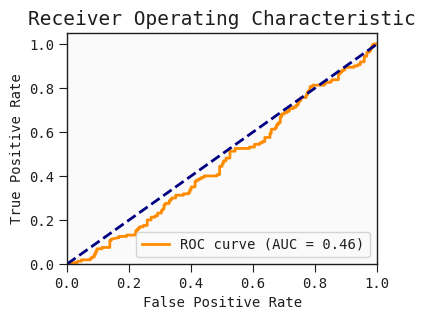

In [147]:
y_true_list_svm_omicsM = extract_results(results_svm_omicsM, 'y_true')
y_pred_prob_list_svm_omicsM= extract_results(results_svm_omicsM, 'y_pred_prob')
y_pred_list_svm_omicsM= extract_results(results_svm_omicsM, 'y_pred')
feature_selection_df_svm_omicsM= extract_results(results_svm_omicsM, 'feature_selection_df')
feature_sum_coef_df_svm_omicsM= extract_results(results_svm_omicsM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsM}, Median AUC: {median_auc_svm_omicsM}, IQR : {iqr_auc_svm_omicsM}, IQ1-IQ3: {iqr13_auc_svm_omicsM}") 
auc_plot(extract_results(results_svm_omicsM, 'y_true'), extract_results(results_svm_omicsM, 'y_pred_prob'))

#### SVM-Male RFE20

In [166]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omicsM_rfe, overall_auc_svm_omicsM_rfe, median_auc_svm_omicsM_rfe, iqr_auc_svm_omicsM_rfe, iqr13_auc_svm_omicsM_rfe = run_multiple_evaluations_parallel(model_omics_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                   0.625
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, linear, auto)
test_auc              0.658333
Name: 6, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection

...

Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.577778
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, linear, auto)
test_auc               0.877778
Name: 2, dtype: object

Do RFE feature Selection


Overall AUC: 0.6656770833333334, Median AUC: 0.65625, IQR : 0.07942708333333326, IQ1-IQ3: (0.6022135416666667, 0.681640625)


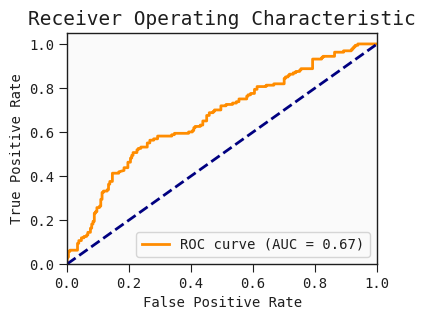

In [168]:
y_true_list_svm_omicsM_rfe = extract_results(results_svm_omicsM_rfe, 'y_true')
y_pred_prob_list_svm_omicsM_rfe= extract_results(results_svm_omicsM_rfe, 'y_pred_prob')
y_pred_list_svm_omicsM_rfe= extract_results(results_svm_omicsM_rfe, 'y_pred')
feature_selection_df_svm_omicsM_rfe= extract_results(results_svm_omicsM_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omicsM_rfe= extract_results(results_svm_omicsM_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsM_rfe}, Median AUC: {median_auc_svm_omicsM_rfe}, IQR : {iqr_auc_svm_omicsM_rfe}, IQ1-IQ3: {iqr13_auc_svm_omicsM_rfe}") 
auc_plot(extract_results(results_svm_omicsM_rfe, 'y_true'), extract_results(results_svm_omicsM_rfe, 'y_pred_prob'))

#### SVM-Male MRMR20

In [151]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omicsM_mrmr, overall_auc_svm_omicsM_mrmr, median_auc_svm_omicsM_mrmr, iqr_auc_svm_omicsM_mrmr, iqr13_auc_svm_omicsM_mrmr = run_multiple_evaluations_parallel(model_omics_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection
Do MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:09,  1.98it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.64it/s]





 20%|██        | 4/20 [00:01<00:05,  2.88it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.07it/s]



 30%|███       | 6/20 [00:02<00:04,  3.40it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.57it/s]





 40%|████      | 8/20 [00:02<00:03,  3.38it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.54it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.55it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.28it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.38it/s]





 65%|██████▌   | 13/20 [00:04<00:01,  3.56it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.43it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.50it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.60it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.66it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.97it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.67it/s]





100%|██████████| 2

Do MRMR feature selection


100%|██████████| 20/20 [00:06<00:00,  3.16it/s]


100%|██████████| 20/20 [00:06<00:00,  3.33it/s]


Do MRMR feature selection
Do MRMR feature selection


...







 25%|██▌       | 5/20 [00:01<00:03,  3.82it/s]





100%|██████████| 20/20 [00:05<00:00,  3.47it/s]



 35%|███▌      | 7/20 [00:01<00:03,  4.02it/s]

params      (1, linear, auto)
test_auc             0.638889
Name: 4, dtype: object





 40%|████      | 8/20 [00:01<00:02,  4.06it/s]

Do MRMR feature selection








 45%|████▌     | 9/20 [00:02<00:03,  3.33it/s]


 50%|█████     | 10/20 [00:02<00:02,  3.58it/s]


 55%|█████▌    | 11/20 [00:02<00:02,  3.45it/s]


 60%|██████    | 12/20 [00:03<00:02,  3.66it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  3.96it/s]


 70%|███████   | 14/20 [00:03<00:01,  4.17it/s]


 75%|███████▌  | 15/20 [00:03<00:01,  4.31it/s]


 80%|████████  | 16/20 [00:03<00:00,  4.42it/s]

 85%|████████▌ | 17/20 [00:04<00:00,  4.25it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.49it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.83it/s]




100%|██████████| 20/20 [00:04<00:00,  4.10it/s]







100%|██████████| 20/20 [00:04<00:00,  4.29it/s]






100%|██████████| 20/20 [00:04<00:00,  4.56it/s]


100%|██████████| 20/20 [00:03<00:00,  5.80it/s]


Overall AUC: 0.6082552083333332, Median AUC: 0.6145833333333334, IQR : 0.16341145833333337, IQ1-IQ3: (0.5169270833333334, 0.6803385416666667)


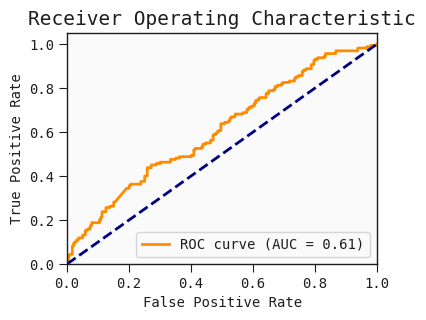

In [153]:
y_true_list_svm_omicsM_mrmr = extract_results(results_svm_omicsM_mrmr, 'y_true')
y_pred_prob_list_svm_omicsM_mrmr= extract_results(results_svm_omicsM_mrmr, 'y_pred_prob')
y_pred_list_svm_omicsM_mrmr= extract_results(results_svm_omicsM_mrmr, 'y_pred')
feature_selection_df_svm_omicsM_mrmr= extract_results(results_svm_omicsM_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omicsM_mrmr= extract_results(results_svm_omicsM_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsM_mrmr}, Median AUC: {median_auc_svm_omicsM_mrmr}, IQR : {iqr_auc_svm_omicsM_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omicsM_mrmr}") 
auc_plot(extract_results(results_svm_omicsM_mrmr, 'y_true'), extract_results(results_svm_omicsM_mrmr, 'y_pred_prob'))

#### SVM-Male correlation20

In [154]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omicsM_corr, overall_auc_svm_omicsM_corr, median_auc_svm_omicsM_corr, iqr_auc_svm_omicsM_corr, iqr13_auc_svm_omicsM_corr = run_multiple_evaluations_parallel(model_omics_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc                  0.7
Name: 4, dtype: object

Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.566667
Name: 0, dtype: object

params      (10, linear, auto)
test_auc                 0.675
Name: 6, dtype: object

...

params      (100, linear, auto)
test_auc               0.538889
Name: 8, dtype: object

params      (10, linear, auto)
test_auc                 0.575
Name: 6, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc             0.669444
Name: 4, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.605625, Median AUC: 0.59765625, IQR : 0.11718750000000011, IQ1-IQ3: (0.5052083333333333, 0.6223958333333334)


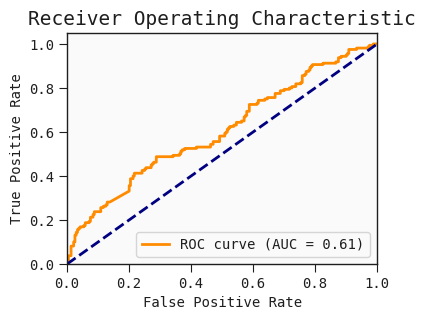

In [156]:
y_true_list_svm_omicsM_corr = extract_results(results_svm_omicsM_corr, 'y_true')
y_pred_prob_list_svm_omicsM_corr = extract_results(results_svm_omicsM_corr, 'y_pred_prob')
y_pred_list_svm_omicsM_corr = extract_results(results_svm_omicsM_corr, 'y_pred')
feature_selection_df_svm_omicsM_corr = extract_results(results_svm_omicsM_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omicsM_corr = extract_results(results_svm_omicsM_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omicsM_corr}, Median AUC: {median_auc_svm_omicsM_corr}, IQR : {iqr_auc_svm_omicsM_corr}, IQ1-IQ3: {iqr13_auc_svm_omicsM_corr}") 
auc_plot(extract_results(results_svm_omicsM_corr, 'y_true'), extract_results(results_svm_omicsM_corr, 'y_pred_prob'))

### Random Forest

#### RF-Full No feature selection

In [157]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics, overall_auc_rf_omics, median_auc_rf_omics, iqr_auc_rf_omics, iqr13_auc_rf_omics = run_multiple_evaluations_parallel(model_omics_df, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (5, 5, 10, 2)
test_auc         0.552407
Name: 6, dtype: object

params      (5, None, 2, 2)
test_auc           0.467593
Name: 8, dtype: object

params      (5, 3, 10, 2)
test_auc         0.555185
Name: 2, dtype: object

params      (5, 5, 10, 2)
test_auc         0.503889
Name: 6, dtype: object

params      (5, 3, 10, 4)
test_auc         0.538009
Name: 3, dtype: object

...

params      (50, None, 2, 4)
test_auc            0.473426
Name: 21, dtype: object

params      (100, 3, 10, 2)
test_auc           0.634444
Name: 26, dtype: object

params      (5, 3, 2, 2)
test_auc        0.656898
Name: 0, dtype: object

params      (5, 3, 2, 2)
test_auc        0.569259
Name: 0, dtype: object

params      (5, 5, 2, 2)
test_auc         0.64875
Name: 4, dtype: object

Overall AUC: 0.45677402597402594, Median AUC: 0.4497402597402597, IQR : 0.07571428571428562, IQ1-IQ3: (0.42220779220779225, 0.4979220779220779)


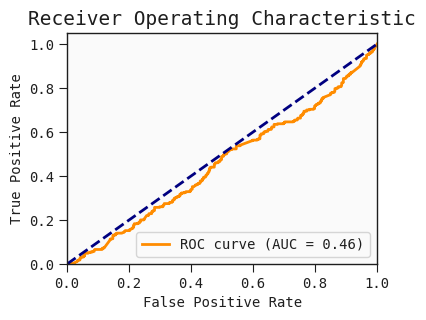

In [159]:
y_true_list_rf_omics = extract_results(results_rf_omics, 'y_true')
y_pred_prob_list_rf_omics= extract_results(results_rf_omics, 'y_pred_prob')
y_pred_list_rf_omics= extract_results(results_rf_omics, 'y_pred')
feature_selection_df_rf_omics= extract_results(results_rf_omics, 'feature_selection_df')
feature_sum_coef_df_rf_omics= extract_results(results_rf_omics, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics}, Median AUC: {median_auc_rf_omics}, IQR : {iqr_auc_rf_omics}, IQ1-IQ3: {iqr13_auc_rf_omics}") 
auc_plot(extract_results(results_rf_omics, 'y_true'), extract_results(results_rf_omics, 'y_pred_prob'))

#### RF-Female No Feature selection

In [160]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omicsF, overall_auc_rf_omicsF, median_auc_rf_omicsF, iqr_auc_rf_omicsF, iqr13_auc_rf_omicsF = run_multiple_evaluations_parallel(model_omics_df_F, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (5, 3, 10, 4)
test_auc             0.78
Name: 3, dtype: object

params      (5, None, 10, 4)
test_auc            0.686667
Name: 11, dtype: object

params      (50, 3, 2, 4)
test_auc         0.746667
Name: 13, dtype: object

params      (5, None, 10, 2)
test_auc            0.666667
Name: 10, dtype: object

params      (50, 5, 2, 2)
test_auc         0.786667
Name: 16, dtype: object

...

params      (500, None, 10, 4)
test_auc              0.765833
Name: 47, dtype: object

params      (5, 5, 10, 2)
test_auc           0.6125
Name: 6, dtype: object

params      (50, None, 2, 2)
test_auc            0.735833
Name: 20, dtype: object

params      (50, 5, 10, 4)
test_auc             0.525
Name: 19, dtype: object

params      (50, 5, 10, 4)
test_auc          0.726667
Name: 19, dtype: object

Overall AUC: 0.5694142614601019, Median AUC: 0.5674872665534805, IQR : 0.10038200339558578, IQ1-IQ3: (0.5267402376910018, 0.6271222410865875)


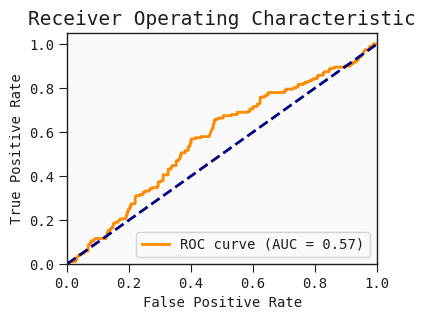

In [162]:
y_true_list_rf_omicsF = extract_results(results_rf_omicsF, 'y_true')
y_pred_prob_list_rf_omicsF = extract_results(results_rf_omicsF, 'y_pred_prob')
y_pred_list_rf_omicsF = extract_results(results_rf_omicsF, 'y_pred')
feature_selection_df_rf_omicsF = extract_results(results_rf_omicsF, 'feature_selection_df')
feature_sum_coef_df_rf_omicsF = extract_results(results_rf_omicsF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omicsF}, Median AUC: {median_auc_rf_omicsF}, IQR : {iqr_auc_rf_omicsF}, IQ1-IQ3: {iqr13_auc_rf_omicsF}") 
auc_plot(extract_results(results_rf_omicsF, 'y_true'), extract_results(results_rf_omicsF, 'y_pred_prob'))

#### RF-Male No Feature selection

In [163]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omicsM, overall_auc_rf_omicsM, median_auc_rf_omicsM, iqr_auc_rf_omicsM, iqr13_auc_rf_omicsM = run_multiple_evaluations_parallel(model_omics_df_M, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (500, 3, 10, 2)
test_auc           0.408333
Name: 38, dtype: object

params      (50, None, 10, 4)
test_auc             0.541667
Name: 23, dtype: object

params      (50, 3, 10, 2)
test_auc          0.641667
Name: 14, dtype: object

params      (50, 3, 10, 2)
test_auc          0.483333
Name: 14, dtype: object

params      (5, 3, 10, 2)
test_auc         0.545833
Name: 2, dtype: object

...

params      (5, None, 10, 4)
test_auc            0.458333
Name: 11, dtype: object

params      (5, 3, 2, 4)
test_auc        0.508333
Name: 1, dtype: object

params      (5, 3, 2, 2)
test_auc        0.593056
Name: 0, dtype: object

params      (5, 3, 2, 2)
test_auc        0.758333
Name: 0, dtype: object

params      (5, None, 10, 2)
test_auc            0.454167
Name: 10, dtype: object

Overall AUC: 0.3812369791666667, Median AUC: 0.388671875, IQR : 0.078125, IQ1-IQ3: (0.35221354166666663, 0.43033854166666663)


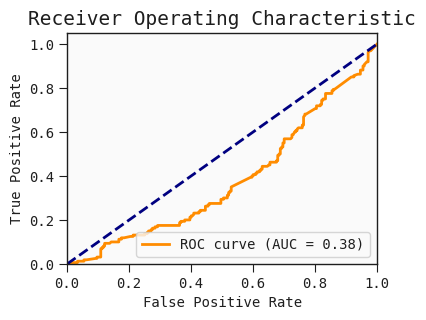

In [165]:
y_true_list_rf_omicsM = extract_results(results_rf_omicsM, 'y_true')
y_pred_prob_list_rf_omicsM = extract_results(results_rf_omicsM, 'y_pred_prob')
y_pred_list_rf_omicsM = extract_results(results_rf_omicsM, 'y_pred')
feature_selection_df_rf_omicsM = extract_results(results_rf_omicsM, 'feature_selection_df')
feature_sum_coef_df_rf_omicsM = extract_results(results_rf_omicsM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omicsM}, Median AUC: {median_auc_rf_omicsM}, IQR : {iqr_auc_rf_omicsM}, IQ1-IQ3: {iqr13_auc_rf_omicsM}") 
auc_plot(extract_results(results_rf_omicsM, 'y_true'), extract_results(results_rf_omicsM, 'y_pred_prob'))

### QLattice

#### QLattice-Full No feature selection

In [19]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics, overall_auc_ql_omics, median_auc_ql_omics, iqr_auc_ql_omics, iqr13_auc_ql_omics = run_multiple_evaluations_parallel(model_omics_df, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.537148051948052, Median AUC: 0.5231168831168831, IQR : 0.08831168831168834, IQ1-IQ3: (0.4874025974025974, 0.5757142857142857)


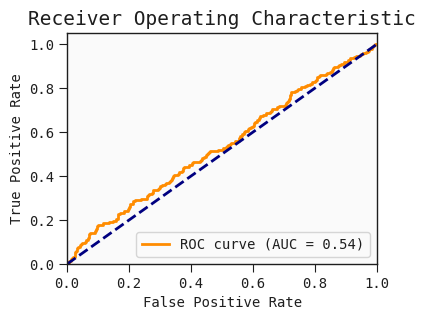

In [21]:
y_true_list_ql_omics = extract_results(results_ql_omics, 'y_true')
y_pred_prob_list_ql_omics= extract_results(results_ql_omics, 'y_pred_prob')
y_pred_list_ql_omics= extract_results(results_ql_omics, 'y_pred')
feature_selection_df_ql_omics= extract_results(results_ql_omics, 'feature_selection_df')
feature_sum_coef_df_ql_omics= extract_results(results_ql_omics, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics}, Median AUC: {median_auc_ql_omics}, IQR : {iqr_auc_ql_omics}, IQ1-IQ3: {iqr13_auc_ql_omics}") 
auc_plot(extract_results(results_ql_omics, 'y_true'), extract_results(results_ql_omics, 'y_pred_prob'))

#### QLattice-Female No feature selection

In [72]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omicsF, overall_auc_ql_omicsF, median_auc_ql_omicsF, iqr_auc_ql_omicsF, iqr13_auc_ql_omicsF = run_multiple_evaluations_parallel(model_omics_df_F, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.733811544991511, Median AUC: 0.7758913412563666, IQR : 0.10908319185059423, IQ1-IQ3: (0.6935483870967742, 0.8026315789473685)


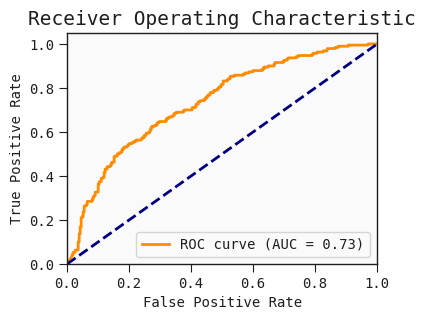

In [74]:
y_true_list_ql_omicsF = extract_results(results_ql_omicsF, 'y_true')
y_pred_prob_list_ql_omicsF = extract_results(results_ql_omicsF, 'y_pred_prob')
y_pred_list_ql_omicsF= extract_results(results_ql_omicsF, 'y_pred')
feature_selection_df_ql_omicsF= extract_results(results_ql_omicsF, 'feature_selection_df')
feature_sum_coef_df_ql_omicsF= extract_results(results_ql_omicsF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omicsF}, Median AUC: {median_auc_ql_omicsF}, IQR : {iqr_auc_ql_omicsF}, IQ1-IQ3: {iqr13_auc_ql_omicsF}") 
auc_plot(extract_results(results_ql_omicsF, 'y_true'), extract_results(results_ql_omicsF, 'y_pred_prob'))

#### QLattice-Male No feature selection

In [75]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omicsM, overall_auc_ql_omicsM, median_auc_ql_omicsM, iqr_auc_ql_omicsM, iqr13_auc_ql_omicsM = run_multiple_evaluations_parallel(model_omics_df_M, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.7468489583333333, Median AUC: 0.7682291666666667, IQR : 0.09928385416666663, IQ1-IQ3: (0.7063802083333334, 0.8056640625)


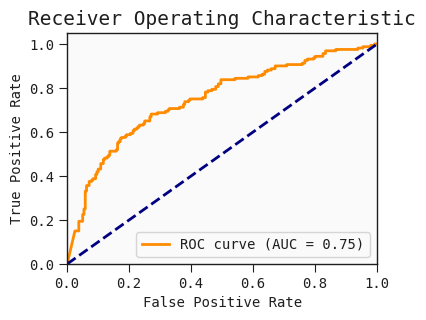

In [77]:
y_true_list_ql_omicsM = extract_results(results_ql_omicsM, 'y_true')
y_pred_prob_list_ql_omicsM = extract_results(results_ql_omicsM, 'y_pred_prob')
y_pred_list_ql_omicsM = extract_results(results_ql_omicsM, 'y_pred')
feature_selection_df_ql_omicsM = extract_results(results_ql_omicsM, 'feature_selection_df')
feature_sum_coef_df_ql_omicsM = extract_results(results_ql_omicsM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omicsM}, Median AUC: {median_auc_ql_omicsM}, IQR : {iqr_auc_ql_omicsM}, IQ1-IQ3: {iqr13_auc_ql_omicsM}") 
auc_plot(extract_results(results_ql_omicsM, 'y_true'), extract_results(results_ql_omicsM, 'y_pred_prob'))

## Omics + APOE4

In [21]:
################ OMICS + APOE4 ####################
model_omics_APOE4_df = omics_demo_normalise_df_no_missing.copy()
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_APOE4 = ['Demographic.Sex','APOE4']
omics_APOE4_lst = list((set(model_omics_APOE4_df.columns.to_list()) - set(demo_lst_full)) | set(omics_APOE4))
model_omics_df_APOE4 = model_omics_APOE4_df[omics_APOE4_lst]
print(len(model_omics_df_APOE4.columns))
model_omics_df_M_APOE4 = model_omics_df_APOE4[model_omics_df_APOE4['Demographic.Sex']==1]
model_omics_df_M_APOE4 = model_omics_df_M_APOE4.drop(['Demographic.Sex'], axis=1)
model_omics_df_F_APOE4 = model_omics_df_APOE4[model_omics_df_APOE4['Demographic.Sex']==0]
model_omics_df_F_APOE4 = model_omics_df_F_APOE4.drop(['Demographic.Sex'], axis=1)
# model_omics_df_APOE4 = model_omics_df_APOE4.drop(['Demographic.Sex'], axis=1)

1944


### Logistic Regression with Lasso

#### L1-Full No feature selection

In [94]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4, overall_auc_lr_omics_APOE4, median_auc_lr_omics_APOE4, iqr_auc_lr_omics_APOE4, iqr13_auc_lr_omics_APOE4 = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, l1, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (0.5, l1, saga)
test_auc           0.645741
Name: 5, dtype: object

params      (10, l1, liblinear)
test_auc               0.688704
Name: 10, dtype: object

params      (100, l1, liblinear)
test_auc                0.620833
Name: 12, dtype: object

params      (10, l1, liblinear)
test_auc               0.752963
Name: 10, dtype: object

...

params      (0.5, l1, liblinear)
test_auc                0.779907
Name: 4, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.566389
Name: 4, dtype: object

params      (100, l1, saga)
test_auc            0.56213
Name: 13, dtype: object

params      (0.5, l1, saga)
test_auc           0.604352
Name: 5, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.739907
Name: 4, dtype: object

Overall AUC: 0.4728181818181819, Median AUC: 0.4688311688311689, IQR : 0.04675324675324677, IQ1-IQ3: (0.44110389610389605, 0.4878571428571428)


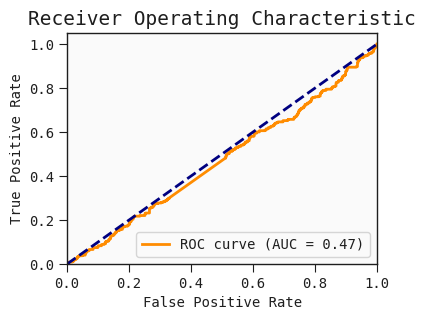

In [96]:
y_true_list_lr_omics_APOE4 = extract_results(results_lr_omics_APOE4, 'y_true')
y_pred_prob_list_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'y_pred_prob')
y_pred_list_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'y_pred')
feature_selection_df_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4}, Median AUC: {median_auc_lr_omics_APOE4}, IQR : {iqr_auc_lr_omics_APOE4}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4}") 
auc_plot(extract_results(results_lr_omics_APOE4, 'y_true'), extract_results(results_lr_omics_APOE4, 'y_pred_prob'))

#### L1-Female No feature selection

In [97]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4F, overall_auc_lr_omics_APOE4F, median_auc_lr_omics_APOE4F, iqr_auc_lr_omics_APOE4F, iqr13_auc_lr_omics_APOE4F = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (5, l1, liblinear)
test_auc              0.813333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.893333
Name: 8, dtype: object

params      (1, l1, saga)
test_auc         0.906667
Name: 7, dtype: object

params      (1, l1, liblinear)
test_auc              0.893333
Name: 6, dtype: object

params      (0.5, l1, saga)
test_auc           0.813333
Name: 5, dtype: object

...

params      (0.5, l1, liblinear)
test_auc                0.764167
Name: 4, dtype: object

params      (0.5, l1, saga)
test_auc           0.828333
Name: 5, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.920833
Name: 4, dtype: object

params      (100, l1, liblinear)
test_auc                0.748333
Name: 12, dtype: object

params      (0.5, l1, saga)
test_auc               0.92
Name: 5, dtype: object

Overall AUC: 0.7705263157894736, Median AUC: 0.7775891341256367, IQR : 0.028862478777589073, IQ1-IQ3: (0.7597623089983022, 0.7886247877758913)


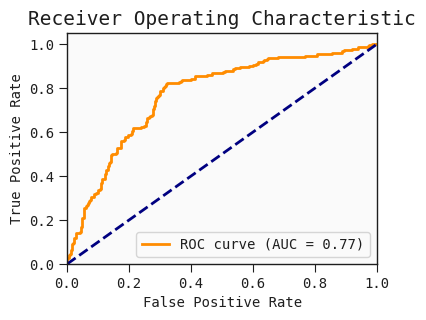

In [99]:
y_true_list_lr_omics_APOE4F = extract_results(results_lr_omics_APOE4F, 'y_true')
y_pred_prob_list_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'y_pred_prob')
y_pred_list_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'y_pred')
feature_selection_df_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4F}, Median AUC: {median_auc_lr_omics_APOE4F}, IQR : {iqr_auc_lr_omics_APOE4F}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4F}") 
auc_plot(extract_results(results_lr_omics_APOE4F, 'y_true'), extract_results(results_lr_omics_APOE4F, 'y_pred_prob'))

#### L1-Male No feature selection

In [100]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4M, overall_auc_lr_omics_APOE4M, median_auc_lr_omics_APOE4M, iqr_auc_lr_omics_APOE4M, iqr13_auc_lr_omics_APOE4M = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (5, l1, liblinear)
test_auc                  0.95
Name: 8, dtype: object

params      (10, l1, liblinear)
test_auc               0.783333
Name: 10, dtype: object

params      (5, l1, liblinear)
test_auc              0.683333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.933333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.883333
Name: 8, dtype: object

...

params      (5, l1, liblinear)
test_auc              0.933333
Name: 8, dtype: object

params      (10, l1, liblinear)
test_auc               0.722222
Name: 10, dtype: object

params      (100, l1, liblinear)
test_auc                0.833333
Name: 12, dtype: object

params      (1, l1, liblinear)
test_auc              0.908333
Name: 6, dtype: object

params      (10, l1, liblinear)
test_auc               0.738889
Name: 10, dtype: object

Overall AUC: 0.8283463541666667, Median AUC: 0.84765625, IQR : 0.04296875, IQ1-IQ3: (0.8229166666666666, 0.8658854166666666)


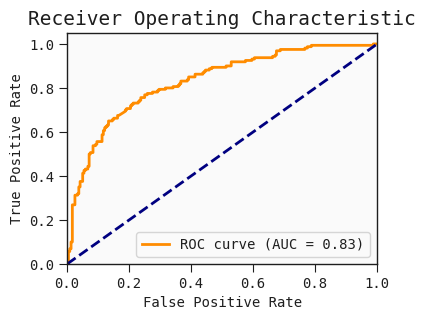

In [102]:
y_true_list_lr_omics_APOE4M = extract_results(results_lr_omics_APOE4M, 'y_true')
y_pred_prob_list_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'y_pred_prob')
y_pred_list_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'y_pred')
feature_selection_df_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4M}, Median AUC: {median_auc_lr_omics_APOE4M}, IQR : {iqr_auc_lr_omics_APOE4M}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4M}") 
auc_plot(extract_results(results_lr_omics_APOE4M, 'y_true'), extract_results(results_lr_omics_APOE4M, 'y_pred_prob'))

### Logistic Regression with Ridge 

#### L2-Full No feature selection

In [115]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4, overall_auc_lr2_omics_APOE4, median_auc_lr2_omics_APOE4, iqr_auc_lr2_omics_APOE4, iqr13_auc_lr2_omics_APOE4 = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (10, l2, liblinear)
test_auc               0.484444
Name: 10, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.437778
Name: 0, dtype: object

params      (1, l2, liblinear)
test_auc              0.550093
Name: 6, dtype: object

params      (0.5, l2, liblinear)
test_auc                 0.49213
Name: 4, dtype: object

params      (5, l2, liblinear)
test_auc               0.42963
Name: 8, dtype: object

...

params      (0.1, l2, liblinear)
test_auc                0.499907
Name: 2, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.578148
Name: 2, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.538241
Name: 4, dtype: object

params      (1, l2, liblinear)
test_auc              0.508796
Name: 6, dtype: object

params      (0.5, l2, saga)
test_auc           0.606296
Name: 5, dtype: object

Overall AUC: 0.4924727272727273, Median AUC: 0.5033766233766234, IQR : 0.045584415584415616, IQ1-IQ3: (0.47337662337662334, 0.518961038961039)


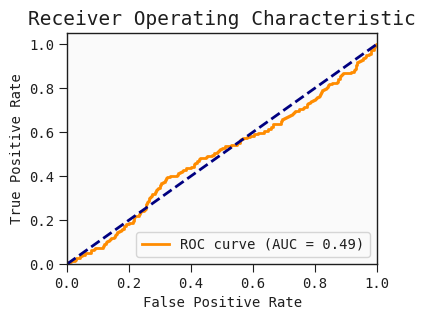

In [117]:
y_true_list_lr2_omics_APOE4 = extract_results(results_lr2_omics_APOE4, 'y_true')
y_pred_prob_list_lr2_omics_APOE4 = extract_results(results_lr2_omics_APOE4, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4 = extract_results(results_lr2_omics_APOE4, 'y_pred')
feature_selection_df_lr2_omics_APOE4 = extract_results(results_lr2_omics_APOE4, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4 = extract_results(results_lr2_omics_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4}, Median AUC: {median_auc_lr2_omics_APOE4}, IQR : {iqr_auc_lr2_omics_APOE4}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4}") 
auc_plot(extract_results(results_lr2_omics_APOE4, 'y_true'), extract_results(results_lr2_omics_APOE4, 'y_pred_prob'))

#### L2-Full RFE20

In [118]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_rfe, overall_auc_lr2_omics_APOE4_rfe, median_auc_lr2_omics_APOE4_rfe, iqr_auc_lr2_omics_APOE4_rfe, iqr13_auc_lr2_omics_APOE4_rfe = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, l2, liblinear)
test_auc                 0.699074
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                0.629167
Name: 12, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, liblinear)
test_auc              0.532407
Name: 8, dtype: object

Do RFE feature Selection
Do RFE feature Selection


params      (0.01, l2, liblinear)
test_auc                 0.599167
Name: 0, dtype: object

Do RFE feature Selection


Overall AUC: 0.46774025974025973, Median AUC: 0.46571428571428575, IQR : 0.03142857142857142, IQ1-IQ3: (0.4509090909090909, 0.48233766233766234)


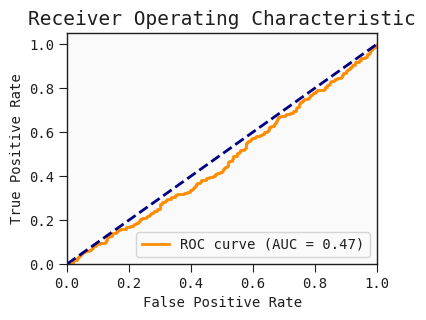

In [120]:
y_true_list_lr2_omics_APOE4_rfe = extract_results(results_lr2_omics_APOE4_rfe, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_rfe= extract_results(results_lr2_omics_APOE4_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_rfe= extract_results(results_lr2_omics_APOE4_rfe, 'y_pred')
feature_selection_df_lr2_omics_APOE4_rfe= extract_results(results_lr2_omics_APOE4_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_rfe= extract_results(results_lr2_omics_APOE4_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_rfe}, Median AUC: {median_auc_lr2_omics_APOE4_rfe}, IQR : {iqr_auc_lr2_omics_APOE4_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_rfe}") 
auc_plot(extract_results(results_lr2_omics_APOE4_rfe, 'y_true'), extract_results(results_lr2_omics_APOE4_rfe, 'y_pred_prob'))

#### L2-Full MRMR20

In [169]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_mrmr, overall_auc_lr2_omics_APOE4_mrmr, median_auc_lr2_omics_APOE4_mrmr, iqr_auc_lr2_omics_APOE4_mrmr, iqr13_auc_lr2_omics_APOE4_mrmr = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.04it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.46it/s]





 20%|██        | 4/20 [00:01<00:06,  2.51it/s]


 25%|██▌       | 5/20 [00:01<00:05,  2.73it/s]





 30%|███       | 6/20 [00:02<00:04,  2.98it/s]





 35%|███▌      | 7/20 [00:02<00:04,  3.14it/s]





 40%|████      | 8/20 [00:02<00:03,  3.01it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.18it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.29it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.46it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.33it/s]




 65%|██████▌   | 13/20 [00:04<00:02,  3.44it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.54it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.58it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.57it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.33it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.20it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.29it/s]



100%|██████████| 20

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:10,  1.69it/s]





 15%|█▌        | 3/20 [00:01<00:08,  2.12it/s]





 20%|██        | 4/20 [00:01<00:06,  2.46it/s]


 25%|██▌       | 5/20 [00:02<00:05,  2.68it/s]





 30%|███       | 6/20 [00:02<00:04,  2.93it/s]





 35%|███▌      | 7/20 [00:02<00:04,  3.06it/s]





 40%|████      | 8/20 [00:03<00:03,  3.26it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.21it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.34it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.07it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.05it/s]



 65%|██████▌   | 13/20 [00:04<00:02,  3.08it/s]







 70%|███████   | 14/20 [00:04<00:02,  2.92it/s]





 75%|███████▌  | 15/20 [00:05<00:01,  3.05it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.10it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.37it/s]





 90%|█████████ | 18/20 [00:06<00:00,  3.44it/s]



 95%|█████████▌| 19/20 [00:06<00:00,  3.37it/s]





100%|██████████| 2

Do MRMR feature selection
Do MRMR feature selection


...

Do MRMR feature selection


params      (100, l2, liblinear)
test_auc                0.392315
Name: 12, dtype: object

 75%|███████▌  | 15/20 [00:04<00:01,  3.11it/s]

Do MRMR feature selection





 80%|████████  | 16/20 [00:05<00:01,  2.28it/s]


 85%|████████▌ | 17/20 [00:05<00:01,  2.68it/s]


 90%|█████████ | 18/20 [00:06<00:00,  2.60it/s]


 95%|█████████▌| 19/20 [00:06<00:00,  2.78it/s]


100%|██████████| 20/20 [00:06<00:00,  3.01it/s]






















100%|██████████| 20/20 [00:06<00:00,  3.12it/s]



















100%|██████████| 20/20 [00:04<00:00,  4.34it/s]


100%|██████████| 20/20 [00:04<00:00,  4.51it/s]


Overall AUC: 0.4689558441558442, Median AUC: 0.45116883116883116, IQR : 0.044545454545454555, IQ1-IQ3: (0.43987012987012986, 0.4844155844155844)


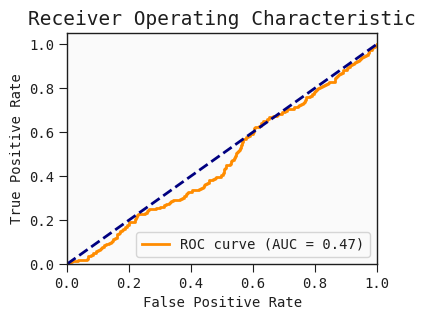

In [171]:
y_true_list_lr2_omics_APOE4_mrmr = extract_results(results_lr2_omics_APOE4_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_mrmr= extract_results(results_lr2_omics_APOE4_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_mrmr= extract_results(results_lr2_omics_APOE4_mrmr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_mrmr= extract_results(results_lr2_omics_APOE4_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_mrmr= extract_results(results_lr2_omics_APOE4_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_mrmr}, Median AUC: {median_auc_lr2_omics_APOE4_mrmr}, IQR : {iqr_auc_lr2_omics_APOE4_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_mrmr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_mrmr, 'y_true'), extract_results(results_lr2_omics_APOE4_mrmr, 'y_pred_prob'))

#### L2-Full correlation20

In [172]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_corr, overall_auc_lr2_omics_APOE4_corr, median_auc_lr2_omics_APOE4_corr, iqr_auc_lr2_omics_APOE4_corr, iqr13_auc_lr2_omics_APOE4_corr = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, l2, liblinear)
test_auc                 0.705648
Name: 0, dtype: object

Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.697593
Name: 12, dtype: object

params      (100, l2, liblinear)
test_auc                  0.5575
Name: 12, dtype: object

...

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.408148
Name: 12, dtype: object

params      (10, l2, saga)
test_auc          0.563704
Name: 11, dtype: object

params      (100, l2, liblinear)
test_auc                0.684167
Name: 12, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.46515324675324676, Median AUC: 0.4737662337662337, IQR : 0.026363636363636367, IQ1-IQ3: (0.45025974025974025, 0.4766233766233766)


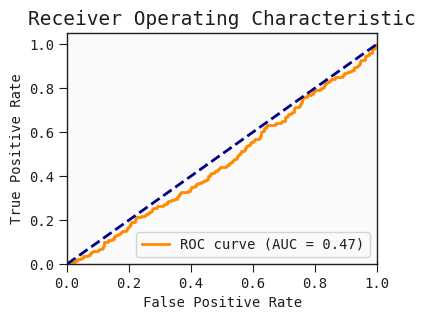

In [174]:
y_true_list_lr2_omics_APOE4_corr = extract_results(results_lr2_omics_APOE4_corr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_corr= extract_results(results_lr2_omics_APOE4_corr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_corr= extract_results(results_lr2_omics_APOE4_corr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_corr= extract_results(results_lr2_omics_APOE4_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_corr= extract_results(results_lr2_omics_APOE4_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_corr}, Median AUC: {median_auc_lr2_omics_APOE4_corr}, IQR : {iqr_auc_lr2_omics_APOE4_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_corr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_corr, 'y_true'), extract_results(results_lr2_omics_APOE4_corr, 'y_pred_prob'))

#### L2-Female No feature selection

In [175]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4F, overall_auc_lr2_omics_APOE4F, median_auc_lr2_omics_APOE4F, iqr_auc_lr2_omics_APOE4F, iqr13_auc_lr2_omics_APOE4F = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, l2, liblinear)
test_auc                     0.64
Name: 0, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.693333
Name: 0, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.613333
Name: 4, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.706667
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.746667
Name: 0, dtype: object

...

params      (5, l2, liblinear)
test_auc                0.7125
Name: 8, dtype: object

params      (100, l2, liblinear)
test_auc                  0.4475
Name: 12, dtype: object

params      (0.5, l2, saga)
test_auc           0.566667
Name: 5, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.669167
Name: 4, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.726667
Name: 4, dtype: object

Overall AUC: 0.6043123938879456, Median AUC: 0.6001697792869269, IQR : 0.05135823429541597, IQ1-IQ3: (0.5946519524617996, 0.6460101867572156)


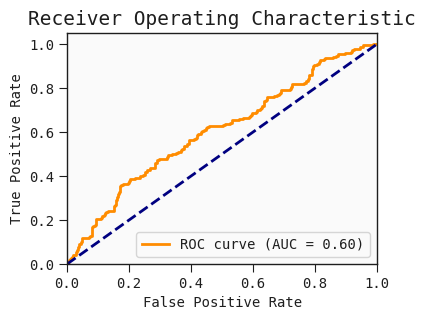

In [177]:
y_true_list_lr2_omics_APOE4F = extract_results(results_lr2_omics_APOE4F, 'y_true')
y_pred_prob_list_lr2_omics_APOE4F = extract_results(results_lr2_omics_APOE4F, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4F = extract_results(results_lr2_omics_APOE4F, 'y_pred')
feature_selection_df_lr2_omics_APOE4F = extract_results(results_lr2_omics_APOE4F, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4F = extract_results(results_lr2_omics_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4F}, Median AUC: {median_auc_lr2_omics_APOE4F}, IQR : {iqr_auc_lr2_omics_APOE4F}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4F}") 
auc_plot(extract_results(results_lr2_omics_APOE4F, 'y_true'), extract_results(results_lr2_omics_APOE4F, 'y_pred_prob'))

#### L2-Female RFE20

In [178]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4F_rfe, overall_auc_lr2_omics_APOE4F_rfe, median_auc_lr2_omics_APOE4F_rfe, iqr_auc_lr2_omics_APOE4F_rfe, iqr13_auc_lr2_omics_APOE4F_rfe = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, l2, liblinear)
test_auc               0.813333
Name: 10, dtype: object

Do RFE feature Selection


params      (0.1, l2, liblinear)
test_auc                0.813333
Name: 2, dtype: object

Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, l2, liblinear)
test_auc                    0.815
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, liblinear)
test_auc                 0.805
Name: 8, dtype: object

Do RFE feature Selection


Overall AUC: 0.7124108658743633, Median AUC: 0.7062818336162988, IQR : 0.05772495755517826, IQ1-IQ3: (0.700339558573854, 0.7580645161290323)


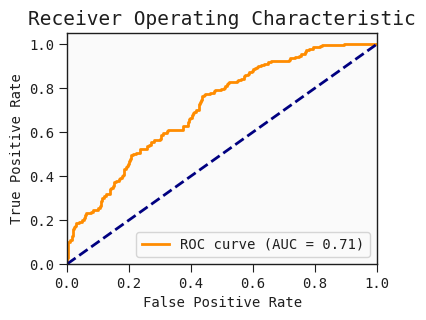

In [180]:
y_true_list_lr2_omics_APOE4F_rfe = extract_results(results_lr2_omics_APOE4F_rfe, 'y_true')
y_pred_prob_list_lr2_omics_APOE4F_rfe= extract_results(results_lr2_omics_APOE4F_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4F_rfe= extract_results(results_lr2_omics_APOE4F_rfe, 'y_pred')
feature_selection_df_lr2_omics_APOE4F_rfe= extract_results(results_lr2_omics_APOE4F_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4F_rfe= extract_results(results_lr2_omics_APOE4F_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4F_rfe}, Median AUC: {median_auc_lr2_omics_APOE4F_rfe}, IQR : {iqr_auc_lr2_omics_APOE4F_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4F_rfe}") 
auc_plot(extract_results(results_lr2_omics_APOE4F_rfe, 'y_true'), extract_results(results_lr2_omics_APOE4F_rfe, 'y_pred_prob'))

#### L2-Female MRMR20

In [181]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4F_mrmr, overall_auc_lr2_omics_APOE4F_mrmr, median_auc_lr2_omics_APOE4F_mrmr, iqr_auc_lr2_omics_APOE4F_mrmr, iqr13_auc_lr2_omics_APOE4F_mrmr = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:09,  1.87it/s]





 15%|█▌        | 3/20 [00:01<00:10,  1.60it/s]





 20%|██        | 4/20 [00:02<00:09,  1.69it/s]





 25%|██▌       | 5/20 [00:02<00:07,  1.94it/s]





 30%|███       | 6/20 [00:03<00:06,  2.26it/s]





 35%|███▌      | 7/20 [00:03<00:05,  2.51it/s]





 40%|████      | 8/20 [00:03<00:04,  2.70it/s]





 45%|████▌     | 9/20 [00:04<00:04,  2.68it/s]





 50%|█████     | 10/20 [00:04<00:03,  2.66it/s]





 55%|█████▌    | 11/20 [00:04<00:03,  2.82it/s]





 60%|██████    | 12/20 [00:05<00:02,  2.90it/s]





 65%|██████▌   | 13/20 [00:05<00:02,  3.14it/s]





 70%|███████   | 14/20 [00:05<00:01,  3.31it/s]




 75%|███████▌  | 15/20 [00:05<00:01,  3.48it/s]





 80%|████████  | 16/20 [00:06<00:01,  3.51it/s]





 85%|████████▌ | 17/20 [00:06<00:00,  3.10it/s]





 90%|█████████ | 18/20 [00:06<00:00,  3.17it/s]





 95%|█████████▌| 19/20 [00:07<00:00,  3.26it/s]





100%|█████████

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:06<00:00,  3.11it/s]


Do MRMR feature selection


...

params      (0.1, l2, liblinear)
test_auc                  0.7625
Name: 2, dtype: object

Do MRMR feature selection


 60%|██████    | 12/20 [00:03<00:02,  3.21it/s]

Do MRMR feature selection



 65%|██████▌   | 13/20 [00:03<00:02,  2.36it/s]


 70%|███████   | 14/20 [00:03<00:02,  2.90it/s]


 80%|████████  | 16/20 [00:04<00:01,  3.51it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.17it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  4.34it/s]


100%|██████████| 20/20 [00:05<00:00,  4.21it/s]

100%|██████████| 20/20 [00:05<00:00,  3.80it/s]































100%|██████████| 20/20 [00:03<00:00,  5.06it/s]

100%|██████████| 20/20 [00:03<00:00,  5.34it/s]




100%|██████████| 20/20 [00:03<00:00,  5.51it/s]


Overall AUC: 0.6864346349745332, Median AUC: 0.6901528013582343, IQR : 0.06876061120543298, IQ1-IQ3: (0.6595925297113752, 0.7283531409168081)


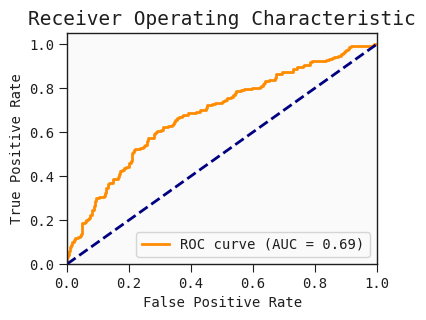

In [183]:
y_true_list_lr2_omics_APOE4F_mrmr = extract_results(results_lr2_omics_APOE4F_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4F_mrmr= extract_results(results_lr2_omics_APOE4F_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4F_mrmr= extract_results(results_lr2_omics_APOE4F_mrmr, 'y_pred')
feature_selection_df_lr2_omics_APOE4F_mrmr= extract_results(results_lr2_omics_APOE4F_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4F_mrmr= extract_results(results_lr2_omics_APOE4F_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4F_mrmr}, Median AUC: {median_auc_lr2_omics_APOE4F_mrmr}, IQR : {iqr_auc_lr2_omics_APOE4F_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4F_mrmr}") 
auc_plot(extract_results(results_lr2_omics_APOE4F_mrmr, 'y_true'), extract_results(results_lr2_omics_APOE4F_mrmr, 'y_pred_prob'))

#### L2-Female correlation20

In [184]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4F_corr, overall_auc_lr2_omics_APOE4F_corr, median_auc_lr2_omics_APOE4F_corr, iqr_auc_lr2_omics_APOE4F_corr, iqr13_auc_lr2_omics_APOE4F_corr = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.5, l2, liblinear)
test_auc                0.746667
Name: 4, dtype: object

params      (5, l2, liblinear)
test_auc              0.853333
Name: 8, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.813333
Name: 4, dtype: object

params      (0.5, l2, saga)
test_auc           0.733333
Name: 5, dtype: object

...

params      (100, l2, liblinear)
test_auc                  0.5125
Name: 12, dtype: object

Do Correlation-Based feature selection


params      (10, l2, liblinear)
test_auc               0.760833
Name: 10, dtype: object

params      (10, l2, liblinear)
test_auc               0.696667
Name: 10, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.7067402376910017, Median AUC: 0.7130730050933787, IQR : 0.05008488964346358, IQ1-IQ3: (0.6761460101867571, 0.7262308998302207)


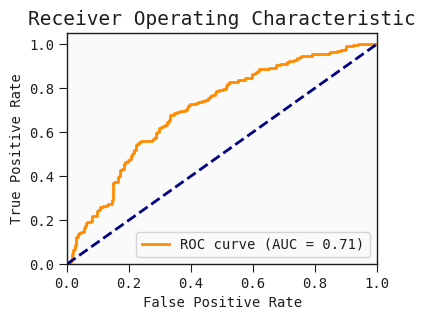

In [186]:
y_true_list_lr2_omics_APOE4F_corr = extract_results(results_lr2_omics_APOE4F_corr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4F_corr= extract_results(results_lr2_omics_APOE4F_corr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4F_corr= extract_results(results_lr2_omics_APOE4F_corr, 'y_pred')
feature_selection_df_lr2_omics_APOE4F_corr= extract_results(results_lr2_omics_APOE4F_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4F_corr= extract_results(results_lr2_omics_APOE4F_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4F_corr}, Median AUC: {median_auc_lr2_omics_APOE4F_corr}, IQR : {iqr_auc_lr2_omics_APOE4F_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4F_corr}") 
auc_plot(extract_results(results_lr2_omics_APOE4F_corr, 'y_true'), extract_results(results_lr2_omics_APOE4F_corr, 'y_pred_prob'))

#### L2-Male No Feature Selection

In [187]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4M, overall_auc_lr2_omics_APOE4M, median_auc_lr2_omics_APOE4M, iqr_auc_lr2_omics_APOE4M, iqr13_auc_lr2_omics_APOE4M = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (5, l2, liblinear)
test_auc              0.616667
Name: 8, dtype: object

params      (0.1, l2, liblinear)
test_auc                     0.4
Name: 2, dtype: object

params      (100, l2, liblinear)
test_auc                0.483333
Name: 12, dtype: object

params      (0.01, l2, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.433333
Name: 2, dtype: object

...

params      (1, l2, liblinear)
test_auc              0.319444
Name: 6, dtype: object

params      (5, l2, liblinear)
test_auc              0.502778
Name: 8, dtype: object

params      (0.01, l2, liblinear)
test_auc                    0.525
Name: 0, dtype: object

params      (0.5, l2, saga)
test_auc           0.383333
Name: 5, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.494444
Name: 0, dtype: object

Overall AUC: 0.4475, Median AUC: 0.453125, IQR : 0.050130208333333315, IQ1-IQ3: (0.43489583333333337, 0.4850260416666667)


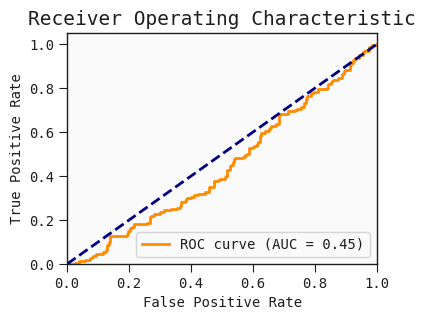

In [189]:
y_true_list_lr2_omics_APOE4M = extract_results(results_lr2_omics_APOE4M, 'y_true')
y_pred_prob_list_lr2_omics_APOE4M = extract_results(results_lr2_omics_APOE4M, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4M = extract_results(results_lr2_omics_APOE4M, 'y_pred')
feature_selection_df_lr2_omics_APOE4M = extract_results(results_lr2_omics_APOE4M, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4M = extract_results(results_lr2_omics_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4M}, Median AUC: {median_auc_lr2_omics_APOE4M}, IQR : {iqr_auc_lr2_omics_APOE4M}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4M}") 
auc_plot(extract_results(results_lr2_omics_APOE4M, 'y_true'), extract_results(results_lr2_omics_APOE4M, 'y_pred_prob'))

#### L2-Male RFE20

In [190]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4M_rfe, overall_auc_lr2_omics_APOE4M_rfe, median_auc_lr2_omics_APOE4M_rfe, iqr_auc_lr2_omics_APOE4M_rfe, iqr13_auc_lr2_omics_APOE4M_rfe = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                     0.6
Name: 12, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                   0.575
Name: 12, dtype: object

Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, liblinear)
test_auc              0.786111
Name: 8, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, l2, saga)
test_auc          0.583333
Name: 11, dtype: object

Do RFE feature Selection


Overall AUC: 0.7063020833333333, Median AUC: 0.7044270833333333, IQR : 0.06835937500000011, IQ1-IQ3: (0.6692708333333333, 0.7376302083333334)


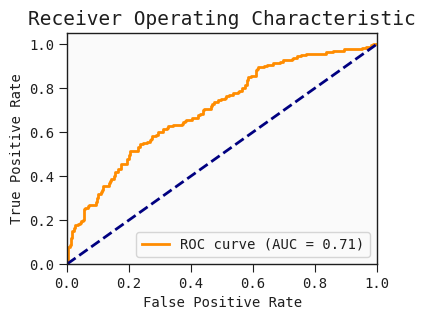

In [192]:
y_true_list_lr2_omics_APOE4M_rfe = extract_results(results_lr2_omics_APOE4M_rfe, 'y_true')
y_pred_prob_list_lr2_omics_APOE4M_rfe= extract_results(results_lr2_omics_APOE4M_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4M_rfe= extract_results(results_lr2_omics_APOE4M_rfe, 'y_pred')
feature_selection_df_lr2_omics_APOE4M_rfe= extract_results(results_lr2_omics_APOE4M_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4M_rfe= extract_results(results_lr2_omics_APOE4M_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4M_rfe}, Median AUC: {median_auc_lr2_omics_APOE4M_rfe}, IQR : {iqr_auc_lr2_omics_APOE4M_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4M_rfe}") 
auc_plot(extract_results(results_lr2_omics_APOE4M_rfe, 'y_true'), extract_results(results_lr2_omics_APOE4M_rfe, 'y_pred_prob'))

#### L2-Male MRMR20

In [193]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4M_mrmr, overall_auc_lr2_omics_APOE4M_mrmr, median_auc_lr2_omics_APOE4M_mrmr, iqr_auc_lr2_omics_APOE4M_mrmr, iqr13_auc_lr2_omics_APOE4M_mrmr = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.03it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.62it/s]





 20%|██        | 4/20 [00:01<00:05,  2.72it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.07it/s]





 30%|███       | 6/20 [00:02<00:04,  3.10it/s]





 35%|███▌      | 7/20 [00:02<00:04,  3.22it/s]









 40%|████      | 8/20 [00:02<00:03,  3.03it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.12it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.16it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.01it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.19it/s]





 65%|██████▌   | 13/20 [00:04<00:02,  3.26it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.33it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.45it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.50it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.35it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.40it/s]





100%|██████████| 20/20 [00:05<00:00,  3.44it/s]






100%|██████

Do MRMR feature selection


100%|██████████| 20/20 [00:05<00:00,  3.57it/s]



100%|██████████| 20/20 [00:05<00:00,  3.67it/s]

Do MRMR feature selectionDo MRMR feature selection



...

  0%|          | 0/20 [00:00<?, ?it/s]

100%|██████████| 20/20 [00:05<00:00,  3.34it/s]



 10%|█         | 2/20 [00:00<00:03,  4.82it/s]


params      (0.1, l2, liblinear)
test_auc                0.577778
Name: 2, dtype: object




 15%|█▌        | 3/20 [00:00<00:03,  4.48it/s]


Do MRMR feature selection







 20%|██        | 4/20 [00:01<00:05,  2.71it/s]





 25%|██▌       | 5/20 [00:01<00:04,  3.13it/s]





100%|██████████| 20/20 [00:06<00:00,  3.21it/s]

 30%|███       | 6/20 [00:01<00:04,  3.13it/s]

 35%|███▌      | 7/20 [00:02<00:03,  3.50it/s]


 40%|████      | 8/20 [00:02<00:03,  3.94it/s]


 45%|████▌     | 9/20 [00:02<00:02,  4.13it/s]


 50%|█████     | 10/20 [00:02<00:02,  4.19it/s]


 55%|█████▌    | 11/20 [00:02<00:02,  4.35it/s]


 60%|██████    | 12/20 [00:03<00:01,  4.40it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  4.40it/s]


 70%|███████   | 14/20 [00:03<00:01,  4.61it/s]


 75%|███████▌  | 15/20 [00:03<00:01,  4.48it/s]


 80%|████████  | 16/20 [00:03<00:00,  4.48it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.33it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.21it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.49it/s]


100%|██████████| 20/20 [00:04<00:00,  4.14it/s]




100%|██████████| 20/20 [00:04<00:00,  4.43it/s]


100%|██████████| 20/20 [00:03<00:00,  5.09it/

Overall AUC: 0.6589583333333333, Median AUC: 0.6471354166666667, IQR : 0.05143229166666674, IQ1-IQ3: (0.625, 0.6764322916666667)


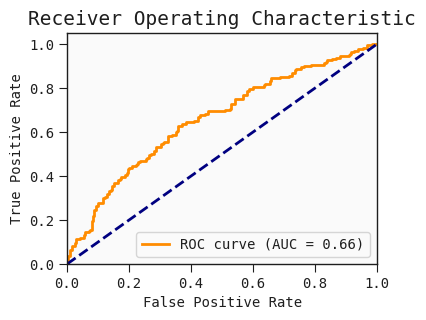

In [195]:
y_true_list_lr2_omics_APOE4M_mrmr = extract_results(results_lr2_omics_APOE4M_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4M_mrmr= extract_results(results_lr2_omics_APOE4M_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4M_mrmr= extract_results(results_lr2_omics_APOE4M_mrmr, 'y_pred')
feature_selection_df_lr2_omics_APOE4M_mrmr= extract_results(results_lr2_omics_APOE4M_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4M_mrmr= extract_results(results_lr2_omics_APOE4M_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4M_mrmr}, Median AUC: {median_auc_lr2_omics_APOE4M_mrmr}, IQR : {iqr_auc_lr2_omics_APOE4M_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4M_mrmr}") 
auc_plot(extract_results(results_lr2_omics_APOE4M_mrmr, 'y_true'), extract_results(results_lr2_omics_APOE4M_mrmr, 'y_pred_prob'))

#### L2-Male correlation20

In [196]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4M_corr, overall_auc_lr2_omics_APOE4M_corr, median_auc_lr2_omics_APOE4M_corr, iqr_auc_lr2_omics_APOE4M_corr, iqr13_auc_lr2_omics_APOE4M_corr = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                   0.675
Name: 12, dtype: object

Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.441667
Name: 12, dtype: object

Do Correlation-Based feature selection


...

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.747222
Name: 12, dtype: object

Do Correlation-Based feature selection


params      (5, l2, liblinear)
test_auc              0.663889
Name: 8, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.6742708333333334, Median AUC: 0.6770833333333334, IQR : 0.09895833333333326, IQ1-IQ3: (0.646484375, 0.7454427083333333)


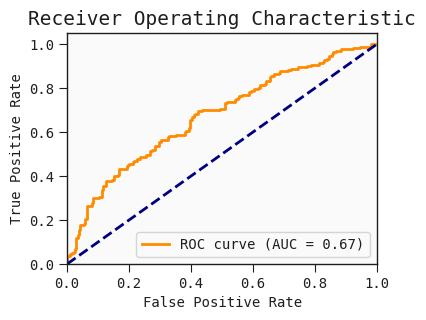

In [198]:
y_true_list_lr2_omics_APOE4M_corr = extract_results(results_lr2_omics_APOE4_corr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4M_corr= extract_results(results_lr2_omics_APOE4M_corr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4M_corr= extract_results(results_lr2_omics_APOE4M_corr, 'y_pred')
feature_selection_df_lr2_omics_APOE4M_corr= extract_results(results_lr2_omics_APOE4M_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4M_corr= extract_results(results_lr2_omics_APOE4M_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4M_corr}, Median AUC: {median_auc_lr2_omics_APOE4M_corr}, IQR : {iqr_auc_lr2_omics_APOE4M_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4M_corr}") 
auc_plot(extract_results(results_lr2_omics_APOE4M_corr, 'y_true'), extract_results(results_lr2_omics_APOE4M_corr, 'y_pred_prob'))

### SVM

#### SVM-Full No feature selection

In [199]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4, overall_auc_svm_omics_APOE4, median_auc_svm_omics_APOE4, iqr_auc_svm_omics_APOE4, iqr13_auc_svm_omics_APOE4 = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, linear, auto)
test_auc                0.508426
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.455648
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                 0.49787
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.455556
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.618426
Name: 0, dtype: object

...

params      (0.01, linear, auto)
test_auc                   0.535
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.417963
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.425278
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.401019
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.374815
Name: 0, dtype: object

Overall AUC: 0.44166753246753243, Median AUC: 0.43012987012987014, IQR : 0.06350649350649346, IQ1-IQ3: (0.4062987012987013, 0.4698051948051948)


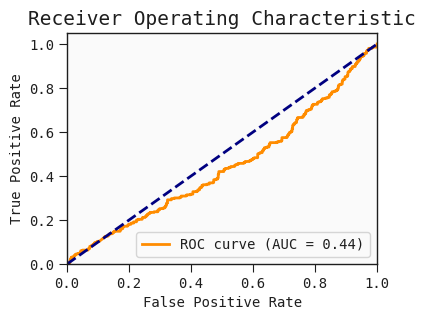

In [201]:
y_true_list_svm_omics_APOE4 = extract_results(results_svm_omics_APOE4, 'y_true')
y_pred_prob_list_svm_omics_APOE4 = extract_results(results_svm_omics_APOE4, 'y_pred_prob')
y_pred_list_svm_omics_APOE4 = extract_results(results_svm_omics_APOE4, 'y_pred')
feature_selection_df_svm_omics_APOE4 = extract_results(results_svm_omics_APOE4, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4 = extract_results(results_svm_omics_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4}, Median AUC: {median_auc_svm_omics_APOE4}, IQR : {iqr_auc_svm_omics_APOE4}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4}") 
auc_plot(extract_results(results_svm_omics_APOE4, 'y_true'), extract_results(results_svm_omics_APOE4, 'y_pred_prob'))

#### SVM-Full RFE20

In [202]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_rfe, overall_auc_svm_omics_APOE4_rfe, median_auc_svm_omics_APOE4_rfe, iqr_auc_svm_omics_APOE4_rfe, iqr13_auc_svm_omics_APOE4_rfe = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.588333
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.676481
Name: 4, dtype: object

Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.567685
Name: 0, dtype: object

Do RFE feature Selection


params      (0.1, linear, auto)
test_auc               0.547315
Name: 2, dtype: object

Do RFE feature Selection


Overall AUC: 0.486238961038961, Median AUC: 0.4828571428571429, IQR : 0.08818181818181825, IQ1-IQ3: (0.44207792207792207, 0.5302597402597403)


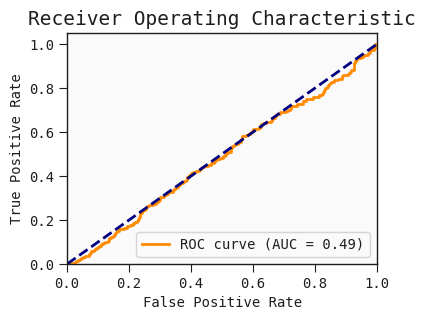

In [204]:
y_true_list_svm_omics_APOE4_rfe = extract_results(results_svm_omics_APOE4_rfe, 'y_true')
y_pred_prob_list_svm_omics_APOE4_rfe = extract_results(results_svm_omics_APOE4_rfe, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_rfe = extract_results(results_svm_omics_APOE4_rfe, 'y_pred')
feature_selection_df_svm_omics_APOE4_rfe = extract_results(results_svm_omics_APOE4_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_rfe = extract_results(results_svm_omics_APOE4_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_rfe}, Median AUC: {median_auc_svm_omics_APOE4_rfe}, IQR : {iqr_auc_svm_omics_APOE4_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_rfe}") 
auc_plot(extract_results(results_svm_omics_APOE4_rfe, 'y_true'), extract_results(results_svm_omics_APOE4_rfe, 'y_pred_prob'))

#### SVM-Full MRMR20

In [205]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_mrmr, overall_auc_svm_omics_APOE4_mrmr, median_auc_svm_omics_APOE4_mrmr, iqr_auc_svm_omics_APOE4_mrmr, iqr13_auc_svm_omics_APOE4_mrmr = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:11,  1.64it/s]





 15%|█▌        | 3/20 [00:01<00:08,  2.10it/s]



 20%|██        | 4/20 [00:02<00:09,  1.74it/s]





 25%|██▌       | 5/20 [00:02<00:08,  1.83it/s]





 30%|███       | 6/20 [00:03<00:06,  2.01it/s]




 35%|███▌      | 7/20 [00:03<00:05,  2.31it/s]





 40%|████      | 8/20 [00:03<00:04,  2.46it/s]





 45%|████▌     | 9/20 [00:04<00:04,  2.47it/s]





 50%|█████     | 10/20 [00:04<00:03,  2.64it/s]





 55%|█████▌    | 11/20 [00:05<00:03,  2.68it/s]





 60%|██████    | 12/20 [00:05<00:03,  2.39it/s]





 65%|██████▌   | 13/20 [00:05<00:02,  2.53it/s]





 70%|███████   | 14/20 [00:06<00:02,  2.68it/s]





 75%|███████▌  | 15/20 [00:06<00:01,  2.68it/s]





 80%|████████  | 16/20 [00:06<00:01,  2.80it/s]





 85%|████████▌ | 17/20 [00:07<00:01,  1.86it/s]





 90%|█████████ | 18/20 [00:08<00:00,  2.03it/s]





 95%|█████████▌| 19/20 [00:08<00:00,  2.26it/s]





100%|██████████|

Do MRMR feature selection



100%|██████████| 20/20 [00:08<00:00,  2.31it/s]


100%|██████████| 20/20 [00:08<00:00,  2.39it/s]



100%|██████████| 20/20 [00:08<00:00,  2.48it/s]

Do MRMR feature selection
Do MRMR feature selection


...

 85%|████████▌ | 17/20 [00:04<00:00,  3.20it/s]





 60%|██████    | 12/20 [00:03<00:02,  2.91it/s]





 65%|██████▌   | 13/20 [00:03<00:02,  3.05it/s]

100%|██████████| 20/20 [00:05<00:00,  3.45it/s]



 70%|███████   | 14/20 [00:03<00:01,  3.17it/s]


params      (1, linear, auto)
test_auc             0.558148
Name: 4, dtype: object

 75%|███████▌  | 15/20 [00:04<00:01,  3.58it/s]


Do MRMR feature selection


 85%|████████▌ | 17/20 [00:04<00:00,  3.90it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.21it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.36it/s]


100%|██████████| 20/20 [00:05<00:00,  3.90it/s]





























100%|██████████| 20/20 [00:04<00:00,  4.64it/s]




100%|██████████| 20/20 [00:03<00:00,  5.48it/s]






100%|██████████| 20/20 [00:02<00:00,  7.08it/s]


Overall AUC: 0.4565090909090909, Median AUC: 0.4475324675324675, IQR : 0.08038961038961034, IQ1-IQ3: (0.42480519480519485, 0.5051948051948052)


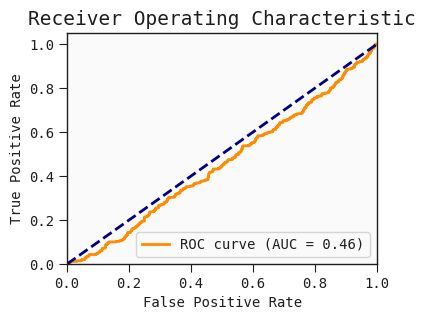

In [207]:
y_true_list_svm_omics_APOE4_mrmr = extract_results(results_svm_omics_APOE4_mrmr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_mrmr = extract_results(results_svm_omics_APOE4_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_mrmr = extract_results(results_svm_omics_APOE4_mrmr, 'y_pred')
feature_selection_df_svm_omics_APOE4_mrmr = extract_results(results_svm_omics_APOE4_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_mrmr = extract_results(results_svm_omics_APOE4_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_mrmr}, Median AUC: {median_auc_svm_omics_APOE4_mrmr}, IQR : {iqr_auc_svm_omics_APOE4_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_mrmr}") 
auc_plot(extract_results(results_svm_omics_APOE4_mrmr, 'y_true'), extract_results(results_svm_omics_APOE4_mrmr, 'y_pred_prob'))

#### SVM-Full correlation20

In [208]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_corr, overall_auc_svm_omics_APOE4_corr, median_auc_svm_omics_APOE4_corr, iqr_auc_svm_omics_APOE4_corr, iqr13_auc_svm_omics_APOE4_corr = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selectionDo Correlation-Based feature selection
Do Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.582315
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.686204
Name: 2, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.593241
Name: 0, dtype: object

...

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc             0.541759
Name: 4, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.663056
Name: 0, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.4727792207792208, Median AUC: 0.46285714285714286, IQR : 0.04272727272727278, IQ1-IQ3: (0.44597402597402597, 0.48870129870129875)


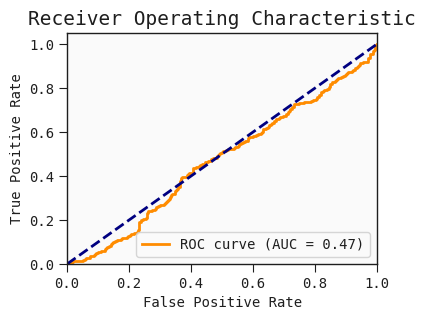

In [210]:
y_true_list_svm_omics_APOE4_corr = extract_results(results_svm_omics_APOE4_corr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_corr = extract_results(results_svm_omics_APOE4_corr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_corr = extract_results(results_svm_omics_APOE4_corr, 'y_pred')
feature_selection_df_svm_omics_APOE4_corr = extract_results(results_svm_omics_APOE4_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_corr = extract_results(results_svm_omics_APOE4_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_corr}, Median AUC: {median_auc_svm_omics_APOE4_corr}, IQR : {iqr_auc_svm_omics_APOE4_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_corr}") 
auc_plot(extract_results(results_svm_omics_APOE4_corr, 'y_true'), extract_results(results_svm_omics_APOE4_corr, 'y_pred_prob'))

#### SVM-Female No feature selection

In [211]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4F, overall_auc_svm_omics_APOE4F, median_auc_svm_omics_APOE4F, iqr_auc_svm_omics_APOE4F, iqr13_auc_svm_omics_APOE4F = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.1, linear, auto)
test_auc               0.653333
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.493333
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.68
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.426667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.48
Name: 2, dtype: object

...

params      (0.1, linear, auto)
test_auc                  0.725
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.361667
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                  0.4875
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc                 0.7525
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.540833
Name: 2, dtype: object

Overall AUC: 0.4761460101867573, Median AUC: 0.46477079796264853, IQR : 0.06112054329371813, IQ1-IQ3: (0.4350594227504244, 0.49617996604414255)


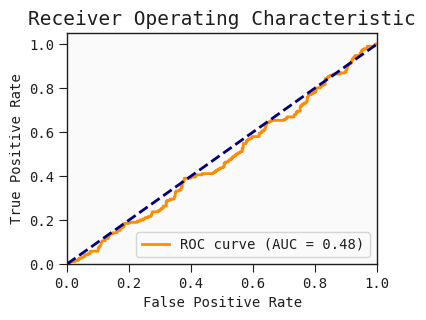

In [213]:
y_true_list_svm_omics_APOE4F = extract_results(results_svm_omics_APOE4F, 'y_true')
y_pred_prob_list_svm_omics_APOE4F = extract_results(results_svm_omics_APOE4F, 'y_pred_prob')
y_pred_list_svm_omics_APOE4F = extract_results(results_svm_omics_APOE4F, 'y_pred')
feature_selection_df_svm_omics_APOE4F = extract_results(results_svm_omics_APOE4F, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4F = extract_results(results_svm_omics_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4F}, Median AUC: {median_auc_svm_omics_APOE4F}, IQR : {iqr_auc_svm_omics_APOE4F}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4F}") 
auc_plot(extract_results(results_svm_omics_APOE4F, 'y_true'), extract_results(results_svm_omics_APOE4F, 'y_pred_prob'))

#### SVM-Female RFE20

In [214]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4F_rfe, overall_auc_svm_omics_APOE4F_rfe, median_auc_svm_omics_APOE4F_rfe, iqr_auc_svm_omics_APOE4F_rfe, iqr13_auc_svm_omics_APOE4F_rfe = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.733333
Name: 4, dtype: object

Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.826667
Name: 4, dtype: object

Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, linear, auto)
test_auc                 0.7525
Name: 2, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, linear, auto)
test_auc               0.775833
Name: 2, dtype: object

Do RFE feature Selection


Overall AUC: 0.7001528013582343, Median AUC: 0.7258064516129032, IQR : 0.06876061120543298, IQ1-IQ3: (0.6854838709677419, 0.7542444821731749)


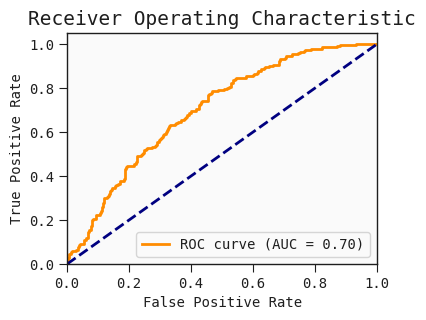

In [216]:
y_true_list_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'y_true')
y_pred_prob_list_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'y_pred_prob')
y_pred_list_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'y_pred')
feature_selection_df_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4F_rfe}, Median AUC: {median_auc_svm_omics_APOE4F_rfe}, IQR : {iqr_auc_svm_omics_APOE4F_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4F_rfe}") 
auc_plot(extract_results(results_svm_omics_APOE4F_rfe, 'y_true'), extract_results(results_svm_omics_APOE4F_rfe, 'y_pred_prob'))

#### SVM-Female MRMR20

In [217]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4F_mrmr, overall_auc_svm_omics_APOE4F_mrmr, median_auc_svm_omics_APOE4F_mrmr, iqr_auc_svm_omics_APOE4F_mrmr, iqr13_auc_svm_omics_APOE4F_mrmr = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:12,  1.49it/s]


 15%|█▌        | 3/20 [00:01<00:08,  1.91it/s]





 20%|██        | 4/20 [00:01<00:07,  2.27it/s]





 25%|██▌       | 5/20 [00:02<00:06,  2.44it/s]





 30%|███       | 6/20 [00:02<00:05,  2.57it/s]





 35%|███▌      | 7/20 [00:03<00:04,  2.64it/s]





 40%|████      | 8/20 [00:03<00:05,  2.19it/s]





 45%|████▌     | 9/20 [00:03<00:04,  2.45it/s]





 50%|█████     | 10/20 [00:04<00:03,  2.62it/s]





 55%|█████▌    | 11/20 [00:04<00:03,  2.80it/s]





 60%|██████    | 12/20 [00:05<00:03,  2.40it/s]





 65%|██████▌   | 13/20 [00:05<00:02,  2.55it/s]





 70%|███████   | 14/20 [00:05<00:02,  2.74it/s]





 75%|███████▌  | 15/20 [00:06<00:01,  2.94it/s]





 80%|████████  | 16/20 [00:06<00:01,  3.02it/s]





 85%|████████▌ | 17/20 [00:06<00:00,  3.17it/s]



 90%|█████████ | 18/20 [00:06<00:00,  3.12it/s]




 95%|█████████▌| 19/20 [00:07<00:00,  3.36it/s]





100%|██████████| 20

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection




100%|██████████| 20/20 [00:06<00:00,  2.87it/s]





Do MRMR feature selection


...

  0%|          | 0/20 [00:00<?, ?it/s]




 10%|█         | 2/20 [00:00<00:03,  5.37it/s]





 15%|█▌        | 3/20 [00:00<00:03,  4.57it/s]





 20%|██        | 4/20 [00:00<00:04,  3.96it/s]





 25%|██▌       | 5/20 [00:01<00:04,  3.31it/s]





 30%|███       | 6/20 [00:01<00:03,  3.60it/s]





 35%|███▌      | 7/20 [00:01<00:03,  3.43it/s]





 40%|████      | 8/20 [00:02<00:03,  3.43it/s]





 45%|████▌     | 9/20 [00:02<00:02,  3.79it/s]





 50%|█████     | 10/20 [00:02<00:02,  3.62it/s]





 55%|█████▌    | 11/20 [00:02<00:02,  3.49it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.64it/s]





 65%|██████▌   | 13/20 [00:03<00:02,  3.39it/s]


 70%|███████   | 14/20 [00:03<00:01,  3.36it/s]




params      (0.1, linear, auto)
test_auc               0.735833
Name: 2, dtype: object


 75%|███████▌  | 15/20 [00:04<00:01,  3.60it/s]


100%|██████████| 20/20 [00:06<00:00,  3.22it/s]


Do MRMR feature selection



 80%|████████  | 16/20 [00:04<00:01,  3.20it/s]


100%|██████████| 20/20 [00:05<00:00,  3.40it/s]



 90%|█████████ | 18/20 [00:05<00:00,  3.36it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  3.43it/s]


100%|██████████| 20/20 [00:05<00:00,  3.61it/s]




100%|██████████| 20/20 [00:05<00:00,  3.79it/s]














100%|██████████| 20/20 [00:01<00:00, 10.60it/s]


Overall AUC: 0.6997962648556875, Median AUC: 0.699490662139219, IQR : 0.08149405772495755, IQ1-IQ3: (0.6557724957555178, 0.7372665534804753)


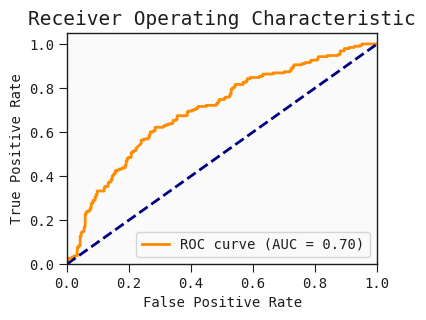

In [219]:
y_true_list_svm_omics_APOE4F_mrmr = extract_results(results_svm_omics_APOE4F_mrmr, 'y_true')
y_pred_prob_list_svm_omics_APOE4F_mrmr = extract_results(results_svm_omics_APOE4F_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4F_mrmr = extract_results(results_svm_omics_APOE4F_mrmr, 'y_pred')
feature_selection_df_svm_omics_APOE4F_mrmr = extract_results(results_svm_omics_APOE4F_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4F_mrmr = extract_results(results_svm_omics_APOE4F_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4F_mrmr}, Median AUC: {median_auc_svm_omics_APOE4F_mrmr}, IQR : {iqr_auc_svm_omics_APOE4F_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4F_mrmr}") 
auc_plot(extract_results(results_svm_omics_APOE4F_mrmr, 'y_true'), extract_results(results_svm_omics_APOE4F_mrmr, 'y_pred_prob'))

#### SVM-Female correlation20

In [220]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4F_corr, overall_auc_svm_omics_APOE4F_corr, median_auc_svm_omics_APOE4F_corr, iqr_auc_svm_omics_APOE4F_corr, iqr13_auc_svm_omics_APOE4F_corr = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc                 0.84
Name: 4, dtype: object

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc                 0.76
Name: 4, dtype: object

params      (0.1, linear, auto)
test_auc               0.693333
Name: 2, dtype: object

...

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, linear, auto)
test_auc              0.749167
Name: 6, dtype: object

params      (0.1, linear, auto)
test_auc                 0.6425
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.698333
Name: 0, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.7049066213921902, Median AUC: 0.6876061120543293, IQR : 0.05560271646859083, IQ1-IQ3: (0.6706281833616299, 0.7262308998302207)


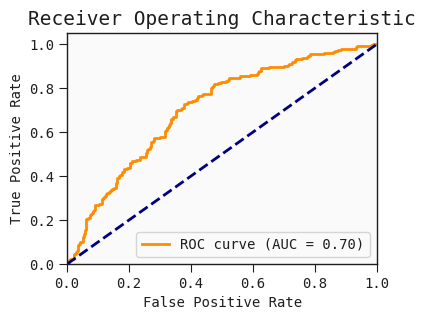

In [222]:
y_true_list_svm_omics_APOE4F_corr = extract_results(results_svm_omics_APOE4F_corr, 'y_true')
y_pred_prob_list_svm_omics_APOE4F_corr = extract_results(results_svm_omics_APOE4F_corr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4F_corr = extract_results(results_svm_omics_APOE4F_corr, 'y_pred')
feature_selection_df_svm_omics_APOE4F_corr = extract_results(results_svm_omics_APOE4F_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4F_corr = extract_results(results_svm_omics_APOE4F_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4F_corr}, Median AUC: {median_auc_svm_omics_APOE4F_corr}, IQR : {iqr_auc_svm_omics_APOE4F_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4F_corr}") 
auc_plot(extract_results(results_svm_omics_APOE4F_corr, 'y_true'), extract_results(results_svm_omics_APOE4F_corr, 'y_pred_prob'))

#### SVM-Male No feature selection

In [223]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4M, overall_auc_svm_omics_APOE4M, median_auc_svm_omics_APOE4M, iqr_auc_svm_omics_APOE4M, iqr13_auc_svm_omics_APOE4M = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.1, linear, auto)
test_auc               0.516667
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.616667
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.533333
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.433333
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.566667
Name: 2, dtype: object

...

params      (0.1, linear, auto)
test_auc                  0.675
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.713889
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.441667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.488889
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.369444
Name: 0, dtype: object

Overall AUC: 0.4539322916666667, Median AUC: 0.46354166666666663, IQR : 0.14257812499999994, IQ1-IQ3: (0.3997395833333333, 0.5423177083333333)


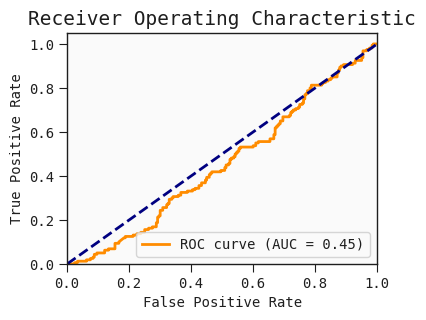

In [225]:
y_true_list_svm_omics_APOE4M = extract_results(results_svm_omics_APOE4M, 'y_true')
y_pred_prob_list_svm_omics_APOE4M = extract_results(results_svm_omics_APOE4M, 'y_pred_prob')
y_pred_list_svm_omics_APOE4M = extract_results(results_svm_omics_APOE4M, 'y_pred')
feature_selection_df_svm_omics_APOE4M = extract_results(results_svm_omics_APOE4M, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4M = extract_results(results_svm_omics_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4M}, Median AUC: {median_auc_svm_omics_APOE4M}, IQR : {iqr_auc_svm_omics_APOE4M}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4M}") 
auc_plot(extract_results(results_svm_omics_APOE4M, 'y_true'), extract_results(results_svm_omics_APOE4M, 'y_pred_prob'))

#### SVM-Male RFE20

In [226]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4F_rfe, overall_auc_svm_omics_APOE4F_rfe, median_auc_svm_omics_APOE4F_rfe, iqr_auc_svm_omics_APOE4F_rfe, iqr13_auc_svm_omics_APOE4F_rfe = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.658333
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.758333
Name: 4, dtype: object

Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, linear, auto)
test_auc                 0.575
Name: 6, dtype: object

Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.744444
Name: 4, dtype: object

Do RFE feature Selection


Overall AUC: 0.6394270833333333, Median AUC: 0.6158854166666667, IQR : 0.10677083333333326, IQ1-IQ3: (0.5833333333333334, 0.6901041666666666)


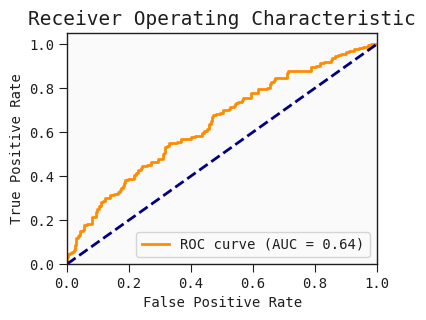

In [228]:
y_true_list_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'y_true')
y_pred_prob_list_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'y_pred_prob')
y_pred_list_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'y_pred')
feature_selection_df_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4F_rfe = extract_results(results_svm_omics_APOE4F_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4F_rfe}, Median AUC: {median_auc_svm_omics_APOE4F_rfe}, IQR : {iqr_auc_svm_omics_APOE4F_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4F_rfe}") 
auc_plot(extract_results(results_svm_omics_APOE4F_rfe, 'y_true'), extract_results(results_svm_omics_APOE4F_rfe, 'y_pred_prob'))

#### SVM-Male MRMR20

In [229]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4M_mrmr, overall_auc_svm_omics_APOE4M_mrmr, median_auc_svm_omics_APOE4M_mrmr, iqr_auc_svm_omics_APOE4M_mrmr, iqr13_auc_svm_omics_APOE4M_mrmr = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:10,  1.75it/s]





 15%|█▌        | 3/20 [00:01<00:07,  2.30it/s]


 20%|██        | 4/20 [00:02<00:08,  1.93it/s]





 25%|██▌       | 5/20 [00:02<00:06,  2.30it/s]





 30%|███       | 6/20 [00:02<00:05,  2.47it/s]





 35%|███▌      | 7/20 [00:03<00:05,  2.54it/s]





 40%|████      | 8/20 [00:03<00:04,  2.84it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.14it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.22it/s]





 55%|█████▌    | 11/20 [00:04<00:03,  2.95it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.04it/s]





 65%|██████▌   | 13/20 [00:04<00:02,  3.21it/s]





 70%|███████   | 14/20 [00:05<00:01,  3.32it/s]





 75%|███████▌  | 15/20 [00:05<00:01,  3.40it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.48it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.54it/s]





 90%|█████████ | 18/20 [00:06<00:00,  3.58it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.49it/s]





100%|██████████|

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection





 10%|█         | 2/20 [00:00<00:06,  2.65it/s]





 15%|█▌        | 3/20 [00:01<00:05,  3.31it/s]


 20%|██        | 4/20 [00:01<00:04,  3.62it/s]


Do MRMR feature selection


...

 40%|████      | 8/20 [00:02<00:04,  2.95it/s]



 45%|████▌     | 9/20 [00:02<00:03,  3.44it/s]



 50%|█████     | 10/20 [00:02<00:02,  3.79it/s]


 55%|█████▌    | 11/20 [00:02<00:02,  4.25it/s]


 60%|██████    | 12/20 [00:03<00:01,  4.48it/s]



 65%|██████▌   | 13/20 [00:03<00:01,  4.69it/s]



 70%|███████   | 14/20 [00:03<00:01,  4.75it/s]



 75%|███████▌  | 15/20 [00:03<00:01,  4.52it/s]



 80%|████████  | 16/20 [00:03<00:00,  4.47it/s]



 85%|████████▌ | 17/20 [00:04<00:00,  4.32it/s]



params      (0.1, linear, auto)
test_auc               0.730556
Name: 2, dtype: object

 90%|█████████ | 18/20 [00:04<00:00,  4.65it/s][A

Do MRMR feature selection





 95%|█████████▌| 19/20 [00:04<00:00,  3.62it/s]


100%|██████████| 20/20 [00:05<00:00,  3.97it/s]









100%|██████████| 20/20 [00:04<00:00,  4.33it/s]




















100%|██████████| 20/20 [00:04<00:00,  4.90it/s]






100%|██████████| 20/20 [00:02<00:00,  8.78it/s]


Overall AUC: 0.61203125, Median AUC: 0.6145833333333334, IQR : 0.13606770833333348, IQ1-IQ3: (0.5442708333333333, 0.6803385416666667)


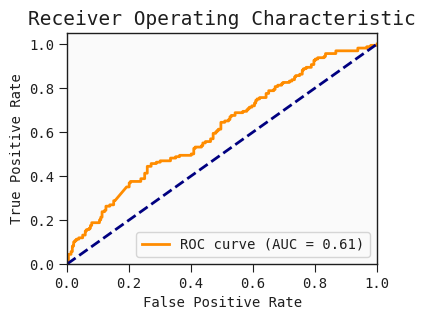

In [231]:
y_true_list_svm_omics_APOE4M_mrmr = extract_results(results_svm_omics_APOE4M_mrmr, 'y_true')
y_pred_prob_list_svm_omics_APOE4M_mrmr = extract_results(results_svm_omics_APOE4M_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4M_mrmr = extract_results(results_svm_omics_APOE4M_mrmr, 'y_pred')
feature_selection_df_svm_omics_APOE4M_mrmr = extract_results(results_svm_omics_APOE4M_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4M_mrmr = extract_results(results_svm_omics_APOE4M_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4M_mrmr}, Median AUC: {median_auc_svm_omics_APOE4M_mrmr}, IQR : {iqr_auc_svm_omics_APOE4M_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4M_mrmr}") 
auc_plot(extract_results(results_svm_omics_APOE4M_mrmr, 'y_true'), extract_results(results_svm_omics_APOE4M_mrmr, 'y_pred_prob'))

#### SVM-Male correlation20

In [232]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4M_corr, overall_auc_svm_omics_APOE4M_corr, median_auc_svm_omics_APOE4M_corr, iqr_auc_svm_omics_APOE4M_corr, iqr13_auc_svm_omics_APOE4M_corr = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.658333
Name: 0, dtype: object

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc                  0.7
Name: 4, dtype: object

params      (10, linear, auto)
test_auc                 0.675
Name: 6, dtype: object

...

params      (10, linear, auto)
test_auc                 0.575
Name: 6, dtype: object

params      (1, linear, auto)
test_auc             0.691667
Name: 4, dtype: object

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc             0.669444
Name: 4, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.605625, Median AUC: 0.59765625, IQR : 0.11718750000000011, IQ1-IQ3: (0.5052083333333333, 0.6223958333333334)


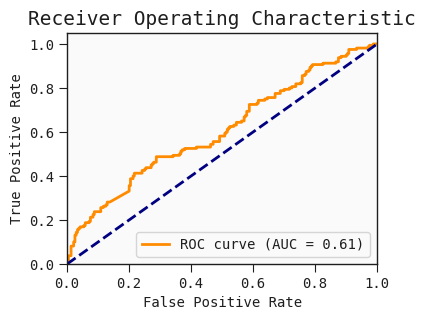

In [234]:
y_true_list_svm_omics_APOE4M_corr = extract_results(results_svm_omics_APOE4M_corr, 'y_true')
y_pred_prob_list_svm_omics_APOE4M_corr = extract_results(results_svm_omics_APOE4M_corr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4M_corr = extract_results(results_svm_omics_APOE4M_corr, 'y_pred')
feature_selection_df_svm_omics_APOE4M_corr = extract_results(results_svm_omics_APOE4M_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4M_corr = extract_results(results_svm_omics_APOE4M_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4M_corr}, Median AUC: {median_auc_svm_omics_APOE4M_corr}, IQR : {iqr_auc_svm_omics_APOE4M_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4M_corr}") 
auc_plot(extract_results(results_svm_omics_APOE4M_corr, 'y_true'), extract_results(results_svm_omics_APOE4M_corr, 'y_pred_prob'))

### RF

#### RF-Full No feature selection

In [235]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_APOE4, overall_auc_rf_omics_APOE4, median_auc_rf_omics_APOE4, iqr_auc_rf_omics_APOE4, iqr13_auc_rf_omics_APOE4 = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (50, 5, 2, 2)
test_auc         0.563426
Name: 16, dtype: object

params      (5, 5, 10, 2)
test_auc         0.487593
Name: 6, dtype: object

params      (5, 5, 2, 2)
test_auc        0.548333
Name: 4, dtype: object

params      (5, 5, 2, 2)
test_auc        0.514861
Name: 4, dtype: object

params      (500, 3, 2, 4)
test_auc          0.570556
Name: 37, dtype: object

...

params      (50, 5, 2, 2)
test_auc         0.554259
Name: 16, dtype: object

params      (5, 5, 2, 2)
test_auc         0.51963
Name: 4, dtype: object

params      (100, None, 10, 2)
test_auc              0.603981
Name: 34, dtype: object

params      (50, 3, 2, 2)
test_auc         0.535556
Name: 12, dtype: object

params      (100, None, 2, 4)
test_auc             0.683056
Name: 33, dtype: object

Overall AUC: 0.4866571428571429, Median AUC: 0.5046753246753246, IQR : 0.13194805194805193, IQ1-IQ3: (0.4181818181818182, 0.5501298701298701)


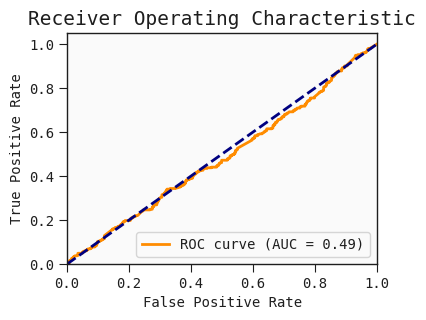

In [237]:
y_true_list_rf_omics_APOE4 = extract_results(results_rf_omics_APOE4, 'y_true')
y_pred_prob_list_rf_omics_APOE4 = extract_results(results_rf_omics_APOE4, 'y_pred_prob')
y_pred_list_rf_omics_APOE4 = extract_results(results_rf_omics_APOE4, 'y_pred')
feature_selection_df_rf_omics_APOE4 = extract_results(results_rf_omics_APOE4, 'feature_selection_df')
feature_sum_coef_df_rf_omics_APOE4= extract_results(results_rf_omics_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_APOE4}, Median AUC: {median_auc_rf_omics_APOE4}, IQR : {iqr_auc_rf_omics_APOE4}, IQ1-IQ3: {iqr13_auc_rf_omics_APOE4}") 
auc_plot(extract_results(results_rf_omics_APOE4, 'y_true'), extract_results(results_rf_omics_APOE4, 'y_pred_prob'))

#### RF-Female No feature selection

In [238]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_APOE4F, overall_auc_rf_omics_APOE4F, median_auc_rf_omics_APOE4F, iqr_auc_rf_omics_APOE4F, iqr13_auc_rf_omics_APOE4F = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (50, 5, 2, 2)
test_auc         0.733333
Name: 16, dtype: object

params      (50, 5, 10, 4)
test_auc          0.733333
Name: 19, dtype: object

params      (500, None, 10, 4)
test_auc                   0.6
Name: 47, dtype: object

params      (500, None, 10, 4)
test_auc              0.626667
Name: 47, dtype: object

params      (50, 3, 2, 4)
test_auc         0.733333
Name: 13, dtype: object

...

params      (500, None, 2, 2)
test_auc             0.736667
Name: 44, dtype: object

params      (50, 3, 2, 2)
test_auc         0.656667
Name: 12, dtype: object

params      (100, 3, 2, 2)
test_auc          0.710833
Name: 24, dtype: object

params      (50, 5, 10, 4)
test_auc          0.566667
Name: 19, dtype: object

params      (5, 5, 2, 4)
test_auc            0.71
Name: 5, dtype: object

Overall AUC: 0.6406366723259763, Median AUC: 0.6511035653650254, IQR : 0.04095925297113756, IQ1-IQ3: (0.6235144312393888, 0.6644736842105263)


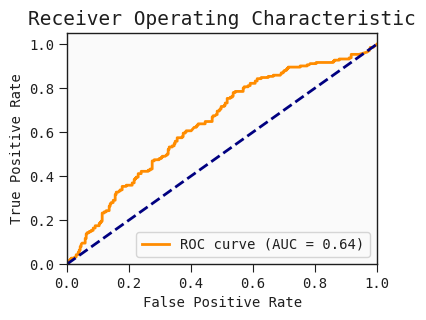

In [240]:
y_true_list_rf_omics_APOE4F = extract_results(results_rf_omics_APOE4F, 'y_true')
y_pred_prob_list_rf_omics_APOE4F = extract_results(results_rf_omics_APOE4F, 'y_pred_prob')
y_pred_list_rf_omics_APOE4F = extract_results(results_rf_omics_APOE4F, 'y_pred')
feature_selection_df_rf_omics_APOE4F = extract_results(results_rf_omics_APOE4F, 'feature_selection_df')
feature_sum_coef_df_rf_omics_APOE4F = extract_results(results_rf_omics_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_APOE4F}, Median AUC: {median_auc_rf_omics_APOE4F}, IQR : {iqr_auc_rf_omics_APOE4F}, IQ1-IQ3: {iqr13_auc_rf_omics_APOE4F}") 
auc_plot(extract_results(results_rf_omics_APOE4F, 'y_true'), extract_results(results_rf_omics_APOE4F, 'y_pred_prob'))

#### RF-Male No feature selection

In [241]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_APOE4M, overall_auc_rf_omics_APOE4M, median_auc_rf_omics_APOE4M, iqr_auc_rf_omics_APOE4M, iqr13_auc_rf_omics_APOE4M = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (50, 5, 10, 2)
test_auc          0.683333
Name: 18, dtype: object

params      (5, 3, 2, 2)
test_auc        0.633333
Name: 0, dtype: object

params      (5, 3, 2, 2)
test_auc        0.454167
Name: 0, dtype: object

params      (100, 3, 2, 2)
test_auc          0.533333
Name: 24, dtype: object

params      (5, 3, 10, 2)
test_auc           0.4375
Name: 2, dtype: object

...

params      (50, 5, 10, 2)
test_auc          0.483333
Name: 18, dtype: object

params      (5, 3, 2, 2)
test_auc        0.526389
Name: 0, dtype: object

params      (5, 5, 2, 4)
test_auc        0.393056
Name: 5, dtype: object

params      (5, 5, 2, 4)
test_auc             0.6
Name: 5, dtype: object

params      (5, 3, 2, 2)
test_auc        0.606944
Name: 0, dtype: object

Overall AUC: 0.38, Median AUC: 0.353515625, IQR : 0.09602864583333343, IQ1-IQ3: (0.33170572916666663, 0.42773437500000006)


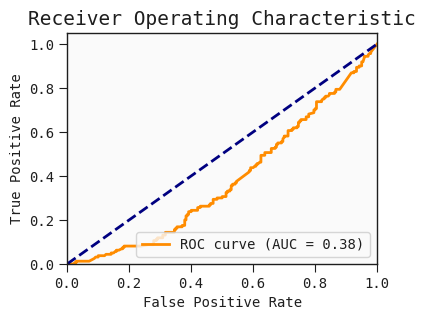

In [243]:
y_true_list_rf_omics_APOE4M = extract_results(results_rf_omics_APOE4M, 'y_true')
y_pred_prob_list_rf_omics_APOE4M = extract_results(results_rf_omics_APOE4M, 'y_pred_prob')
y_pred_list_rf_omics_APOE4M = extract_results(results_rf_omics_APOE4M, 'y_pred')
feature_selection_df_rf_omics_APOE4M = extract_results(results_rf_omics_APOE4M, 'feature_selection_df')
feature_sum_coef_df_rf_omics_APOE4M = extract_results(results_rf_omics_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_APOE4M}, Median AUC: {median_auc_rf_omics_APOE4M}, IQR : {iqr_auc_rf_omics_APOE4M}, IQ1-IQ3: {iqr13_auc_rf_omics_APOE4M}") 
auc_plot(extract_results(results_rf_omics_APOE4M, 'y_true'), extract_results(results_rf_omics_APOE4M, 'y_pred_prob'))

### QLattice

#### QLattice-Full No feature selection

In [18]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_APOE4, overall_auc_ql_omics_APOE4, median_auc_ql_omics_APOE4, iqr_auc_ql_omics_APOE4, iqr13_auc_ql_omics_APOE4 = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.5281324675324675, Median AUC: 0.5155844155844156, IQR : 0.10357142857142854, IQ1-IQ3: (0.4751298701298702, 0.5787012987012987)


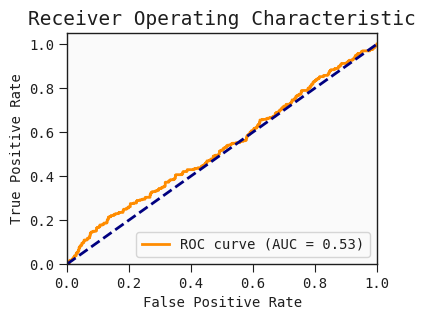

In [20]:
y_true_list_ql_omics_APOE4 = extract_results(results_ql_omics_APOE4, 'y_true')
y_pred_prob_list_ql_omics_APOE4 = extract_results(results_ql_omics_APOE4, 'y_pred_prob')
y_pred_list_ql_omics_APOE4 = extract_results(results_ql_omics_APOE4, 'y_pred')
feature_selection_df_ql_omics_APOE4 = extract_results(results_ql_omics_APOE4, 'feature_selection_df')
feature_sum_coef_df_ql_omics_APOE4 = extract_results(results_ql_omics_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_APOE4}, Median AUC: {median_auc_ql_omics_APOE4}, IQR : {iqr_auc_ql_omics_APOE4}, IQ1-IQ3: {iqr13_auc_ql_omics_APOE4}") 
auc_plot(extract_results(results_ql_omics_APOE4, 'y_true'), extract_results(results_ql_omics_APOE4, 'y_pred_prob'))

#### QLattice-Female No feature selection

In [22]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_APOE4F, overall_auc_ql_omics_APOE4F, median_auc_ql_omics_APOE4F, iqr_auc_ql_omics_APOE4F, iqr13_auc_ql_omics_APOE4F = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.7325127334465196, Median AUC: 0.7423599320882852, IQR : 0.07724957555178269, IQ1-IQ3: (0.7181663837011885, 0.7954159592529711)


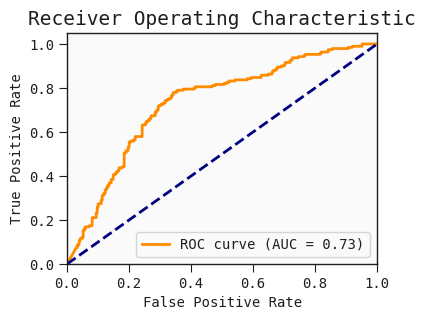

In [24]:
y_true_list_ql_omics_APOE4F = extract_results(results_ql_omics_APOE4F, 'y_true')
y_pred_prob_list_ql_omics_APOE4F = extract_results(results_ql_omics_APOE4F, 'y_pred_prob')
y_pred_list_ql_omics_APOE4F= extract_results(results_ql_omics_APOE4F, 'y_pred')
feature_selection_df_ql_omics_APOE4F= extract_results(results_ql_omics_APOE4F, 'feature_selection_df')
feature_sum_coef_df_ql_omics_APOE4F= extract_results(results_ql_omics_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_APOE4F}, Median AUC: {median_auc_ql_omics_APOE4F}, IQR : {iqr_auc_ql_omics_APOE4F}, IQ1-IQ3: {iqr13_auc_ql_omics_APOE4F}") 
auc_plot(extract_results(results_ql_omics_APOE4F, 'y_true'), extract_results(results_ql_omics_APOE4F, 'y_pred_prob'))

#### QLattice-Male No feature selection

In [25]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_APOE4M, overall_auc_ql_omics_APOE4M, median_auc_ql_omics_APOE4M, iqr_auc_ql_omics_APOE4M, iqr13_auc_ql_omics_APOE4M = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.7519010416666667, Median AUC: 0.7486979166666667, IQR : 0.03678385416666674, IQ1-IQ3: (0.73046875, 0.7672526041666667)


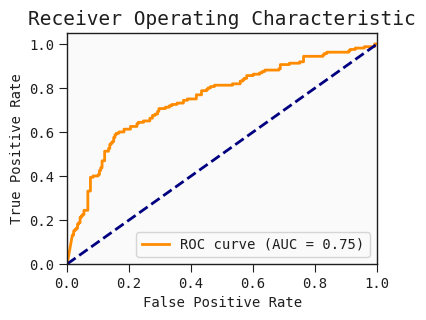

In [27]:
y_true_list_ql_omics_APOE4M = extract_results(results_ql_omics_APOE4M, 'y_true')
y_pred_prob_list_ql_omics_APOE4M = extract_results(results_ql_omics_APOE4M, 'y_pred_prob')
y_pred_list_ql_omics_APOE4M = extract_results(results_ql_omics_APOE4M, 'y_pred')
feature_selection_df_ql_omics_APOE4M = extract_results(results_ql_omics_APOE4M, 'feature_selection_df')
feature_sum_coef_df_ql_omics_APOE4M = extract_results(results_ql_omics_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_APOE4M}, Median AUC: {median_auc_ql_omics_APOE4M}, IQR : {iqr_auc_ql_omics_APOE4M}, IQ1-IQ3: {iqr13_auc_ql_omics_APOE4M}") 
auc_plot(extract_results(results_ql_omics_APOE4M, 'y_true'), extract_results(results_ql_omics_APOE4M, 'y_pred_prob'))

## Omics+Demo

In [17]:
################ OMICS + Demo ####################
model_omics_df = omics_demo_normalise_df_no_missing.copy()
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_demo = ['Demographic.Sex','Demographic.Years.of.Education.Exact','Age']
omics_demo_lst = list((set(model_omics_df.columns.to_list()) - set(demo_lst_full)) | set(omics_demo))
model_omics_df_demo = model_omics_df[omics_demo_lst]
print(len(model_omics_df_demo.columns))
model_omics_df_M_demo = model_omics_df_demo[model_omics_df_demo['Demographic.Sex']==1]
model_omics_df_M_demo = model_omics_df_M_demo.drop(['Demographic.Sex'], axis=1)
model_omics_df_F_demo = model_omics_df_demo[model_omics_df_demo['Demographic.Sex']==0]
model_omics_df_F_demo = model_omics_df_F_demo.drop(['Demographic.Sex'], axis=1)
# model_omics_df_demo = model_omics_df_demo.drop(['Demographic.Sex'], axis=1)

1944


### Logistic Regression with Lasso

#### L1-Full No feature selection

In [104]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_demo, overall_auc_lr_omics_demo, median_auc_lr_omics_demo, iqr_auc_lr_omics_demo, iqr13_auc_lr_omics_demo = run_multiple_evaluations_parallel(model_omics_df_demo, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (10, l1, liblinear)
test_auc               0.659722
Name: 10, dtype: object

params      (10, l1, liblinear)
test_auc               0.618611
Name: 10, dtype: object

params      (1, l1, liblinear)
test_auc               0.62037
Name: 6, dtype: object

params      (0.01, l1, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (5, l1, liblinear)
test_auc               0.71537
Name: 8, dtype: object

...

params      (0.5, l1, liblinear)
test_auc                0.544167
Name: 4, dtype: object

params      (1, l1, liblinear)
test_auc              0.750833
Name: 6, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.726574
Name: 4, dtype: object

params      (100, l1, saga)
test_auc            0.59713
Name: 13, dtype: object

params      (100, l1, saga)
test_auc            0.56213
Name: 13, dtype: object

Overall AUC: 0.47652987012987014, Median AUC: 0.47103896103896103, IQR : 0.07188311688311683, IQ1-IQ3: (0.4420779220779221, 0.513961038961039)


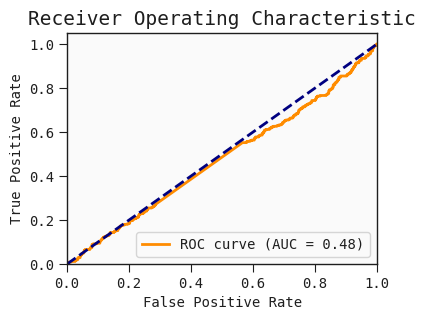

In [106]:
y_true_list_lr_omics_demo = extract_results(results_lr_omics_demo, 'y_true')
y_pred_prob_list_lr_omics_demo = extract_results(results_lr_omics_demo, 'y_pred_prob')
y_pred_list_lr_omics_demo = extract_results(results_lr_omics_demo, 'y_pred')
feature_selection_df_lr_omics_demo = extract_results(results_lr_omics_demo, 'feature_selection_df')
feature_sum_coef_df_lr_omics_demo = extract_results(results_lr_omics_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_demo}, Median AUC: {median_auc_lr_omics_demo}, IQR : {iqr_auc_lr_omics_demo}, IQ1-IQ3: {iqr13_auc_lr_omics_demo}") 
auc_plot(extract_results(results_lr_omics_demo, 'y_true'), extract_results(results_lr_omics_demo, 'y_pred_prob'))

#### L1-Female No feature selection

In [107]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_demoF, overall_auc_lr_omics_demoF, median_auc_lr_omics_demoF, iqr_auc_lr_omics_demoF, iqr13_auc_lr_omics_demoF = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, l1, saga)
test_auc         0.866667
Name: 7, dtype: object

params      (5, l1, liblinear)
test_auc              0.893333
Name: 8, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.826667
Name: 4, dtype: object

params      (1, l1, liblinear)
test_auc              0.906667
Name: 6, dtype: object

params      (0.5, l1, saga)
test_auc               0.84
Name: 5, dtype: object

...

params      (0.5, l1, saga)
test_auc           0.840833
Name: 5, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.920833
Name: 4, dtype: object

params      (0.5, l1, saga)
test_auc             0.7775
Name: 5, dtype: object

params      (100, l1, liblinear)
test_auc                0.814167
Name: 12, dtype: object

params      (0.5, l1, saga)
test_auc               0.92
Name: 5, dtype: object

Overall AUC: 0.772376910016978, Median AUC: 0.765704584040747, IQR : 0.08191850594227501, IQ1-IQ3: (0.7440577249575552, 0.8259762308998302)


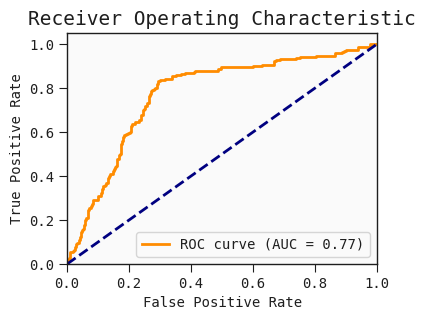

In [109]:
y_true_list_lr_omics_demoF = extract_results(results_lr_omics_demoF, 'y_true')
y_pred_prob_list_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'y_pred_prob')
y_pred_list_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'y_pred')
feature_selection_df_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'feature_selection_df')
feature_sum_coef_df_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_demoF}, Median AUC: {median_auc_lr_omics_demoF}, IQR : {iqr_auc_lr_omics_demoF}, IQ1-IQ3: {iqr13_auc_lr_omics_demoF}") 
auc_plot(extract_results(results_lr_omics_demoF, 'y_true'), extract_results(results_lr_omics_demoF, 'y_pred_prob'))

#### L1-Male No feature selection

In [110]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_demoM, overall_auc_lr_omics_demoM, median_auc_lr_omics_demoM, iqr_auc_lr_omics_demoM, iqr13_auc_lr_omics_demoM = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (5, l1, liblinear)
test_auc              0.883333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.883333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc                  0.95
Name: 8, dtype: object

params      (100, l1, liblinear)
test_auc                0.641667
Name: 12, dtype: object

params      (5, l1, liblinear)
test_auc                   0.7
Name: 8, dtype: object

...

params      (10, l1, liblinear)
test_auc               0.697222
Name: 10, dtype: object

params      (5, l1, liblinear)
test_auc              0.869444
Name: 8, dtype: object

params      (1, l1, liblinear)
test_auc              0.741667
Name: 6, dtype: object

params      (1, l1, liblinear)
test_auc              0.908333
Name: 6, dtype: object

params      (10, l1, liblinear)
test_auc                  0.875
Name: 10, dtype: object

Overall AUC: 0.8169140625, Median AUC: 0.8229166666666666, IQR : 0.07063802083333337, IQ1-IQ3: (0.7913411458333334, 0.8619791666666667)


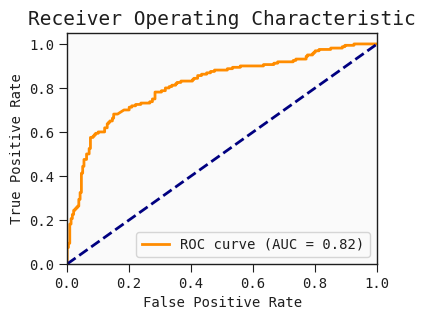

In [112]:
y_true_list_lr_omics_demoM = extract_results(results_lr_omics_demoM, 'y_true')
y_pred_prob_list_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'y_pred_prob')
y_pred_list_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'y_pred')
feature_selection_df_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'feature_selection_df')
feature_sum_coef_df_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_demoM}, Median AUC: {median_auc_lr_omics_demoM}, IQR : {iqr_auc_lr_omics_demoM}, IQ1-IQ3: {iqr13_auc_lr_omics_demoM}") 
auc_plot(extract_results(results_lr_omics_demoM, 'y_true'), extract_results(results_lr_omics_demoM, 'y_pred_prob'))

### Logistic Regression with Ridge

#### L2-Full No feature selection

In [255]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demo, overall_auc_lr2_omics_demo, median_auc_lr2_omics_demo, iqr_auc_lr2_omics_demo, iqr13_auc_lr2_omics_demo = run_multiple_evaluations_parallel(model_omics_df_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (10, l2, liblinear)
test_auc               0.488426
Name: 10, dtype: object

params      (1, l2, liblinear)
test_auc              0.483519
Name: 6, dtype: object

params      (100, l2, liblinear)
test_auc                0.417778
Name: 12, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.432778
Name: 0, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.541204
Name: 4, dtype: object

...

params      (0.01, l2, liblinear)
test_auc                 0.482778
Name: 0, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.566759
Name: 0, dtype: object

params      (5, l2, liblinear)
test_auc              0.508519
Name: 8, dtype: object

params      (5, l2, liblinear)
test_auc              0.516019
Name: 8, dtype: object

params      (5, l2, saga)
test_auc         0.601574
Name: 9, dtype: object

Overall AUC: 0.4882597402597403, Median AUC: 0.4846753246753247, IQR : 0.030129870129870062, IQ1-IQ3: (0.46532467532467536, 0.4954545454545454)


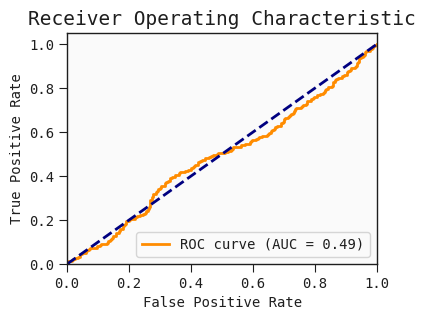

In [257]:
y_true_list_lr2_omics_demo = extract_results(results_lr2_omics_demo, 'y_true')
y_pred_prob_list_lr2_omics_demo = extract_results(results_lr2_omics_demo, 'y_pred_prob')
y_pred_list_lr2_omics_demo = extract_results(results_lr2_omics_demo, 'y_pred')
feature_selection_df_lr2_omics_demo = extract_results(results_lr2_omics_demo, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demo = extract_results(results_lr2_omics_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demo}, Median AUC: {median_auc_lr2_omics_demo}, IQR : {iqr_auc_lr2_omics_demo}, IQ1-IQ3: {iqr13_auc_lr2_omics_demo}") 
auc_plot(extract_results(results_lr2_omics_demo, 'y_true'), extract_results(results_lr2_omics_demo, 'y_pred_prob'))

#### L2-Full RFE20

In [258]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demo_rfe, overall_auc_lr2_omics_demo_rfe, median_auc_lr2_omics_demo_rfe, iqr_auc_lr2_omics_demo_rfe, iqr13_auc_lr2_omics_demo_rfe = run_multiple_evaluations_parallel(model_omics_df_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, liblinear)
test_auc              0.629167
Name: 8, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, l2, liblinear)
test_auc                0.475741
Name: 2, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                0.578889
Name: 12, dtype: object

Do RFE feature Selection


params      (10, l2, saga)
test_auc           0.53287
Name: 11, dtype: object

Do RFE feature Selection


Overall AUC: 0.5009246753246752, Median AUC: 0.5054545454545455, IQR : 0.04116883116883108, IQ1-IQ3: (0.4828571428571429, 0.524025974025974)


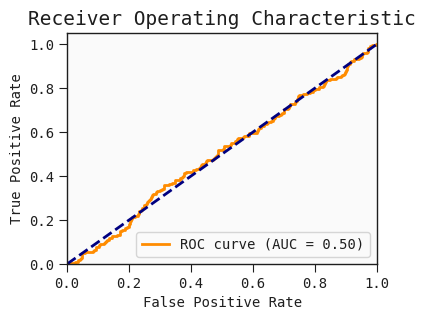

In [260]:
y_true_list_lr2_omics_demo_rfe = extract_results(results_lr2_omics_demo_rfe, 'y_true')
y_pred_prob_list_lr2_omics_demo_rfe= extract_results(results_lr2_omics_demo_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_demo_rfe= extract_results(results_lr2_omics_demo_rfe, 'y_pred')
feature_selection_df_lr2_omics_demo_rfe= extract_results(results_lr2_omics_demo_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demo_rfe= extract_results(results_lr2_omics_demo_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demo_rfe}, Median AUC: {median_auc_lr2_omics_demo_rfe}, IQR : {iqr_auc_lr2_omics_demo_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_demo_rfe}") 
auc_plot(extract_results(results_lr2_omics_demo_rfe, 'y_true'), extract_results(results_lr2_omics_demo_rfe, 'y_pred_prob'))

#### L2-Full MRMR20

In [261]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demo_mrmr, overall_auc_lr2_omics_demo_mrmr, median_auc_lr2_omics_demo_mrmr, iqr_auc_lr2_omics_demo_mrmr, iqr13_auc_lr2_omics_demo_mrmr = run_multiple_evaluations_parallel(model_omics_df_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:13,  1.33it/s]





 15%|█▌        | 3/20 [00:01<00:09,  1.81it/s]





 20%|██        | 4/20 [00:02<00:07,  2.19it/s]





 25%|██▌       | 5/20 [00:02<00:06,  2.46it/s]





 30%|███       | 6/20 [00:02<00:05,  2.65it/s]





 35%|███▌      | 7/20 [00:03<00:04,  2.76it/s]





 40%|████      | 8/20 [00:03<00:04,  2.91it/s]





 45%|████▌     | 9/20 [00:03<00:03,  2.99it/s]





 50%|█████     | 10/20 [00:04<00:03,  2.51it/s]





 55%|█████▌    | 11/20 [00:04<00:03,  2.28it/s]





 60%|██████    | 12/20 [00:05<00:03,  2.36it/s]





 65%|██████▌   | 13/20 [00:05<00:02,  2.46it/s]





 70%|███████   | 14/20 [00:05<00:02,  2.49it/s]





 75%|███████▌  | 15/20 [00:06<00:01,  2.64it/s]





 80%|████████  | 16/20 [00:06<00:01,  2.60it/s]





 85%|████████▌ | 17/20 [00:07<00:01,  2.37it/s]





 90%|█████████ | 18/20 [00:07<00:00,  2.42it/s]





 95%|█████████▌| 19/20 [00:07<00:00,  2.49it/s]





100%|████████

Do MRMR feature selection
Do MRMR feature selection





100%|██████████| 20/20 [00:07<00:00,  2.71it/s]


Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


...

 60%|██████    | 12/20 [00:04<00:02,  2.77it/s]

params      (1, l2, liblinear)
test_auc              0.636574
Name: 6, dtype: object

params      (100, l2, liblinear)
test_auc                0.500648
Name: 12, dtype: object

Do MRMR feature selection
Do MRMR feature selection


 70%|███████   | 14/20 [00:06<00:03,  1.55it/s]


 75%|███████▌  | 15/20 [00:06<00:02,  1.91it/s]


 80%|████████  | 16/20 [00:06<00:01,  2.34it/s]


 85%|████████▌ | 17/20 [00:06<00:01,  2.80it/s]


 90%|█████████ | 18/20 [00:07<00:00,  3.13it/s]


 95%|█████████▌| 19/20 [00:07<00:00,  2.47it/s]


100%|██████████| 20/20 [00:07<00:00,  2.53it/s]




































100%|██████████| 20/20 [00:06<00:00,  2.90it/s]



100%|██████████| 20/20 [00:05<00:00,  3.43it/s]


Overall AUC: 0.4749454545454545, Median AUC: 0.4638961038961039, IQR : 0.0587012987012987, IQ1-IQ3: (0.4388311688311688, 0.4975324675324675)


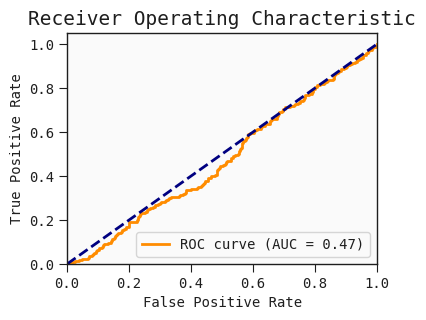

In [263]:
y_true_list_lr2_omics_demo_mrmr = extract_results(results_lr2_omics_demo_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_demo_mrmr= extract_results(results_lr2_omics_demo_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_demo_mrmr= extract_results(results_lr2_omics_demo_mrmr, 'y_pred')
feature_selection_df_lr2_omics_demo_mrmr= extract_results(results_lr2_omics_demo_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demo_mrmr= extract_results(results_lr2_omics_demo_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demo_mrmr}, Median AUC: {median_auc_lr2_omics_demo_mrmr}, IQR : {iqr_auc_lr2_omics_demo_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_demo_mrmr}") 
auc_plot(extract_results(results_lr2_omics_demo_mrmr, 'y_true'), extract_results(results_lr2_omics_demo_mrmr, 'y_pred_prob'))

#### L2-Full correlation20

In [264]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demo_corr, overall_auc_lr2_omics_demo_corr, median_auc_lr2_omics_demo_corr, iqr_auc_lr2_omics_demo_corr, iqr13_auc_lr2_omics_demo_corr = run_multiple_evaluations_parallel(model_omics_df_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.697593
Name: 12, dtype: object

params      (1, l2, saga)
test_auc         0.431204
Name: 7, dtype: object

params      (100, l2, liblinear)
test_auc                0.605185
Name: 12, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


...

Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.489907
Name: 12, dtype: object

params      (100, l2, liblinear)
test_auc                0.408148
Name: 12, dtype: object

params      (100, l2, liblinear)
test_auc                0.711574
Name: 12, dtype: object

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection


Overall AUC: 0.4647012987012987, Median AUC: 0.46259740259740256, IQR : 0.018961038961038956, IQ1-IQ3: (0.45246753246753246, 0.4714285714285714)


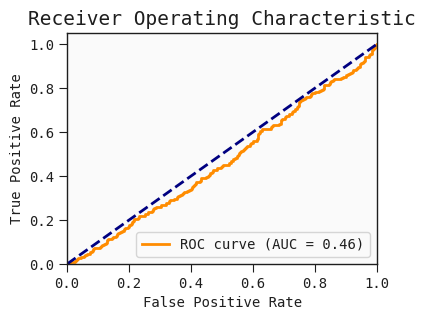

In [266]:
y_true_list_lr2_omics_demo_corr = extract_results(results_lr2_omics_demo_corr, 'y_true')
y_pred_prob_list_lr2_omics_demo_corr= extract_results(results_lr2_omics_demo_corr, 'y_pred_prob')
y_pred_list_lr2_omics_demo_corr= extract_results(results_lr2_omics_demo_corr, 'y_pred')
feature_selection_df_lr2_omics_demo_corr= extract_results(results_lr2_omics_demo_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demo_corr= extract_results(results_lr2_omics_demo_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demo_corr}, Median AUC: {median_auc_lr2_omics_demo_corr}, IQR : {iqr_auc_lr2_omics_demo_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_demo_corr}") 
auc_plot(extract_results(results_lr2_omics_demo_corr, 'y_true'), extract_results(results_lr2_omics_demo_corr, 'y_pred_prob'))

#### L2-Female No feature selection

In [267]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoF, overall_auc_lr2_omics_demoF, median_auc_lr2_omics_demoF, iqr_auc_lr2_omics_demoF, iqr13_auc_lr2_omics_demoF = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (0.1, l2, liblinear)
test_auc                0.693333
Name: 2, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.586667
Name: 4, dtype: object

params      (0.01, l2, liblinear)
test_auc                     0.64
Name: 0, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.706667
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.693333
Name: 0, dtype: object

...

params      (0.01, l2, liblinear)
test_auc                    0.725
Name: 0, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.553333
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.670833
Name: 0, dtype: object

params      (10, l2, liblinear)
test_auc                 0.4475
Name: 10, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.726667
Name: 4, dtype: object

Overall AUC: 0.5882003395585739, Median AUC: 0.5933786078098472, IQR : 0.05305602716468594, IQ1-IQ3: (0.5772495755517827, 0.6303056027164686)


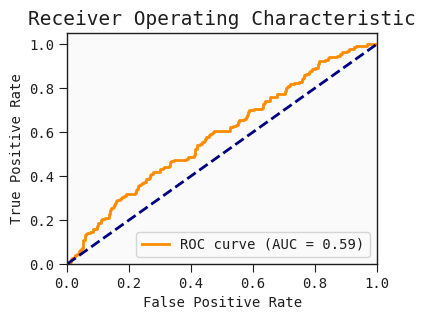

In [269]:
y_true_list_lr2_omics_demoF = extract_results(results_lr2_omics_demoF, 'y_true')
y_pred_prob_list_lr2_omics_demoF= extract_results(results_lr2_omics_demoF, 'y_pred_prob')
y_pred_list_lr2_omics_demoF= extract_results(results_lr2_omics_demoF, 'y_pred')
feature_selection_df_lr2_omics_demoF= extract_results(results_lr2_omics_demoF, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoF= extract_results(results_lr2_omics_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoF}, Median AUC: {median_auc_lr2_omics_demoF}, IQR : {iqr_auc_lr2_omics_demoF}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoF}") 
auc_plot(extract_results(results_lr2_omics_demoF, 'y_true'), extract_results(results_lr2_omics_demoF, 'y_pred_prob'))

#### L2-Female RFE20

In [270]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoF_rfe, overall_auc_lr2_omics_demoF_rfe, median_auc_lr2_omics_demoF_rfe, iqr_auc_lr2_omics_demoF_rfe, iqr13_auc_lr2_omics_demoF_rfe = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, l2, liblinear)
test_auc               0.866667
Name: 10, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, l2, saga)
test_auc           0.893333
Name: 3, dtype: object

Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, saga)
test_auc         0.748333
Name: 9, dtype: object

Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                0.843333
Name: 12, dtype: object

Do RFE feature Selection


Overall AUC: 0.7385568760611205, Median AUC: 0.7580645161290323, IQR : 0.07173174872665533, IQ1-IQ3: (0.715195246179966, 0.7869269949066213)


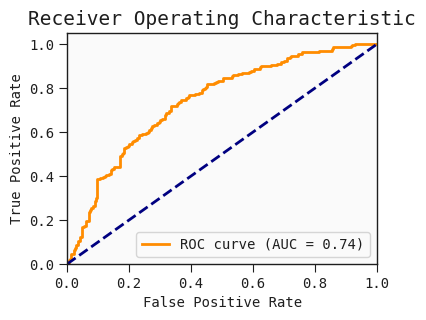

In [272]:
y_true_list_lr2_omics_demoF_rfe = extract_results(results_lr2_omics_demoF_rfe, 'y_true')
y_pred_prob_list_lr2_omics_demoF_rfe = extract_results(results_lr2_omics_demoF_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_demoF_rfe = extract_results(results_lr2_omics_demoF_rfe, 'y_pred')
feature_selection_df_lr2_omics_demoF_rfe = extract_results(results_lr2_omics_demoF_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoF_rfe = extract_results(results_lr2_omics_demoF_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoF_rfe}, Median AUC: {median_auc_lr2_omics_demoF_rfe}, IQR : {iqr_auc_lr2_omics_demoF_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoF_rfe}") 
auc_plot(extract_results(results_lr2_omics_demoF_rfe, 'y_true'), extract_results(results_lr2_omics_demoF_rfe, 'y_pred_prob'))

#### L2-Female MRMR20

In [273]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoF_mrmr, overall_auc_lr2_omics_demoF_mrmr, median_auc_lr2_omics_demoF_mrmr, iqr_auc_lr2_omics_demoF_mrmr, iqr13_auc_lr2_omics_demoF_mrmr = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:13,  1.33it/s]





 15%|█▌        | 3/20 [00:01<00:10,  1.59it/s]





 20%|██        | 4/20 [00:02<00:08,  1.96it/s]





 25%|██▌       | 5/20 [00:02<00:07,  2.14it/s]





 30%|███       | 6/20 [00:02<00:05,  2.42it/s]





 35%|███▌      | 7/20 [00:03<00:04,  2.68it/s]





 40%|████      | 8/20 [00:03<00:04,  2.83it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.04it/s]





 50%|█████     | 10/20 [00:04<00:03,  3.07it/s]





 55%|█████▌    | 11/20 [00:04<00:02,  3.20it/s]








 60%|██████    | 12/20 [00:04<00:02,  3.05it/s]





 65%|██████▌   | 13/20 [00:05<00:02,  3.01it/s]





 70%|███████   | 14/20 [00:05<00:01,  3.16it/s]


 75%|███████▌  | 15/20 [00:05<00:01,  3.23it/s]





 80%|████████  | 16/20 [00:06<00:01,  3.31it/s]





 85%|████████▌ | 17/20 [00:06<00:00,  3.29it/s]





 90%|█████████ | 18/20 [00:06<00:00,  3.36it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.40it/s]





100%|████████

Do MRMR feature selection



100%|██████████| 20/20 [00:07<00:00,  2.82it/s]



100%|██████████| 20/20 [00:06<00:00,  3.22it/s]


Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


...

Do MRMR feature selection


params      (1, l2, liblinear)
test_auc              0.776667
Name: 6, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.840833
Name: 2, dtype: object

Do MRMR feature selectionDo MRMR feature selection



 10%|█         | 2/20 [00:00<00:07,  2.47it/s]


 15%|█▌        | 3/20 [00:01<00:06,  2.77it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.05it/s]


 30%|███       | 6/20 [00:02<00:04,  3.24it/s]


 35%|███▌      | 7/20 [00:02<00:03,  3.30it/s]


 40%|████      | 8/20 [00:02<00:03,  3.57it/s]


 45%|████▌     | 9/20 [00:02<00:02,  3.74it/s]


 50%|█████     | 10/20 [00:03<00:02,  3.79it/s]


 55%|█████▌    | 11/20 [00:03<00:02,  4.13it/s]


 60%|██████    | 12/20 [00:03<00:01,  4.04it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  3.78it/s]


 70%|███████   | 14/20 [00:04<00:01,  3.87it/s]


 75%|███████▌  | 15/20 [00:04<00:01,  4.14it/s]


 80%|████████  | 16/20 [00:04<00:00,  4.13it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  3.65it/s]


 90%|█████████ | 18/20 [00:05<00:00,  3.93it/s]

 95%|█████████▌| 19/20 [00:05<00:00,  4.28it/s]


100%|██████████| 20/20 [00:05<00:00,  3.67it/s]


100%|██████████| 20/20 [00:05<00:00,  3.82it/s]

100%|██████████| 20/20 [00:05<00:00,  3.93it/s]


100%|████

Overall AUC: 0.6996434634974534, Median AUC: 0.7079796264855688, IQR : 0.07555178268251284, IQ1-IQ3: (0.664685908319185, 0.7402376910016978)


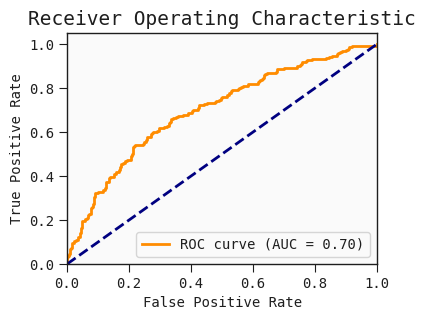

In [275]:
y_true_list_lr2_omics_demoF_mrmr = extract_results(results_lr2_omics_demoF_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_demoF_mrmr = extract_results(results_lr2_omics_demoF_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_demoF_mrmr = extract_results(results_lr2_omics_demoF_mrmr, 'y_pred')
feature_selection_df_lr2_omics_demoF_mrmr = extract_results(results_lr2_omics_demoF_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoF_mrmr = extract_results(results_lr2_omics_demoF_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoF_mrmr}, Median AUC: {median_auc_lr2_omics_demoF_mrmr}, IQR : {iqr_auc_lr2_omics_demoF_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoF_mrmr}") 
auc_plot(extract_results(results_lr2_omics_demoF_mrmr, 'y_true'), extract_results(results_lr2_omics_demoF_mrmr, 'y_pred_prob'))

#### L2-Female correlation20

In [276]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoF_corr, overall_auc_lr2_omics_demoF_corr, median_auc_lr2_omics_demoF_corr, iqr_auc_lr2_omics_demoF_corr, iqr13_auc_lr2_omics_demoF_corr = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection



params      (0.1, l2, liblinear)
test_auc                0.733333
Name: 2, dtype: object

Do Correlation-Based feature selection


params      (0.5, l2, saga)
test_auc           0.733333
Name: 5, dtype: object

params      (0.1, l2, liblinear)
test_auc                    0.72
Name: 2, dtype: object

...

Do Correlation-Based feature selection


params      (10, l2, saga)
test_auc          0.761667
Name: 11, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, l2, liblinear)
test_auc               0.696667
Name: 10, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.7057215619694398, Median AUC: 0.7113752122241086, IQR : 0.06154499151103576, IQ1-IQ3: (0.6719015280135823, 0.733446519524618)


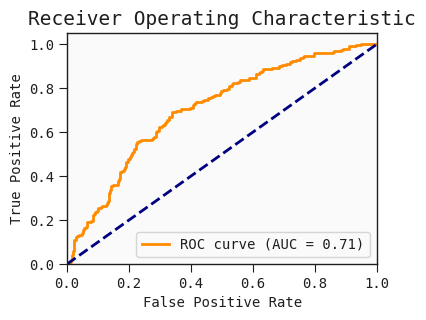

In [278]:
y_true_list_lr2_omics_demoF_corr = extract_results(results_lr2_omics_demoF_corr, 'y_true')
y_pred_prob_list_lr2_omics_demoF_corr= extract_results(results_lr2_omics_demoF_corr, 'y_pred_prob')
y_pred_list_lr2_omics_demoF_corr= extract_results(results_lr2_omics_demoF_corr, 'y_pred')
feature_selection_df_lr2_omics_demoF_corr= extract_results(results_lr2_omics_demoF_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoF_corr= extract_results(results_lr2_omics_demoF_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoF_corr}, Median AUC: {median_auc_lr2_omics_demoF_corr}, IQR : {iqr_auc_lr2_omics_demoF_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoF_corr}") 
auc_plot(extract_results(results_lr2_omics_demoF_corr, 'y_true'), extract_results(results_lr2_omics_demoF_corr, 'y_pred_prob'))

#### L2-Male No feature selection

In [279]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoM, overall_auc_lr2_omics_demoM, median_auc_lr2_omics_demoM, iqr_auc_lr2_omics_demoM, iqr13_auc_lr2_omics_demoM = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (5, l2, liblinear)
test_auc                   0.4
Name: 8, dtype: object

params      (10, l2, liblinear)
test_auc               0.616667
Name: 10, dtype: object

params      (0.01, l2, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (100, l2, liblinear)
test_auc                0.483333
Name: 12, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.433333
Name: 2, dtype: object

...

params      (0.1, l2, liblinear)
test_auc                0.319444
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.519444
Name: 0, dtype: object

params      (10, l2, liblinear)
test_auc               0.519444
Name: 10, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.380556
Name: 0, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.541667
Name: 0, dtype: object

Overall AUC: 0.4428385416666667, Median AUC: 0.4609375, IQR : 0.04036458333333337, IQ1-IQ3: (0.44140625, 0.48177083333333337)


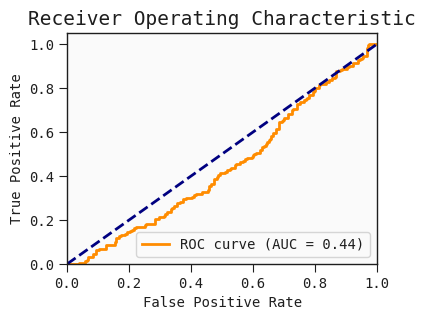

In [281]:
y_true_list_lr2_omics_demoM = extract_results(results_lr2_omics_demoM, 'y_true')
y_pred_prob_list_lr2_omics_demoM= extract_results(results_lr2_omics_demoM, 'y_pred_prob')
y_pred_list_lr2_omics_demoM= extract_results(results_lr2_omics_demoM, 'y_pred')
feature_selection_df_lr2_omics_demoM= extract_results(results_lr2_omics_demoM, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoM= extract_results(results_lr2_omics_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoM}, Median AUC: {median_auc_lr2_omics_demoM}, IQR : {iqr_auc_lr2_omics_demoM}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoM}") 
auc_plot(extract_results(results_lr2_omics_demoM, 'y_true'), extract_results(results_lr2_omics_demoM, 'y_pred_prob'))

#### L2-Male RFE20

In [282]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoM_rfe, overall_auc_lr2_omics_demoM_rfe, median_auc_lr2_omics_demoM_rfe, iqr_auc_lr2_omics_demoM_rfe, iqr13_auc_lr2_omics_demoM_rfe  = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, l2, saga)
test_auc         0.483333
Name: 7, dtype: object

Do RFE feature Selection


params      (5, l2, liblinear)
test_auc              0.891667
Name: 8, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, liblinear)
test_auc              0.883333
Name: 8, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, saga)
test_auc            0.625
Name: 9, dtype: object

Do RFE feature Selection


Overall AUC: 0.74703125, Median AUC: 0.7239583333333333, IQR : 0.052734375, IQ1-IQ3: (0.716796875, 0.76953125)


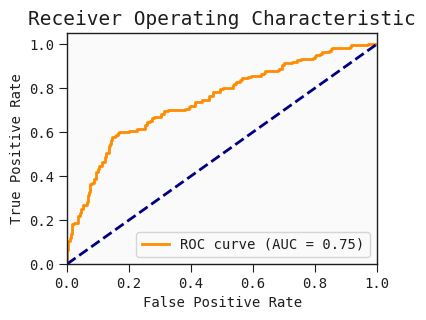

In [284]:
y_true_list_lr2_omics_demoM_rfe = extract_results(results_lr2_omics_demoM_rfe, 'y_true')
y_pred_prob_list_lr2_omics_demoM_rfe = extract_results(results_lr2_omics_demoM_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_demoM_rfe = extract_results(results_lr2_omics_demoM_rfe, 'y_pred')
feature_selection_df_lr2_omics_demoM_rfe = extract_results(results_lr2_omics_demoM_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoM_rfe = extract_results(results_lr2_omics_demoM_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoM_rfe}, Median AUC: {median_auc_lr2_omics_demoM_rfe}, IQR : {iqr_auc_lr2_omics_demoM_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoM_rfe}") 
auc_plot(extract_results(results_lr2_omics_demoM_rfe, 'y_true'), extract_results(results_lr2_omics_demoM_rfe, 'y_pred_prob'))

#### L2-Male MRMR20

In [285]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoM_mrmr, overall_auc_lr2_omics_demoM_mrmr, median_auc_lr2_omics_demoM_mrmr, iqr_auc_lr2_omics_demoM_mrmr, iqr13_auc_lr2_omics_demoM_mrmr = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection
Do MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:07,  2.26it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.65it/s]





 20%|██        | 4/20 [00:01<00:06,  2.44it/s]





 25%|██▌       | 5/20 [00:01<00:05,  2.64it/s]


 30%|███       | 6/20 [00:02<00:04,  2.95it/s]





 35%|███▌      | 7/20 [00:02<00:04,  3.20it/s]





 40%|████      | 8/20 [00:02<00:04,  2.87it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.13it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.11it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.42it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.37it/s]





 65%|██████▌   | 13/20 [00:04<00:01,  3.59it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.69it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.26it/s]





 80%|████████  | 16/20 [00:05<00:01,  2.90it/s]





 85%|████████▌ | 17/20 [00:05<00:01,  2.83it/s]





 90%|█████████ | 18/20 [00:06<00:00,  2.95it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  2.93it/s]



100%|██████████| 2

Do MRMR feature selection


100%|██████████| 20/20 [00:06<00:00,  3.16it/s]


Do MRMR feature selection
Do MRMR feature selection


...

Do MRMR feature selection


 65%|██████▌   | 13/20 [00:03<00:02,  3.05it/s]

params      (10, l2, liblinear)
test_auc               0.683333
Name: 10, dtype: object

Do MRMR feature selection



 70%|███████   | 14/20 [00:04<00:02,  2.59it/s]


 75%|███████▌  | 15/20 [00:04<00:01,  2.76it/s]

 80%|████████  | 16/20 [00:04<00:01,  2.92it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  3.19it/s]


 90%|█████████ | 18/20 [00:05<00:00,  3.45it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  3.61it/s]


100%|██████████| 20/20 [00:05<00:00,  3.50it/s]
































100%|██████████| 20/20 [00:05<00:00,  3.68it/s]







100%|██████████| 20/20 [00:04<00:00,  4.59it/s]


100%|██████████| 20/20 [00:04<00:00,  4.75it/s]


Overall AUC: 0.6527083333333334, Median AUC: 0.64453125, IQR : 0.04427083333333326, IQ1-IQ3: (0.625, 0.6692708333333333)


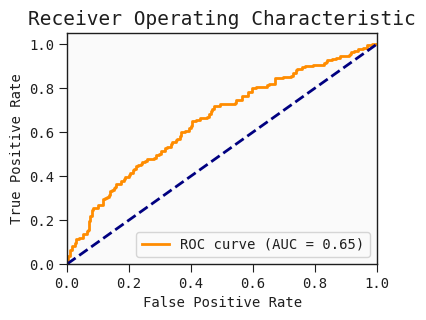

In [287]:
y_true_list_lr2_omics_demoM_mrmr = extract_results(results_lr2_omics_demoM_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_demoM_mrmr = extract_results(results_lr2_omics_demoM_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_demoM_mrmr = extract_results(results_lr2_omics_demoM_mrmr, 'y_pred')
feature_selection_df_lr2_omics_demoM_mrmr = extract_results(results_lr2_omics_demoM_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoM_mrmr = extract_results(results_lr2_omics_demoM_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoM_mrmr}, Median AUC: {median_auc_lr2_omics_demoM_mrmr}, IQR : {iqr_auc_lr2_omics_demoM_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoM_mrmr}") 
auc_plot(extract_results(results_lr2_omics_demoM_mrmr, 'y_true'), extract_results(results_lr2_omics_demoM_mrmr, 'y_pred_prob'))

#### L2-Male correlation20

In [288]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_demoM_corr, overall_auc_lr2_omics_demoM_corr, median_auc_lr2_omics_demoM_corr, iqr_auc_lr2_omics_demoM_corr, iqr13_auc_lr2_omics_demoM_corr = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.441667
Name: 12, dtype: object

Do Correlation-Based feature selection


params      (0.01, l2, liblinear)
test_auc                 0.433333
Name: 0, dtype: object

params      (10, l2, liblinear)
test_auc               0.791667
Name: 10, dtype: object

...


Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, l2, saga)
test_auc          0.513889
Name: 11, dtype: object

params      (100, l2, liblinear)
test_auc                0.588889
Name: 12, dtype: object

params      (5, l2, liblinear)
test_auc              0.663889
Name: 8, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.674296875, Median AUC: 0.6783854166666667, IQR : 0.12434895833333326, IQ1-IQ3: (0.62109375, 0.7454427083333333)


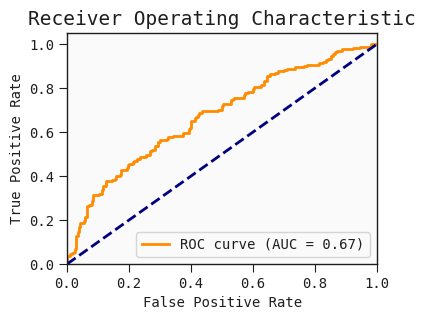

In [290]:
y_true_list_lr2_omics_demoM_corr = extract_results(results_lr2_omics_demoM_corr, 'y_true')
y_pred_prob_list_lr2_omics_demoM_corr= extract_results(results_lr2_omics_demoM_corr, 'y_pred_prob')
y_pred_list_lr2_omics_demoM_corr= extract_results(results_lr2_omics_demoM_corr, 'y_pred')
feature_selection_df_lr2_omics_demoM_corr= extract_results(results_lr2_omics_demoM_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_demoM_corr= extract_results(results_lr2_omics_demoM_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_demoM_corr}, Median AUC: {median_auc_lr2_omics_demoM_corr}, IQR : {iqr_auc_lr2_omics_demoM_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_demoM_corr}") 
auc_plot(extract_results(results_lr2_omics_demoM_corr, 'y_true'), extract_results(results_lr2_omics_demoM_corr, 'y_pred_prob'))

### SVM

#### SVM-Full No feature selection

In [309]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_demo, overall_auc_svm_omics_demo, median_auc_svm_omics_demo, iqr_auc_svm_omics_demo, iqr13_auc_svm_omics_demo = run_multiple_evaluations_parallel(model_omics_df_demo, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, linear, auto)
test_auc                 0.46537
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.467963
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.485556
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.513611
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.627778
Name: 0, dtype: object

...

params      (0.01, linear, auto)
test_auc                0.546574
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.416481
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.391019
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.402222
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.437963
Name: 2, dtype: object

Overall AUC: 0.4552077922077922, Median AUC: 0.44831168831168833, IQR : 0.0522077922077922, IQ1-IQ3: (0.4227922077922078, 0.475)


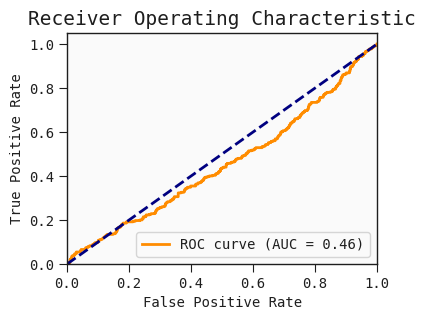

In [311]:
y_true_list_svm_omics_demo = extract_results(results_svm_omics_demo, 'y_true')
y_pred_prob_list_svm_omics_demo = extract_results(results_svm_omics_demo, 'y_pred_prob')
y_pred_list_svm_omics_demo = extract_results(results_svm_omics_demo, 'y_pred')
feature_selection_df_svm_omics_demo = extract_results(results_svm_omics_demo, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demo = extract_results(results_svm_omics_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demo}, Median AUC: {median_auc_svm_omics_demo}, IQR : {iqr_auc_svm_omics_demo}, IQ1-IQ3: {iqr13_auc_svm_omics_demo}") 
auc_plot(extract_results(results_svm_omics_demo, 'y_true'), extract_results(results_svm_omics_demo, 'y_pred_prob'))

#### SVM-Full RFE20

In [312]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_demo_rfe, overall_auc_svm_omics_demo_rfe, median_auc_svm_omics_demo_rfe, iqr_auc_svm_omics_demo_rfe, iqr13_auc_svm_omics_demo_rfe = run_multiple_evaluations_parallel(model_omics_df_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.649074
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, linear, auto)
test_auc              0.548704
Name: 6, dtype: object

Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.568148
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.557593
Name: 0, dtype: object

Do RFE feature Selection


Overall AUC: 0.5020987012987014, Median AUC: 0.5257142857142858, IQR : 0.08649350649350651, IQ1-IQ3: (0.45519480519480515, 0.5416883116883117)


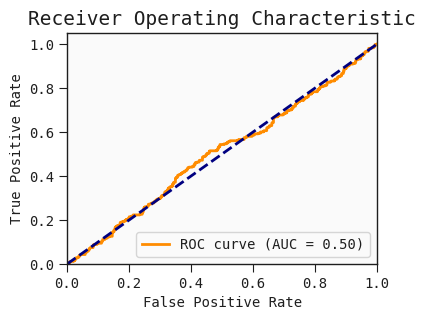

In [314]:
y_true_list_svm_omics_demo_rfe = extract_results(results_svm_omics_demo_rfe, 'y_true')
y_pred_prob_list_svm_omics_demo_rfe= extract_results(results_svm_omics_demo_rfe, 'y_pred_prob')
y_pred_list_svm_omics_demo_rfe= extract_results(results_svm_omics_demo_rfe, 'y_pred')
feature_selection_df_svm_omics_demo_rfe= extract_results(results_svm_omics_demo_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demo_rfe= extract_results(results_svm_omics_demo_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demo_rfe}, Median AUC: {median_auc_svm_omics_demo_rfe}, IQR : {iqr_auc_svm_omics_demo_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_demo_rfe}") 
auc_plot(extract_results(results_svm_omics_demo_rfe, 'y_true'), extract_results(results_svm_omics_demo_rfe, 'y_pred_prob'))

#### SVM-Full MRMR20

In [315]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_demo_mrmr, overall_auc_svm_omics_demo_mrmr, median_auc_svm_omics_demo_mrmr, iqr_auc_svm_omics_demo_mrmr, iqr13_auc_svm_omics_demo_mrmr = run_multiple_evaluations_parallel(model_omics_df_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]





 10%|█         | 2/20 [00:01<00:11,  1.54it/s]





 15%|█▌        | 3/20 [00:01<00:08,  1.97it/s]





 20%|██        | 4/20 [00:01<00:06,  2.33it/s]





 25%|██▌       | 5/20 [00:02<00:05,  2.81it/s]





 30%|███       | 6/20 [00:02<00:04,  2.97it/s]





 35%|███▌      | 7/20 [00:02<00:04,  3.18it/s]





 40%|████      | 8/20 [00:02<00:03,  3.26it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.44it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.29it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.39it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.19it/s]





 65%|██████▌   | 13/20 [00:04<00:02,  3.23it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.18it/s]





 75%|███████▌  | 15/20 [00:05<00:01,  3.19it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.26it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.35it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.39it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.41it/s]


100%|████████

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.10it/s]





 15%|█▌        | 3/20 [00:01<00:07,  2.38it/s]





 20%|██        | 4/20 [00:01<00:06,  2.32it/s]





 25%|██▌       | 5/20 [00:02<00:05,  2.59it/s]





 30%|███       | 6/20 [00:02<00:05,  2.56it/s]





 35%|███▌      | 7/20 [00:02<00:04,  2.82it/s]





 40%|████      | 8/20 [00:02<00:03,  3.14it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.13it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.30it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.33it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.38it/s]





 65%|██████▌   | 13/20 [00:04<00:02,  3.42it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.72it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.68it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.59it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.30it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.31it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.24it/s]





100%|████████

Do MRMR feature selectionDo MRMR feature selection



...

 50%|█████     | 10/20 [00:03<00:03,  3.01it/s]



 55%|█████▌    | 11/20 [00:03<00:02,  3.13it/s]


params      (1, linear, auto)
test_auc             0.558148
Name: 4, dtype: object

 60%|██████    | 12/20 [00:03<00:02,  3.40it/s]

Do MRMR feature selection


 65%|██████▌   | 13/20 [00:04<00:02,  2.76it/s]


 70%|███████   | 14/20 [00:04<00:01,  3.33it/s]


 80%|████████  | 16/20 [00:04<00:01,  3.63it/s]




 90%|█████████ | 18/20 [00:05<00:00,  3.98it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  4.29it/s]


100%|██████████| 20/20 [00:05<00:00,  3.50it/s]




























100%|██████████| 20/20 [00:04<00:00,  4.86it/s]


100%|██████████| 20/20 [00:04<00:00,  4.57it/s]


100%|██████████| 20/20 [00:03<00:00,  5.75it/s]


Overall AUC: 0.46362597402597405, Median AUC: 0.46545454545454545, IQR : 0.07701298701298709, IQ1-IQ3: (0.4342857142857143, 0.5112987012987014)


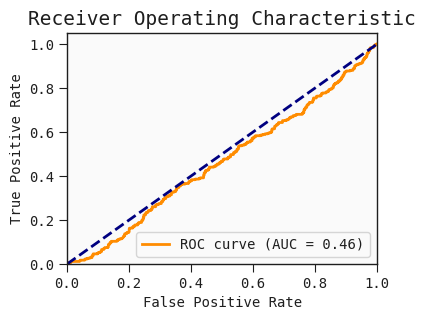

In [317]:
y_true_list_svm_omics_demo_mrmr = extract_results(results_svm_omics_demo_mrmr, 'y_true')
y_pred_prob_list_svm_omics_demo_mrmr= extract_results(results_svm_omics_demo_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_demo_mrmr= extract_results(results_svm_omics_demo_mrmr, 'y_pred')
feature_selection_df_svm_omics_demo_mrmr= extract_results(results_svm_omics_demo_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demo_mrmr= extract_results(results_svm_omics_demo_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demo_mrmr}, Median AUC: {median_auc_svm_omics_demo_mrmr}, IQR : {iqr_auc_svm_omics_demo_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_demo_mrmr}") 
auc_plot(extract_results(results_svm_omics_demo_mrmr, 'y_true'), extract_results(results_svm_omics_demo_mrmr, 'y_pred_prob'))

#### SVM-Full correlation20

In [318]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_demo_corr, overall_auc_svm_omics_demo_corr, median_auc_svm_omics_demo_corr, iqr_auc_svm_omics_demo_corr, iqr13_auc_svm_omics_demo_corr = run_multiple_evaluations_parallel(model_omics_df_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc               0.686204
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.593241
Name: 0, dtype: object

params      (100, linear, auto)
test_auc               0.690648
Name: 8, dtype: object

Do Correlation-Based feature selection

...

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc             0.541759
Name: 4, dtype: object

Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.663056
Name: 0, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.4672571428571428, Median AUC: 0.44753246753246756, IQR : 0.06194805194805214, IQ1-IQ3: (0.4328571428571428, 0.4948051948051949)


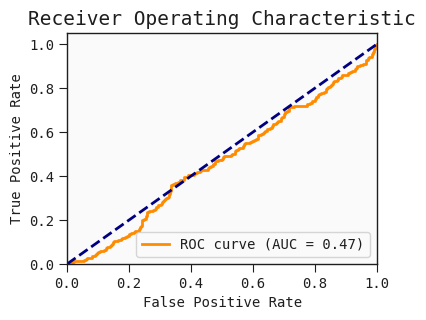

In [320]:
y_true_list_svm_omics_demo_corr = extract_results(results_svm_omics_demo_corr, 'y_true')
y_pred_prob_list_svm_omics_demo_corr = extract_results(results_svm_omics_demo_corr, 'y_pred_prob')
y_pred_list_svm_omics_demo_corr = extract_results(results_svm_omics_demo_corr, 'y_pred')
feature_selection_df_svm_omics_demo_corr = extract_results(results_svm_omics_demo_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demo_corr = extract_results(results_svm_omics_demo_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demo_corr}, Median AUC: {median_auc_svm_omics_demo_corr}, IQR : {iqr_auc_svm_omics_demo_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_demo_corr}") 
auc_plot(extract_results(results_svm_omics_demo_corr, 'y_true'), extract_results(results_svm_omics_demo_corr, 'y_pred_prob'))

#### SVM-Female No feature selection

In [321]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_demoF, overall_auc_svm_omics_demoF, median_auc_svm_omics_demoF, iqr_auc_svm_omics_demoF, iqr13_auc_svm_omics_demoF = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.1, linear, auto)
test_auc                   0.44
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.666667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.626667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.48
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.466667
Name: 2, dtype: object

...

params      (0.1, linear, auto)
test_auc                    0.7
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.323333
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                  0.4875
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.540833
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.753333
Name: 2, dtype: object

Overall AUC: 0.4543039049235993, Median AUC: 0.44991511035653653, IQR : 0.05942275042444822, IQ1-IQ3: (0.42826825127334467, 0.4876910016977929)


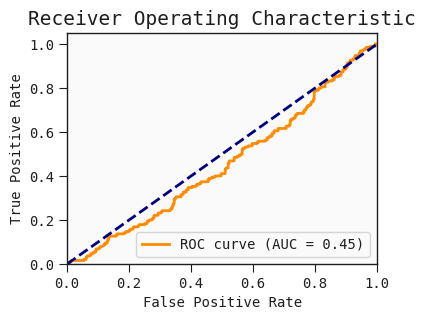

In [323]:
y_true_list_svm_omics_demoF = extract_results(results_svm_omics_demoF, 'y_true')
y_pred_prob_list_svm_omics_demoF= extract_results(results_svm_omics_demoF, 'y_pred_prob')
y_pred_list_svm_omics_demoF= extract_results(results_svm_omics_demoF, 'y_pred')
feature_selection_df_svm_omics_demoF= extract_results(results_svm_omics_demoF, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoF= extract_results(results_svm_omics_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoF}, Median AUC: {median_auc_svm_omics_demoF}, IQR : {iqr_auc_svm_omics_demoF}, IQ1-IQ3: {iqr13_auc_svm_omics_demoF}") 
auc_plot(extract_results(results_svm_omics_demoF, 'y_true'), extract_results(results_svm_omics_demoF, 'y_pred_prob'))

#### SVM-Female RFE20

In [324]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_demoF_rfe, overall_auc_svm_omics_demoF_rfe, median_auc_svm_omics_demoF_rfe, iqr_auc_svm_omics_demoF_rfe, iqr13_auc_svm_omics_demoF_rfe = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, linear, auto)
test_auc               0.653333
Name: 2, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, linear, auto)
test_auc               0.773333
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.88
Name: 2, dtype: object

...

Do RFE feature Selection
Do RFE feature Selection


params      (0.1, linear, auto)
test_auc                 0.8025
Name: 2, dtype: object

Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.619167
Name: 4, dtype: object

Do RFE feature Selection


Overall AUC: 0.7194057724957555, Median AUC: 0.733446519524618, IQR : 0.027589134125636794, IQ1-IQ3: (0.7160441426146009, 0.7436332767402377)


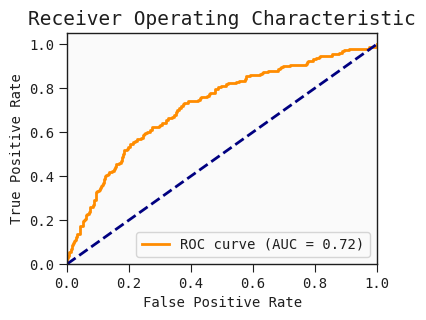

In [326]:
y_true_list_svm_omics_demoF_rfe = extract_results(results_svm_omics_demoF_rfe, 'y_true')
y_pred_prob_list_svm_omics_demoF_rfe= extract_results(results_svm_omics_demoF_rfe, 'y_pred_prob')
y_pred_list_svm_omics_demoF_rfe= extract_results(results_svm_omics_demoF_rfe, 'y_pred')
feature_selection_df_svm_omics_demoF_rfe= extract_results(results_svm_omics_demoF_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoF_rfe= extract_results(results_svm_omics_demoF_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoF_rfe}, Median AUC: {median_auc_svm_omics_demoF_rfe}, IQR : {iqr_auc_svm_omics_demoF_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_demoF_rfe}") 
auc_plot(extract_results(results_svm_omics_demoF_rfe, 'y_true'), extract_results(results_svm_omics_demoF_rfe, 'y_pred_prob'))

#### SVM-Female MRMR20

In [327]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_demoF_mrmr, overall_auc_svm_omics_demoF_mrmr, median_auc_svm_omics_demoF_mrmr, iqr_auc_svm_omics_demoF_mrmr, iqr13_auc_svm_omics_demoF_mrmr = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:07,  2.42it/s]





 15%|█▌        | 3/20 [00:01<00:05,  2.93it/s]





 20%|██        | 4/20 [00:01<00:05,  3.12it/s]





 25%|██▌       | 5/20 [00:01<00:05,  2.89it/s]





 30%|███       | 6/20 [00:02<00:04,  3.10it/s]





 35%|███▌      | 7/20 [00:02<00:04,  3.18it/s]





 40%|████      | 8/20 [00:02<00:03,  3.39it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.53it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.52it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.54it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.16it/s]



 65%|██████▌   | 13/20 [00:04<00:02,  3.49it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.73it/s]







 75%|███████▌  | 15/20 [00:04<00:01,  3.49it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.51it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.53it/s]



 90%|█████████ | 18/20 [00:05<00:00,  3.58it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.73it/s]





100%|██████████

Do MRMR feature selection
Do MRMR feature selection




100%|██████████| 20/20 [00:05<00:00,  3.45it/s]


Do MRMR feature selection
Do MRMR feature selection


...

params      (0.01, linear, auto)
test_auc                0.585417
Name: 0, dtype: object

 95%|█████████▌| 19/20 [00:05<00:00,  3.04it/s]

params      (0.1, linear, auto)
test_auc               0.735833
Name: 2, dtype: object

Do MRMR feature selection
Do MRMR feature selection


 35%|███▌      | 7/20 [00:01<00:03,  3.45it/s]


100%|██████████| 20/20 [00:05<00:00,  3.43it/s]

 40%|████      | 8/20 [00:02<00:03,  3.23it/s]


 45%|████▌     | 9/20 [00:02<00:02,  3.81it/s]


 55%|█████▌    | 11/20 [00:02<00:02,  3.82it/s]


 60%|██████    | 12/20 [00:03<00:02,  3.98it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  4.32it/s]


 70%|███████   | 14/20 [00:03<00:01,  4.48it/s]


 75%|███████▌  | 15/20 [00:03<00:01,  4.48it/s]


 80%|████████  | 16/20 [00:03<00:00,  4.61it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.55it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.19it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.28it/s]


100%|██████████| 20/20 [00:04<00:00,  4.08it/s]


100%|██████████| 20/20 [00:04<00:00,  4.08it/s]












100%|██████████| 20/20 [00:04<00:00,  4.55it/s]






100%|██████████| 20/20 [00:03<00:00,  5.19it/s]


Overall AUC: 0.702741935483871, Median AUC: 0.7003395585738541, IQR : 0.053904923599320864, IQ1-IQ3: (0.6833616298811545, 0.7372665534804753)


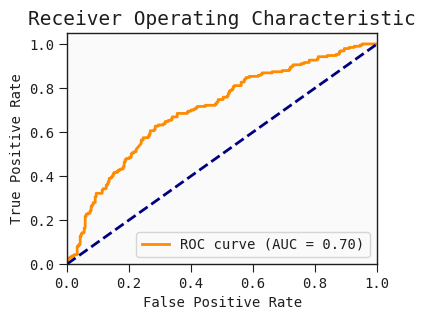

In [329]:
y_true_list_svm_omics_demoF_mrmr = extract_results(results_svm_omics_demoF_mrmr, 'y_true')
y_pred_prob_list_svm_omics_demoF_mrmr= extract_results(results_svm_omics_demoF_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_demoF_mrmr= extract_results(results_svm_omics_demoF_mrmr, 'y_pred')
feature_selection_df_svm_omics_demoF_mrmr= extract_results(results_svm_omics_demoF_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoF_mrmr= extract_results(results_svm_omics_demoF_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoF_mrmr}, Median AUC: {median_auc_svm_omics_demoF_mrmr}, IQR : {iqr_auc_svm_omics_demoF_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_demoF_mrmr}") 
auc_plot(extract_results(results_svm_omics_demoF_mrmr, 'y_true'), extract_results(results_svm_omics_demoF_mrmr, 'y_pred_prob'))

#### SVM-Female correlation20

In [330]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_demoF_corr, overall_auc_svm_omics_demoF_corr, median_auc_svm_omics_demoF_corr, iqr_auc_svm_omics_demoF_corr, iqr13_auc_svm_omics_demoF_corr = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc               0.773333
Name: 2, dtype: object

params      (1, linear, auto)
test_auc                 0.76
Name: 4, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc               0.693333
Name: 2, dtype: object

...

Do Correlation-Based feature selection


params      (10, linear, auto)
test_auc              0.671667
Name: 6, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc                 0.6425
Name: 2, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.7091171477079796, Median AUC: 0.6876061120543293, IQR : 0.05814940577249583, IQ1-IQ3: (0.6706281833616299, 0.7287775891341257)


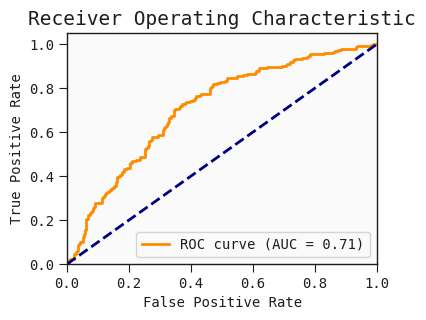

In [332]:
y_true_list_svm_omics_demoF_corr = extract_results(results_svm_omics_demoF_corr, 'y_true')
y_pred_prob_list_svm_omics_demoF_corr = extract_results(results_svm_omics_demoF_corr, 'y_pred_prob')
y_pred_list_svm_omics_demoF_corr = extract_results(results_svm_omics_demoF_corr, 'y_pred')
feature_selection_df_svm_omics_demoF_corr = extract_results(results_svm_omics_demoF_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoF_corr = extract_results(results_svm_omics_demoF_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoF_corr}, Median AUC: {median_auc_svm_omics_demoF_corr}, IQR : {iqr_auc_svm_omics_demoF_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_demoF_corr}") 
auc_plot(extract_results(results_svm_omics_demoF_corr, 'y_true'), extract_results(results_svm_omics_demoF_corr, 'y_pred_prob'))

#### SVM-Male No feature selection

In [333]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_demoM, overall_auc_svm_omics_demoM, median_auc_svm_omics_demoM, iqr_auc_svm_omics_demoM, iqr13_auc_svm_omics_demoM = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, linear, auto)
test_auc                0.616667
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                   0.575
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.533333
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                   0.525
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.433333
Name: 0, dtype: object

...

params      (0.01, linear, auto)
test_auc                0.697222
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.441667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.363889
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.472222
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                  0.675
Name: 2, dtype: object

Overall AUC: 0.4586458333333333, Median AUC: 0.49283854166666663, IQR : 0.13411458333333337, IQ1-IQ3: (0.39713541666666663, 0.53125)


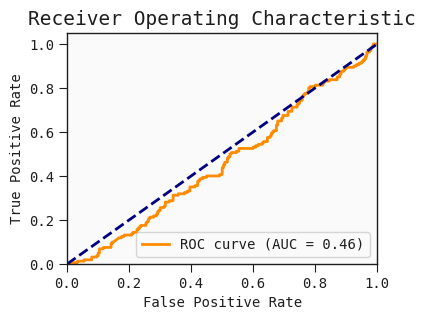

In [335]:
y_true_list_svm_omics_demoM = extract_results(results_svm_omics_demoM, 'y_true')
y_pred_prob_list_svm_omics_demoM= extract_results(results_svm_omics_demoM, 'y_pred_prob')
y_pred_list_svm_omics_demoM= extract_results(results_svm_omics_demoM, 'y_pred')
feature_selection_df_svm_omics_demoM= extract_results(results_svm_omics_demoM, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoM= extract_results(results_svm_omics_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoM}, Median AUC: {median_auc_svm_omics_demoM}, IQR : {iqr_auc_svm_omics_demoM}, IQ1-IQ3: {iqr13_auc_svm_omics_demoM}") 
auc_plot(extract_results(results_svm_omics_demoM, 'y_true'), extract_results(results_svm_omics_demoM, 'y_pred_prob'))

#### SVM-Male RFE20

In [336]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_demoM_rfe, overall_auc_svm_omics_demoM_rfe, median_auc_svm_omics_demoM_rfe, iqr_auc_svm_omics_demoM_rfe, iqr13_auc_svm_omics_demoM_rfe = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, linear, auto)
test_auc              0.783333
Name: 6, dtype: object

Do RFE feature Selection


params      (10, linear, auto)
test_auc              0.841667
Name: 6, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.577778
Name: 0, dtype: object

Do RFE feature Selection


params      (10, linear, auto)
test_auc              0.755556
Name: 6, dtype: object

Do RFE feature Selection


Overall AUC: 0.7043359375, Median AUC: 0.6927083333333334, IQR : 0.10221354166666663, IQ1-IQ3: (0.6484375, 0.7506510416666666)


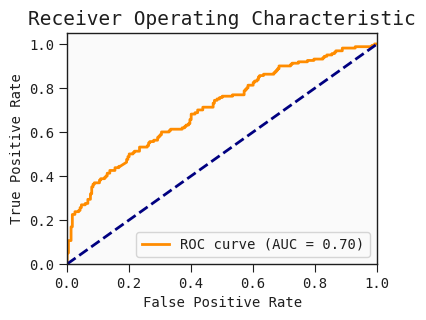

In [338]:
y_true_list_svm_omics_demoM_rfe = extract_results(results_svm_omics_demoM_rfe, 'y_true')
y_pred_prob_list_svm_omics_demoM_rfe= extract_results(results_svm_omics_demoM_rfe, 'y_pred_prob')
y_pred_list_svm_omics_demoM_rfe= extract_results(results_svm_omics_demoM_rfe, 'y_pred')
feature_selection_df_svm_omics_demoM_rfe= extract_results(results_svm_omics_demoM_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoM_rfe= extract_results(results_svm_omics_demoM_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoM_rfe}, Median AUC: {median_auc_svm_omics_demoM_rfe}, IQR : {iqr_auc_svm_omics_demoM_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_demoM_rfe}") 
auc_plot(extract_results(results_svm_omics_demoM_rfe, 'y_true'), extract_results(results_svm_omics_demoM_rfe, 'y_pred_prob'))

#### SVM-Male MRMR20

In [339]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_demoM_mrmr, overall_auc_svm_omics_demoM_mrmr, median_auc_svm_omics_demoM_mrmr, iqr_auc_svm_omics_demoM_mrmr, iqr13_auc_svm_omics_demoM_mrmr = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:07,  2.27it/s]





 15%|█▌        | 3/20 [00:01<00:05,  2.84it/s]





 20%|██        | 4/20 [00:01<00:05,  2.97it/s]





 25%|██▌       | 5/20 [00:01<00:05,  2.94it/s]





 30%|███       | 6/20 [00:02<00:04,  3.18it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.25it/s]





 40%|████      | 8/20 [00:02<00:03,  3.35it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.45it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.38it/s]


 55%|█████▌    | 11/20 [00:03<00:02,  3.46it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.58it/s]





 65%|██████▌   | 13/20 [00:04<00:01,  3.74it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.35it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.39it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.52it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.55it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.58it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.64it/s]





100%|██████████|

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:05<00:00,  3.51it/s]


Do MRMR feature selection


...

 20%|██        | 4/20 [00:00<00:03,  4.49it/s]

params      (0.1, linear, auto)
test_auc               0.530556
Name: 2, dtype: object

 75%|███████▌  | 15/20 [00:04<00:01,  2.57it/s]


100%|██████████| 20/20 [00:06<00:00,  2.97it/s]


Do MRMR feature selection





 80%|████████  | 16/20 [00:05<00:02,  1.86it/s]


 90%|█████████ | 18/20 [00:06<00:00,  2.59it/s]


 95%|█████████▌| 19/20 [00:06<00:00,  2.98it/s]


100%|██████████| 20/20 [00:06<00:00,  3.16it/s]

100%|██████████| 20/20 [00:06<00:00,  2.96it/s]































100%|██████████| 20/20 [00:05<00:00,  3.97it/s]












100%|██████████| 20/20 [00:04<00:00,  4.94it/s]


Overall AUC: 0.5908854166666666, Median AUC: 0.6002604166666667, IQR : 0.14388020833333326, IQ1-IQ3: (0.5169270833333334, 0.6608072916666666)


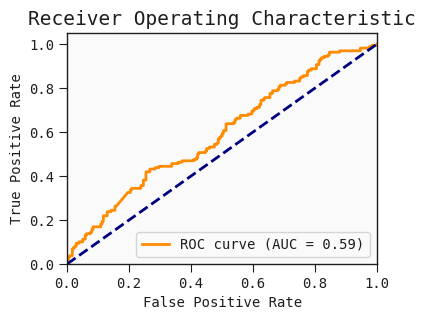

In [341]:
y_true_list_svm_omics_demoM_mrmr = extract_results(results_svm_omics_demoM_mrmr, 'y_true')
y_pred_prob_list_svm_omics_demoM_mrmr= extract_results(results_svm_omics_demoM_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_demoM_mrmr= extract_results(results_svm_omics_demoM_mrmr, 'y_pred')
feature_selection_df_svm_omics_demoM_mrmr= extract_results(results_svm_omics_demoM_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoM_mrmr= extract_results(results_svm_omics_demoM_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoM_mrmr}, Median AUC: {median_auc_svm_omics_demoM_mrmr}, IQR : {iqr_auc_svm_omics_demoM_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_demoM_mrmr}") 
auc_plot(extract_results(results_svm_omics_demoM_mrmr, 'y_true'), extract_results(results_svm_omics_demoM_mrmr, 'y_pred_prob'))

#### SVM-Male correlation20

In [342]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_demoM_corr, overall_auc_svm_omics_demoM_corr, median_auc_svm_omics_demoM_corr, iqr_auc_svm_omics_demoM_corr, iqr13_auc_svm_omics_demoM_corr = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, linear, auto)
test_auc                   0.7
Name: 6, dtype: object

params      (1, linear, auto)
test_auc                  0.7
Name: 4, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.658333
Name: 0, dtype: object

...

Do Correlation-Based feature selection


params      (100, linear, auto)
test_auc               0.538889
Name: 8, dtype: object

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc             0.691667
Name: 4, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.6043489583333332, Median AUC: 0.59765625, IQR : 0.11588541666666674, IQ1-IQ3: (0.5052083333333333, 0.62109375)


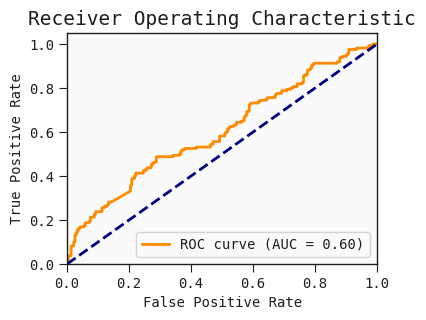

In [344]:
y_true_list_svm_omics_demoM_corr = extract_results(results_svm_omics_demoM_corr, 'y_true')
y_pred_prob_list_svm_omics_demoM_corr = extract_results(results_svm_omics_demoM_corr, 'y_pred_prob')
y_pred_list_svm_omics_demoM_corr = extract_results(results_svm_omics_demoM_corr, 'y_pred')
feature_selection_df_svm_omics_demoM_corr = extract_results(results_svm_omics_demoM_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_demoM_corr = extract_results(results_svm_omics_demoM_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_demoM_corr}, Median AUC: {median_auc_svm_omics_demoM_corr}, IQR : {iqr_auc_svm_omics_demoM_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_demoM_corr}") 
auc_plot(extract_results(results_svm_omics_demoM_corr, 'y_true'), extract_results(results_svm_omics_demoM_corr, 'y_pred_prob'))

### Random Forest

#### RF-Full No feature selection

In [345]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_demo, overall_auc_rf_omics_demo, median_auc_rf_omics_demo, iqr_auc_rf_omics_demo, iqr13_auc_rf_omics_demo = run_multiple_evaluations_parallel(model_omics_df_demo, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (5, 5, 2, 4)
test_auc        0.456157
Name: 5, dtype: object

params      (100, 3, 10, 2)
test_auc           0.485926
Name: 26, dtype: object

params      (100, 3, 2, 4)
test_auc          0.603796
Name: 25, dtype: object

params      (5, 3, 2, 2)
test_auc        0.582546
Name: 0, dtype: object

params      (5, 5, 10, 2)
test_auc         0.478611
Name: 6, dtype: object

...

params      (50, None, 10, 4)
test_auc             0.549815
Name: 23, dtype: object

params      (5, 3, 2, 4)
test_auc        0.620833
Name: 1, dtype: object

params      (5, None, 10, 2)
test_auc             0.64537
Name: 10, dtype: object

params      (50, 5, 2, 4)
test_auc         0.644907
Name: 17, dtype: object

params      (50, 5, 10, 2)
test_auc          0.693333
Name: 18, dtype: object

Overall AUC: 0.47625194805194804, Median AUC: 0.4771428571428571, IQR : 0.07616883116883122, IQ1-IQ3: (0.4252597402597402, 0.5014285714285714)


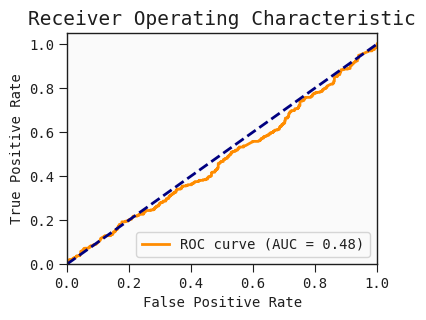

In [347]:
y_true_list_rf_omics_demo = extract_results(results_rf_omics_demo, 'y_true')
y_pred_prob_list_rf_omics_demo = extract_results(results_rf_omics_demo, 'y_pred_prob')
y_pred_list_rf_omics_demo= extract_results(results_rf_omics_demo, 'y_pred')
feature_selection_df_rf_omics_demo= extract_results(results_rf_omics_demo, 'feature_selection_df')
feature_sum_coef_df_rf_omics_demo= extract_results(results_rf_omics_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_demo}, Median AUC: {median_auc_rf_omics_demo}, IQR : {iqr_auc_rf_omics_demo}, IQ1-IQ3: {iqr13_auc_rf_omics_demo}") 
auc_plot(extract_results(results_rf_omics_demo, 'y_true'), extract_results(results_rf_omics_demo, 'y_pred_prob'))

#### RF-Female No feature selection

In [348]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_demoF, overall_auc_rf_omics_demoF, median_auc_rf_omics_demoF, iqr_auc_rf_omics_demoF, iqr13_auc_rf_omics_demoF = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (100, 3, 2, 2)
test_auc              0.68
Name: 24, dtype: object

params      (50, 5, 10, 4)
test_auc              0.76
Name: 19, dtype: object

params      (5, None, 10, 2)
test_auc            0.773333
Name: 10, dtype: object

params      (5, 3, 10, 2)
test_auc         0.693333
Name: 2, dtype: object

params      (100, None, 10, 2)
test_auc              0.706667
Name: 34, dtype: object

...

params      (500, None, 2, 2)
test_auc             0.775833
Name: 44, dtype: object

params      (100, 3, 10, 4)
test_auc           0.820833
Name: 27, dtype: object

params      (5, 3, 10, 4)
test_auc             0.74
Name: 3, dtype: object

params      (5, 3, 2, 4)
test_auc        0.622917
Name: 1, dtype: object

params      (50, 3, 2, 2)
test_auc         0.661667
Name: 12, dtype: object

Overall AUC: 0.6291426146010186, Median AUC: 0.6498302207130731, IQR : 0.043718166383701074, IQ1-IQ3: (0.6332767402376911, 0.6769949066213922)


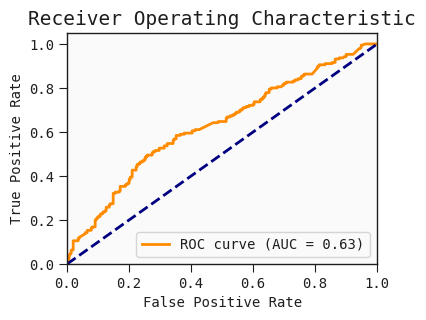

In [350]:
y_true_list_rf_omics_demoF = extract_results(results_rf_omics_demoF, 'y_true')
y_pred_prob_list_rf_omics_demoF = extract_results(results_rf_omics_demoF, 'y_pred_prob')
y_pred_list_rf_omics_demoF = extract_results(results_rf_omics_demoF, 'y_pred')
feature_selection_df_rf_omics_demoF = extract_results(results_rf_omics_demoF, 'feature_selection_df')
feature_sum_coef_df_rf_omics_demoF = extract_results(results_rf_omics_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_demoF}, Median AUC: {median_auc_rf_omics_demoF}, IQR : {iqr_auc_rf_omics_demoF}, IQ1-IQ3: {iqr13_auc_rf_omics_demoF}") 
auc_plot(extract_results(results_rf_omics_demoF, 'y_true'), extract_results(results_rf_omics_demoF, 'y_pred_prob'))

#### RF-Male No feature selection

In [351]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_demoM, overall_auc_rf_omics_demoM, median_auc_rf_omics_demoM, iqr_auc_rf_omics_demoM, iqr13_auc_rf_omics_demoM = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (5, None, 10, 4)
test_auc                 0.5
Name: 11, dtype: object

params      (50, 5, 2, 4)
test_auc         0.816667
Name: 17, dtype: object

params      (5, 3, 2, 2)
test_auc        0.541667
Name: 0, dtype: object

params      (100, 3, 2, 2)
test_auc             0.675
Name: 24, dtype: object

params      (50, 5, 2, 2)
test_auc         0.458333
Name: 16, dtype: object

...

params      (5, 3, 2, 2)
test_auc        0.505556
Name: 0, dtype: object

params      (100, 3, 2, 2)
test_auc          0.519444
Name: 24, dtype: object

params      (100, 3, 2, 2)
test_auc          0.636111
Name: 24, dtype: object

params      (5, None, 10, 4)
test_auc            0.583333
Name: 11, dtype: object

params      (100, None, 10, 4)
test_auc                 0.625
Name: 35, dtype: object

Overall AUC: 0.48406250000000006, Median AUC: 0.48046875, IQR : 0.11197916666666669, IQ1-IQ3: (0.4293619791666667, 0.5413411458333334)


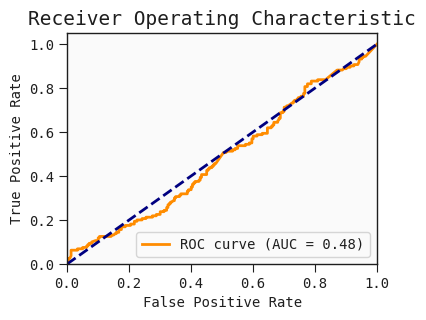

In [353]:
y_true_list_rf_omics_demoM = extract_results(results_rf_omics_demoM, 'y_true')
y_pred_prob_list_rf_omics_demoM = extract_results(results_rf_omics_demoM, 'y_pred_prob')
y_pred_list_rf_omics_demoM = extract_results(results_rf_omics_demoM, 'y_pred')
feature_selection_df_rf_omics_demoM = extract_results(results_rf_omics_demoM, 'feature_selection_df')
feature_sum_coef_df_rf_omics_demoM = extract_results(results_rf_omics_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_demoM}, Median AUC: {median_auc_rf_omics_demoM}, IQR : {iqr_auc_rf_omics_demoM}, IQ1-IQ3: {iqr13_auc_rf_omics_demoM}") 
auc_plot(extract_results(results_rf_omics_demoM, 'y_true'), extract_results(results_rf_omics_demoM, 'y_pred_prob'))

### QLattice

#### QLattice-Full No feature selection

In [18]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_demo, overall_auc_ql_omics_demo, median_auc_ql_omics_demo, iqr_auc_ql_omics_demo, iqr13_auc_ql_omics_demo = run_multiple_evaluations_parallel(model_omics_df_demo, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.5733350649350649, Median AUC: 0.5748051948051947, IQR : 0.03558441558441561, IQ1-IQ3: (0.545974025974026, 0.5815584415584416)


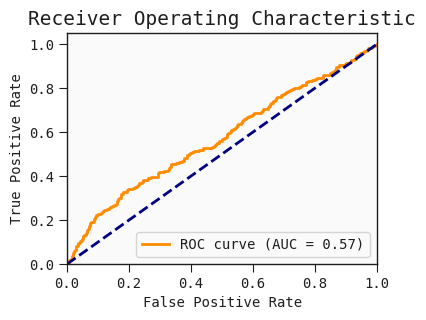

In [20]:
y_true_list_ql_omics_demo = extract_results(results_ql_omics_demo, 'y_true')
y_pred_prob_list_ql_omics_demo= extract_results(results_ql_omics_demo, 'y_pred_prob')
y_pred_list_ql_omics_demo = extract_results(results_ql_omics_demo, 'y_pred')
feature_selection_df_ql_omics_demo = extract_results(results_ql_omics_demo, 'feature_selection_df')
feature_sum_coef_df_ql_omics_demo = extract_results(results_ql_omics_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_demo}, Median AUC: {median_auc_ql_omics_demo}, IQR : {iqr_auc_ql_omics_demo}, IQ1-IQ3: {iqr13_auc_ql_omics_demo}") 
auc_plot(extract_results(results_ql_omics_demo, 'y_true'), extract_results(results_ql_omics_demo, 'y_pred_prob'))

#### QLattice-Female No feature selection

In [18]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_demoF, overall_auc_ql_omics_demoF, median_auc_ql_omics_demoF, iqr_auc_ql_omics_demoF, iqr13_auc_ql_omics_demoF = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.7517741935483871, Median AUC: 0.7364176570458404, IQR : 0.07873514431239381, IQ1-IQ3: (0.7188030560271648, 0.7975382003395586)


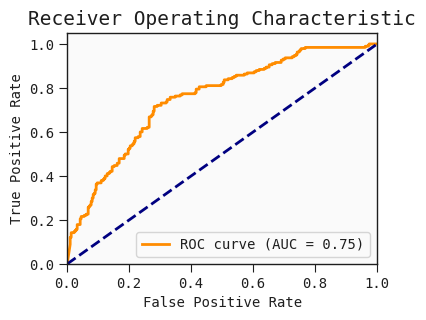

In [20]:
y_true_list_ql_omics_demoF = extract_results(results_ql_omics_demoF, 'y_true')
y_pred_prob_list_ql_omics_demoF = extract_results(results_ql_omics_demoF, 'y_pred_prob')
y_pred_list_ql_omics_demoF= extract_results(results_ql_omics_demoF, 'y_pred')
feature_selection_df_ql_omics_demoF= extract_results(results_ql_omics_demoF, 'feature_selection_df')
feature_sum_coef_df_ql_omics_demoF= extract_results(results_ql_omics_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_demoF}, Median AUC: {median_auc_ql_omics_demoF}, IQR : {iqr_auc_ql_omics_demoF}, IQ1-IQ3: {iqr13_auc_ql_omics_demoF}") 
auc_plot(extract_results(results_ql_omics_demoF, 'y_true'), extract_results(results_ql_omics_demoF, 'y_pred_prob'))

#### QLattice-Male No feature selection

In [21]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_demoM, overall_auc_ql_omics_demoM, median_auc_ql_omics_demoM, iqr_auc_ql_omics_demoM, iqr13_auc_ql_omics_demoM = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.6918229166666666, Median AUC: 0.7005208333333334, IQR : 0.14355468750000022, IQ1-IQ3: (0.6363932291666665, 0.7799479166666667)


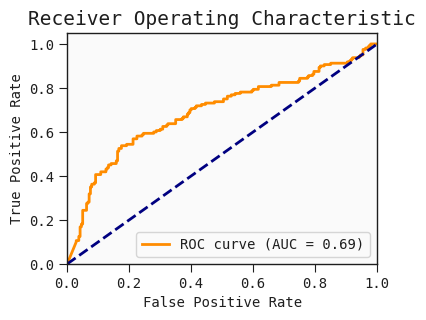

In [23]:
y_true_list_ql_omics_demoM = extract_results(results_ql_omics_demoM, 'y_true')
y_pred_prob_list_ql_omics_demoM = extract_results(results_ql_omics_demoM, 'y_pred_prob')
y_pred_list_ql_omics_demoM = extract_results(results_ql_omics_demoM, 'y_pred')
feature_selection_df_ql_omics_demoM = extract_results(results_ql_omics_demoM, 'feature_selection_df')
feature_sum_coef_df_ql_omics_demoM = extract_results(results_ql_omics_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_demoM}, Median AUC: {median_auc_ql_omics_demoM}, IQR : {iqr_auc_ql_omics_demoM}, IQ1-IQ3: {iqr13_auc_ql_omics_demoM}") 
auc_plot(extract_results(results_ql_omics_demoM, 'y_true'), extract_results(results_ql_omics_demoM, 'y_pred_prob'))

## Omics+APOE4+Demo

In [131]:
################ OMICS + APOE4 + Demo ####################
model_omics_APOE4_demo_df_full = omics_demo_normalise_df_no_missing.copy()
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_APOE4_demo = ['APOE4', 'Demographic.Sex', 'Demographic.Years.of.Education.Exact','Age']
omics_APOE4_demo_lst = list((set(model_omics_APOE4_demo_df_full.columns.to_list()) - set(demo_lst_full)) | set(omics_APOE4_demo))
print(len(omics_APOE4_demo_lst))
model_omics_APOE4_demo_df = model_omics_APOE4_demo_df_full[omics_APOE4_demo_lst]
model_omics_APOE4_demo_df_M = model_omics_APOE4_demo_df[model_omics_APOE4_demo_df['Demographic.Sex']==1]
model_omics_APOE4_demo_df_M = model_omics_APOE4_demo_df_M.drop(['Demographic.Sex'], axis=1)
model_omics_APOE4_demo_df_F = model_omics_APOE4_demo_df[model_omics_APOE4_demo_df['Demographic.Sex']==0]
model_omics_APOE4_demo_df_F = model_omics_APOE4_demo_df_F.drop(['Demographic.Sex'], axis=1)
# model_omics_APOE4_demo_df = model_omics_APOE4_demo_df.drop(['Demographic.Sex'], axis=1)

1946


### Logistic Regression with Lasso

#### L1-Full No feature selection

In [132]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4_demo, overall_auc_lr_omics_APOE4_demo, median_auc_lr_omics_APOE4_demo, iqr_auc_lr_omics_APOE4_demo, iqr13_auc_lr_omics_APOE4_demo = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (5, l1, liblinear)
test_auc              0.684722
Name: 8, dtype: object

params      (100, l1, liblinear)
test_auc                0.631481
Name: 12, dtype: object

params      (0.01, l1, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (1, l1, liblinear)
test_auc              0.743796
Name: 6, dtype: object

params      (0.5, l1, saga)
test_auc           0.645741
Name: 5, dtype: object

...

params      (0.5, l1, liblinear)
test_auc                0.566389
Name: 4, dtype: object

params      (100, l1, saga)
test_auc           0.558426
Name: 13, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.779907
Name: 4, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.739907
Name: 4, dtype: object

params      (100, l1, saga)
test_auc           0.605556
Name: 13, dtype: object

Overall AUC: 0.4702779220779221, Median AUC: 0.4567532467532467, IQR : 0.041493506493506416, IQ1-IQ3: (0.43766233766233764, 0.47915584415584406)


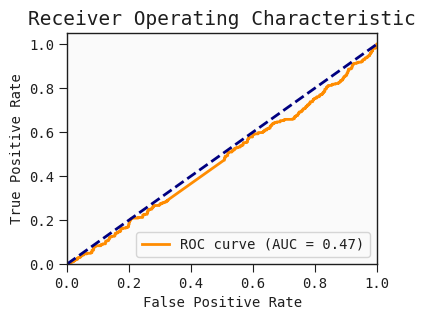

In [134]:
y_true_list_lr_omics_APOE4_demo = extract_results(results_lr_omics_APOE4_demo, 'y_true')
y_pred_prob_list_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'y_pred_prob')
y_pred_list_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'y_pred')
feature_selection_df_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4_demo}, Median AUC: {median_auc_lr_omics_APOE4_demo}, IQR : {iqr_auc_lr_omics_APOE4_demo}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4_demo}") 
auc_plot(extract_results(results_lr_omics_APOE4_demo, 'y_true'), extract_results(results_lr_omics_APOE4_demo, 'y_pred_prob'))

#### L1-Female No feature selection

In [135]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4_demoF, overall_auc_lr_omics_APOE4_demoF, median_auc_lr_omics_APOE4_demoF, iqr_auc_lr_omics_APOE4_demoF, iqr13_auc_lr_omics_APOE4_demoF = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (1, l1, saga)
test_auc         0.906667
Name: 7, dtype: object

params      (5, l1, liblinear)
test_auc              0.893333
Name: 8, dtype: object

params      (0.5, l1, saga)
test_auc           0.813333
Name: 5, dtype: object

params      (5, l1, liblinear)
test_auc                   0.8
Name: 8, dtype: object

params      (1, l1, liblinear)
test_auc              0.893333
Name: 6, dtype: object

...

params      (0.5, l1, saga)
test_auc           0.828333
Name: 5, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.920833
Name: 4, dtype: object

params      (0.5, l1, liblinear)
test_auc                0.764167
Name: 4, dtype: object

params      (0.5, l1, saga)
test_auc               0.92
Name: 5, dtype: object

params      (100, l1, liblinear)
test_auc                0.800833
Name: 12, dtype: object

Overall AUC: 0.7720543293718167, Median AUC: 0.7869269949066214, IQR : 0.021222410865874508, IQ1-IQ3: (0.7695246179966043, 0.7907470288624788)


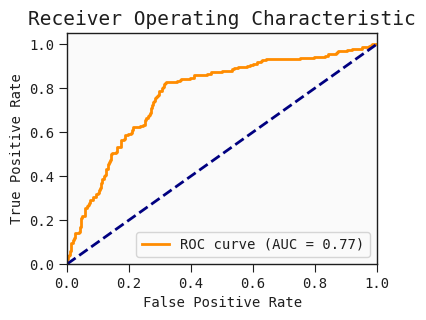

In [137]:
y_true_list_lr_omics_APOE4_demoF = extract_results(results_lr_omics_APOE4_demoF, 'y_true')
y_pred_prob_list_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'y_pred_prob')
y_pred_list_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'y_pred')
feature_selection_df_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4_demoF}, Median AUC: {median_auc_lr_omics_APOE4_demoF}, IQR : {iqr_auc_lr_omics_APOE4_demoF}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4_demoF}") 
auc_plot(extract_results(results_lr_omics_APOE4_demoF, 'y_true'), extract_results(results_lr_omics_APOE4_demoF, 'y_pred_prob'))

In [138]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
y_true_list_lr_omics_APOE4_demoF_single, y_pred_prob_list_lr_omics_APOE4_demoF_single, y_pred_list_lr_omics_APOE4_demoF_single, feature_selection_df_lr_omics_APOE4_demoF_single=evaluate_full_dataset(model_omics_APOE4_demo_df_F, 'logistic_regression', lr_param_combinations, feature_selection_method=None, num_features=None)

params      (100, l1, liblinear)
test_auc                0.905952
Name: 12, dtype: object

In [157]:
feature_selection_df_lr_omics_APOE4_demoF_single['Feature'] = feature_selection_df_lr_omics_APOE4_demoF_single['Feature'].map(mapping_dict)

In [199]:
print(feature_selection_df_lr_omics_APOE4_demoF_single.shape)

(39, 2)


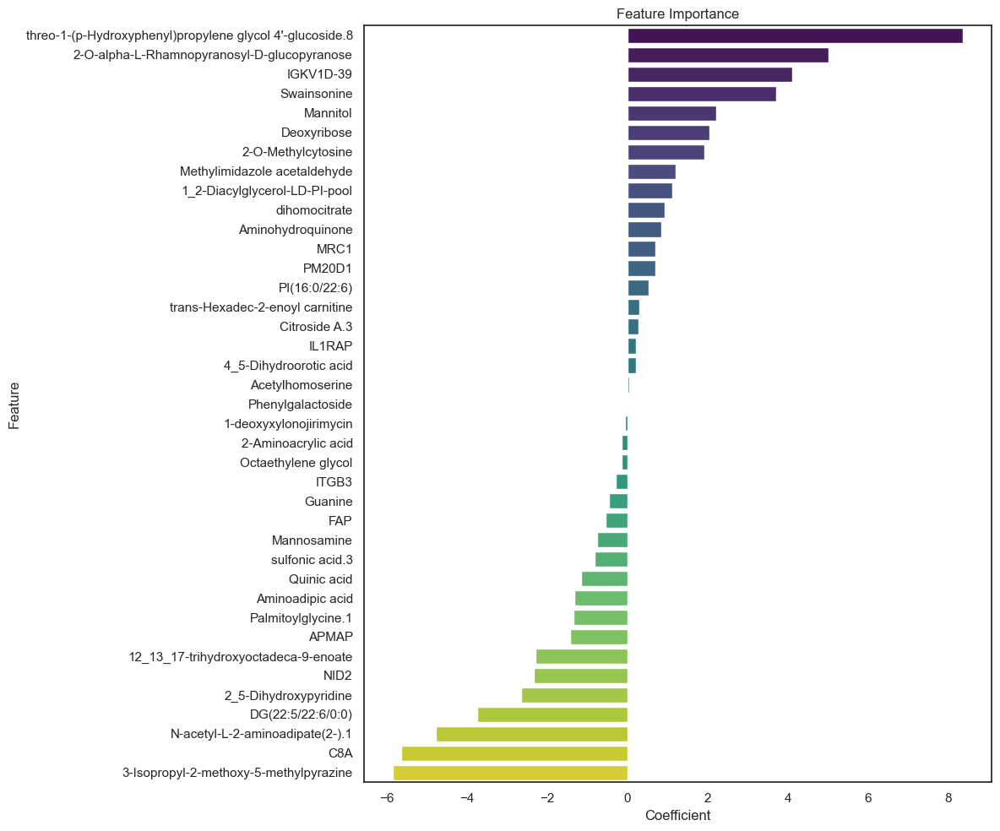

In [197]:
plt.figure(figsize=(12, 10))

sns.barplot(
    x='CoefficientSum', 
    y='Feature', 
    data=feature_selection_df_lr_omics_APOE4_demoF_single, 
    palette='viridis'
)

plt.title('Feature Importance')
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.yticks(fontsize=11)
plt.tight_layout()
plt.savefig("single_coeff_Female.pdf", format='pdf')
plt.show()

In [161]:
feature_selection_df_lr_omics_APOE4_demoF['Feature'] = feature_selection_df_lr_omics_APOE4_demoF['Feature'].map(mapping_dict)
feature_sum_coef_df_lr_omics_APOE4_demoF['Feature'] = feature_sum_coef_df_lr_omics_APOE4_demoF['Feature'].map(mapping_dict)

In [168]:
feature_selection_df_lr_omics_APOE4_demoF = feature_selection_df_lr_omics_APOE4_demoF.sort_values(by='Total Count', ascending=False)
feature_selection_df_lr_omics_APOE4_demoF.to_csv("../results/Lasso_female_omics_APOE_DEMO_feature_selected.csv", index=False)
feature_sum_coef_df_lr_omics_APOE4_demoF = feature_sum_coef_df_lr_omics_APOE4_demoF.sort_values(by='Coefficient Sum', ascending=False)
feature_sum_coef_df_lr_omics_APOE4_demoF.to_csv("../results/Lasso_female_omics_APOE_DEMO_feature_sum_coefficient.csv", index=False)
feature_selection_df_lr_omics_APOE4_demoF_single = feature_selection_df_lr_omics_APOE4_demoF_single.sort_values(by='CoefficientSum', ascending=False)
feature_selection_df_lr_omics_APOE4_demoF_single.to_csv("../results/Lasso_female_omics_APOE_DEMO_feature_single_coefficient.csv", index=False)

#### L1-Male No feature selection

In [142]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4_demoM, overall_auc_lr_omics_APOE4_demoM, median_auc_lr_omics_APOE4_demoM, iqr_auc_lr_omics_APOE4_demoM, iqr13_auc_lr_omics_APOE4_demoM = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

params      (5, l1, liblinear)
test_auc                  0.95
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.883333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.683333
Name: 8, dtype: object

params      (5, l1, liblinear)
test_auc              0.933333
Name: 8, dtype: object

params      (10, l1, liblinear)
test_auc               0.758333
Name: 10, dtype: object

...

params      (1, l1, liblinear)
test_auc              0.908333
Name: 6, dtype: object

params      (10, l1, liblinear)
test_auc               0.713889
Name: 10, dtype: object

params      (10, l1, liblinear)
test_auc               0.755556
Name: 10, dtype: object

params      (5, l1, liblinear)
test_auc              0.911111
Name: 8, dtype: object

params      (100, l1, liblinear)
test_auc                    0.85
Name: 12, dtype: object

Overall AUC: 0.8225651041666666, Median AUC: 0.8203125, IQR : 0.07779947916666674, IQ1-IQ3: (0.7952473958333333, 0.873046875)


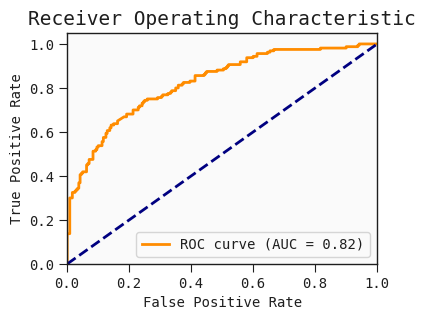

In [144]:
y_true_list_lr_omics_APOE4_demoM = extract_results(results_lr_omics_APOE4_demoM, 'y_true')
y_pred_prob_list_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'y_pred_prob')
y_pred_list_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'y_pred')
feature_selection_df_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4_demoM}, Median AUC: {median_auc_lr_omics_APOE4_demoM}, IQR : {iqr_auc_lr_omics_APOE4_demoM}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4_demoM}") 
auc_plot(extract_results(results_lr_omics_APOE4_demoM, 'y_true'), extract_results(results_lr_omics_APOE4_demoM, 'y_pred_prob'))

In [145]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
y_true_list_lr_omics_APOE4_demoM_single, y_pred_prob_list_lr_omics_APOE4_demoM_single, y_pred_list_lr_omics_APOE4_demoM_single, feature_selection_df_lr_omics_APOE4_demoM_single=evaluate_full_dataset(model_omics_APOE4_demo_df_M, 'logistic_regression', lr_param_combinations, feature_selection_method=None, num_features=None)

params      (5, l1, liblinear)
test_auc              0.893333
Name: 8, dtype: object

In [169]:
feature_selection_df_lr_omics_APOE4_demoM_single['Feature'] = feature_selection_df_lr_omics_APOE4_demoM_single['Feature'].map(mapping_dict)

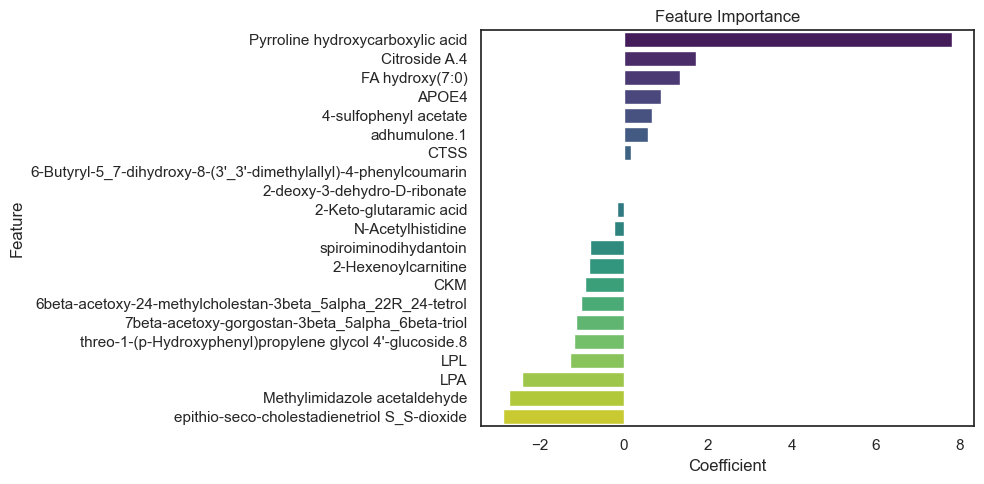

In [196]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x='CoefficientSum', 
    y='Feature', 
    data=feature_selection_df_lr_omics_APOE4_demoM_single, 
    palette='viridis'
)

plt.title('Feature Importance')
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.yticks(fontsize=11)
plt.tight_layout()
plt.savefig("../plots/single_coeff_Male.pdf", format='pdf')
plt.show()

In [170]:
feature_selection_df_lr_omics_APOE4_demoM['Feature'] = feature_selection_df_lr_omics_APOE4_demoM['Feature'].map(mapping_dict)
feature_sum_coef_df_lr_omics_APOE4_demoM['Feature'] = feature_sum_coef_df_lr_omics_APOE4_demoM['Feature'].map(mapping_dict)

In [171]:
feature_selection_df_lr_omics_APOE4_demoM = feature_selection_df_lr_omics_APOE4_demoM.sort_values(by='Total Count', ascending=False)
feature_selection_df_lr_omics_APOE4_demoM.to_csv("../results/Lasso_male_omics_APOE_DEMO_feature_selected.csv", index=False)
feature_sum_coef_df_lr_omics_APOE4_demoM = feature_sum_coef_df_lr_omics_APOE4_demoM.sort_values(by='Coefficient Sum', ascending=False)
feature_sum_coef_df_lr_omics_APOE4_demoM.to_csv("../results/Lasso_male_omics_APOE_DEMO_feature_sum_coefficient.csv", index=False)
feature_selection_df_lr_omics_APOE4_demoM_single = feature_selection_df_lr_omics_APOE4_demoM_single.sort_values(by='CoefficientSum', ascending=False)
feature_selection_df_lr_omics_APOE4_demoM_single.to_csv("../results/Lasso_male_omics_APOE_DEMO_feature_single_coefficient.csv", index=False)

### Logistic Regression with Ridge

#### L2-Full No feature selection

In [354]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demo, overall_auc_lr2_omics_APOE4_demo, median_auc_lr2_omics_APOE4_demo, iqr_auc_lr2_omics_APOE4_demo, iqr13_auc_lr2_omics_APOE4_demo = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (0.5, l2, liblinear)
test_auc                0.550093
Name: 4, dtype: object

params      (5, l2, liblinear)
test_auc               0.43037
Name: 8, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.491852
Name: 4, dtype: object

params      (5, l2, liblinear)
test_auc              0.484444
Name: 8, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.450093
Name: 0, dtype: object

...

params      (5, l2, liblinear)
test_auc              0.501111
Name: 8, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.499907
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.570185
Name: 0, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.539722
Name: 4, dtype: object

params      (0.5, l2, saga)
test_auc            0.60287
Name: 5, dtype: object

Overall AUC: 0.49695584415584415, Median AUC: 0.5015584415584415, IQR : 0.042857142857142816, IQ1-IQ3: (0.4741558441558442, 0.517012987012987)


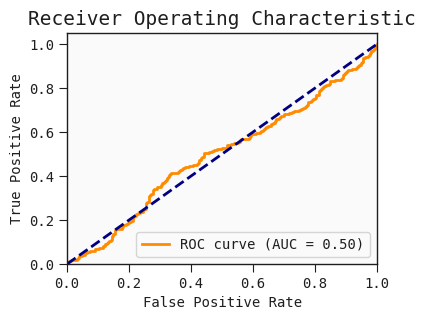

In [356]:
y_true_list_lr2_omics_APOE4_demo = extract_results(results_lr2_omics_APOE4_demo, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demo = extract_results(results_lr2_omics_APOE4_demo, 'y_pred_prob')
y_pred_list_lr2_omic_APOE4_demos_APOE4_demo = extract_results(results_lr2_omics_APOE4_demo, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demo = extract_results(results_lr2_omics_APOE4_demo, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demo = extract_results(results_lr2_omics_APOE4_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demo}, Median AUC: {median_auc_lr2_omics_APOE4_demo}, IQR : {iqr_auc_lr2_omics_APOE4_demo}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demo}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demo, 'y_true'), extract_results(results_lr2_omics_APOE4_demo, 'y_pred_prob'))

#### L2-Full RFE20

In [357]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demo_rfe, overall_auc_lr2_omics_APOE4_demo_rfe, median_auc_lr2_omics_APOE4_demo_rfe, iqr_auc_lr2_omics_APOE4_demo_rfe, iqr13_auc_lr2_omics_APOE4_demo_rfe = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, l2, liblinear)
test_auc                0.484352
Name: 2, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, l2, liblinear)
test_auc                 0.703704
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, l2, saga)
test_auc         0.536574
Name: 7, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, liblinear)
test_auc              0.633519
Name: 8, dtype: object

Do RFE feature Selection


Overall AUC: 0.4898753246753247, Median AUC: 0.4766233766233766, IQR : 0.09558441558441555, IQ1-IQ3: (0.45025974025974025, 0.5458441558441558)


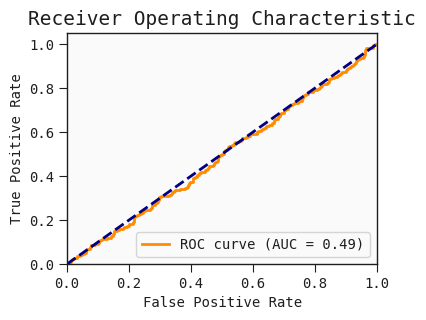

In [359]:
y_true_list_lr2_omics_APOE4_demo_rfe = extract_results(results_lr2_omics_APOE4_demo_rfe, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demo_rfe= extract_results(results_lr2_omics_APOE4_demo_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demo_rfe= extract_results(results_lr2_omics_APOE4_demo_rfe, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demo_rfe= extract_results(results_lr2_omics_APOE4_demo_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demo_rfe= extract_results(results_lr2_omics_APOE4_demo_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demo_rfe}, Median AUC: {median_auc_lr2_omics_APOE4_demo_rfe}, IQR : {iqr_auc_lr2_omics_APOE4_demo_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demo_rfe}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demo_rfe, 'y_true'), extract_results(results_lr2_omics_APOE4_demo_rfe, 'y_pred_prob'))

#### L2-Full MRMR20

In [360]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demo_mrmr, overall_auc_lr2_omics_APOE4_demo_mrmr, median_auc_lr2_omics_APOE4_demo_mrmr, iqr_auc_lr2_omics_APOE4_demo_mrmr, iqr13_auc_lr2_omics_APOE4_demo_mrmr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:07,  2.39it/s]





 15%|█▌        | 3/20 [00:01<00:05,  2.90it/s]





 20%|██        | 4/20 [00:01<00:05,  2.92it/s]





 25%|██▌       | 5/20 [00:01<00:04,  3.18it/s]





 30%|███       | 6/20 [00:01<00:04,  3.29it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.42it/s]





 40%|████      | 8/20 [00:02<00:03,  3.54it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.65it/s]





 50%|█████     | 10/20 [00:02<00:02,  3.80it/s]




 55%|█████▌    | 11/20 [00:03<00:02,  3.91it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.80it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.63it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.61it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.53it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.63it/s]





 85%|████████▌ | 17/20 [00:04<00:00,  3.65it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.63it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.55it/s]





100%|█████████

Do MRMR feature selection



100%|██████████| 20/20 [00:05<00:00,  3.59it/s]






Do MRMR feature selection


...

Do MRMR feature selection
Do MRMR feature selection


params      (100, l2, liblinear)
test_auc                0.392315
Name: 12, dtype: object

 20%|██        | 4/20 [00:00<00:04,  3.63it/s]

Do MRMR feature selection






 25%|██▌       | 5/20 [00:01<00:06,  2.40it/s]





 30%|███       | 6/20 [00:01<00:05,  2.76it/s]





 35%|███▌      | 7/20 [00:02<00:04,  2.90it/s]





 40%|████      | 8/20 [00:02<00:03,  3.07it/s]





100%|██████████| 20/20 [00:06<00:00,  3.12it/s]



 50%|█████     | 10/20 [00:03<00:02,  3.66it/s]


 55%|█████▌    | 11/20 [00:03<00:02,  3.79it/s]


 60%|██████    | 12/20 [00:03<00:02,  3.98it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  4.26it/s]


 70%|███████   | 14/20 [00:03<00:01,  4.26it/s]


 75%|███████▌  | 15/20 [00:04<00:01,  4.32it/s]


 80%|████████  | 16/20 [00:04<00:00,  4.38it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.57it/s]

 90%|█████████ | 18/20 [00:04<00:00,  4.51it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.50it/s]


100%|██████████| 20/20 [00:05<00:00,  3.83it/s]










100%|██████████| 20/20 [00:04<00:00,  4.37it/s]



100%|██████████| 20/20 [00:04<00:00,  4.55it/s]


100%|██████████| 20/20 [00:04<00:00,  4.83it/s]


Overall AUC: 0.4736987012987013, Median AUC: 0.4545454545454546, IQR : 0.04350649350649355, IQ1-IQ3: (0.4468831168831168, 0.4903896103896104)


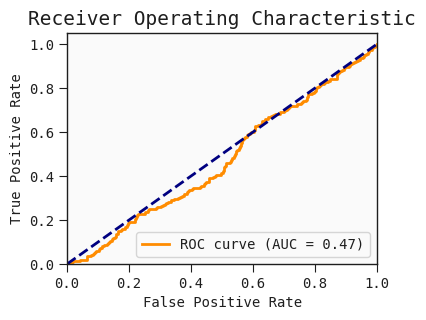

In [362]:
y_true_list_lr2_omics_APOE4_demo_mrmr = extract_results(results_lr2_omics_APOE4_demo_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demo_mrmr= extract_results(results_lr2_omics_APOE4_demo_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demo_mrmr= extract_results(results_lr2_omics_APOE4_demo_mrmr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demo_mrmr= extract_results(results_lr2_omics_APOE4_demo_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demo_mrmr= extract_results(results_lr2_omics_APOE4_demo_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demo_mrmr}, Median AUC: {median_auc_lr2_omics_APOE4_demo_mrmr}, IQR : {iqr_auc_lr2_omics_APOE4_demo_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demo_mrmr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demo_mrmr, 'y_true'), extract_results(results_lr2_omics_APOE4_demo_mrmr, 'y_pred_prob'))

#### L2-Full correlation20

In [363]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demo_corr, overall_auc_lr2_omics_APOE4_demo_corr, median_auc_lr2_omics_APOE4_demo_corr, iqr_auc_lr2_omics_APOE4_demo_corr, iqr13_auc_lr2_omics_APOE4_demo_corr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (1, l2, saga)
test_auc         0.431204
Name: 7, dtype: object

params      (100, l2, liblinear)
test_auc                0.697593
Name: 12, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.705648
Name: 0, dtype: object

params      (100, l2, liblinear)
test_auc                  0.5575
Name: 12, dtype: object

...

params      (100, l2, liblinear)
test_auc                0.684167
Name: 12, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, saga)
test_auc           0.495278
Name: 13, dtype: object

params      (100, l2, liblinear)
test_auc                0.408148
Name: 12, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.46515324675324676, Median AUC: 0.4737662337662337, IQR : 0.026363636363636367, IQ1-IQ3: (0.45025974025974025, 0.4766233766233766)


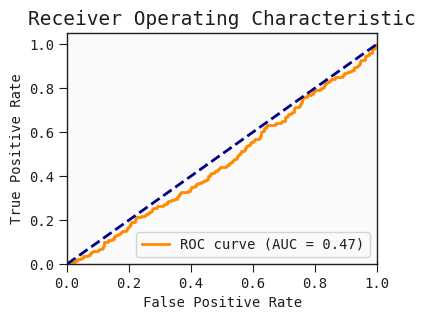

In [365]:
y_true_list_lr2_omics_APOE4_demo_corr = extract_results(results_lr2_omics_APOE4_demo_corr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demo_corr= extract_results(results_lr2_omics_APOE4_demo_corr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demo_corr= extract_results(results_lr2_omics_APOE4_demo_corr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demo_corr= extract_results(results_lr2_omics_APOE4_demo_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demo_corr= extract_results(results_lr2_omics_APOE4_demo_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demo_corr}, Median AUC: {median_auc_lr2_omics_APOE4_demo_corr}, IQR : {iqr_auc_lr2_omics_APOE4_demo_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demo_corr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demo_corr, 'y_true'), extract_results(results_lr2_omics_APOE4_demo_corr, 'y_pred_prob'))

#### L2-Female No feature selection

In [366]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoF, overall_auc_lr2_omics_APOE4_demoF, median_auc_lr2_omics_APOE4_demoF, iqr_auc_lr2_omics_APOE4_demoF, iqr13_auc_lr2_omics_APOE4_demoF = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (100, l2, liblinear)
test_auc                0.706667
Name: 12, dtype: object

params      (0.01, l2, liblinear)
test_auc                     0.64
Name: 0, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.733333
Name: 0, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.613333
Name: 4, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.706667
Name: 2, dtype: object

...

params      (0.5, l2, liblinear)
test_auc                0.669167
Name: 4, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.711667
Name: 0, dtype: object

params      (100, l2, liblinear)
test_auc                  0.4475
Name: 12, dtype: object

params      (0.5, l2, saga)
test_auc           0.566667
Name: 5, dtype: object

params      (0.5, l2, liblinear)
test_auc                0.726667
Name: 4, dtype: object

Overall AUC: 0.6124108658743633, Median AUC: 0.6044142614601018, IQR : 0.05263157894736836, IQ1-IQ3: (0.5963497453310695, 0.6489813242784379)


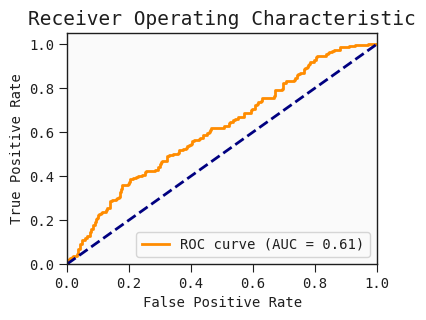

In [368]:
y_true_list_lr2_omics_APOE4_demoF = extract_results(results_lr2_omics_APOE4_demoF, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoF= extract_results(results_lr2_omics_APOE4_demoF, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoF= extract_results(results_lr2_omics_APOE4_demoF, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoF= extract_results(results_lr2_omics_APOE4_demoF, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoF= extract_results(results_lr2_omics_APOE4_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoF}, Median AUC: {median_auc_lr2_omics_APOE4_demoF}, IQR : {iqr_auc_lr2_omics_APOE4_demoF}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoF}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoF, 'y_true'), extract_results(results_lr2_omics_APOE4_demoF, 'y_pred_prob'))

#### L2-Female RFE20

In [369]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoF_rfe, overall_auc_lr2_omics_APOE4_demoF_rfe, median_auc_lr2_omics_APOE4_demoF_rfe, iqr_auc_lr2_omics_APOE4_demoF_rfe, iqr13_auc_lr2_omics_APOE4_demoF_rfe = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, saga)
test_auc           0.813333
Name: 13, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.5, l2, saga)
test_auc           0.893333
Name: 5, dtype: object

Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, l2, saga)
test_auc          0.856667
Name: 11, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, saga)
test_auc         0.765833
Name: 9, dtype: object

Do RFE feature Selection


Overall AUC: 0.7168760611205433, Median AUC: 0.7292020373514432, IQR : 0.055178268251273255, IQ1-IQ3: (0.6926994906621393, 0.7478777589134126)


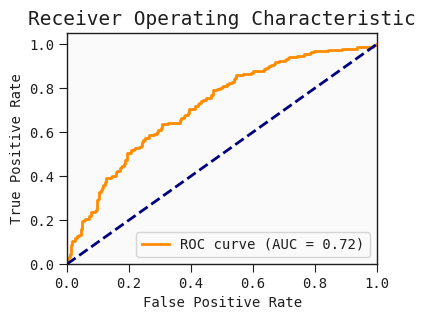

In [371]:
y_true_list_lr2_omics_APOE4_demoF_rfe = extract_results(results_lr2_omics_APOE4_demoF_rfe, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoF_rfe = extract_results(results_lr2_omics_APOE4_demoF_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoF_rfe = extract_results(results_lr2_omics_APOE4_demoF_rfe, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoF_rfe = extract_results(results_lr2_omics_APOE4_demoF_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoF_rfe = extract_results(results_lr2_omics_APOE4_demoF_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoF_rfe}, Median AUC: {median_auc_lr2_omics_APOE4_demoF_rfe}, IQR : {iqr_auc_lr2_omics_APOE4_demoF_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoF_rfe}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoF_rfe, 'y_true'), extract_results(results_lr2_omics_APOE4_demoF_rfe, 'y_pred_prob'))

#### L2-Female MRMR20

In [19]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoF_mrmr, overall_auc_lr2_omics_APOE4_demoF_mrmr, median_auc_lr2_omics_APOE4_demoF_mrmr, iqr_auc_lr2_omics_APOE4_demoF_mrmr, iqr13_auc_lr2_omics_APOE4_demoF_mrmr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.22it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.56it/s]





 20%|██        | 4/20 [00:01<00:05,  2.68it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.05it/s]





 30%|███       | 6/20 [00:02<00:04,  3.09it/s]






 35%|███▌      | 7/20 [00:02<00:04,  2.76it/s]





 40%|████      | 8/20 [00:02<00:04,  2.97it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.16it/s]





 50%|█████     | 10/20 [00:03<00:03,  3.21it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.35it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.52it/s]





 65%|██████▌   | 13/20 [00:04<00:01,  3.54it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.27it/s]




 75%|███████▌  | 15/20 [00:04<00:01,  3.40it/s]





 80%|████████  | 16/20 [00:05<00:01,  3.51it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.22it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.26it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.27it/s]





100%|██████████|

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:10,  1.70it/s]


 15%|█▌        | 3/20 [00:01<00:08,  2.03it/s]





 20%|██        | 4/20 [00:01<00:07,  2.09it/s]





 25%|██▌       | 5/20 [00:02<00:06,  2.45it/s]





 30%|███       | 6/20 [00:02<00:04,  2.83it/s]





 35%|███▌      | 7/20 [00:02<00:04,  2.97it/s]



 40%|████      | 8/20 [00:03<00:03,  3.30it/s]





 45%|████▌     | 9/20 [00:03<00:03,  3.43it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.44it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.43it/s]





 60%|██████    | 12/20 [00:04<00:02,  3.49it/s]





 65%|██████▌   | 13/20 [00:04<00:01,  3.61it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.42it/s]





 75%|███████▌  | 15/20 [00:05<00:01,  3.49it/s]







 80%|████████  | 16/20 [00:05<00:01,  3.02it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.17it/s]





 90%|█████████ | 18/20 [00:06<00:00,  3.23it/s]





 95%|█████████▌| 19/20 [00:06<00:00,  3.39it/s]





100%|██████████|

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


...

Do MRMR feature selection
Do MRMR feature selection


100%|██████████| 20/20 [00:05<00:00,  3.50it/s]


params      (0.1, l2, liblinear)
test_auc                  0.7625
Name: 2, dtype: object

Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]



 10%|█         | 2/20 [00:00<00:05,  3.39it/s]





 15%|█▌        | 3/20 [00:00<00:04,  3.88it/s]





 20%|██        | 4/20 [00:01<00:04,  3.83it/s]



 25%|██▌       | 5/20 [00:01<00:03,  3.80it/s]





 30%|███       | 6/20 [00:01<00:03,  3.79it/s]





 35%|███▌      | 7/20 [00:01<00:03,  3.84it/s]





 40%|████      | 8/20 [00:02<00:03,  3.79it/s]





 45%|████▌     | 9/20 [00:02<00:02,  3.83it/s]





 50%|█████     | 10/20 [00:02<00:02,  3.82it/s]





 55%|█████▌    | 11/20 [00:02<00:02,  3.88it/s]



100%|██████████| 20/20 [00:05<00:00,  3.37it/s]


 60%|██████    | 12/20 [00:03<00:02,  3.91it/s]


 65%|██████▌   | 13/20 [00:03<00:01,  4.24it/s]


 70%|███████   | 14/20 [00:03<00:01,  4.32it/s]


 75%|███████▌  | 15/20 [00:03<00:01,  4.36it/s]


 80%|████████  | 16/20 [00:04<00:00,  4.17it/s]


100%|██████████| 20/20 [00:05<00:00,  3.61it/s]


 90%|█████████ | 18/20 [00:04<00:00,  4.42it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.

Overall AUC: 0.6864346349745332, Median AUC: 0.6901528013582343, IQR : 0.06876061120543298, IQ1-IQ3: (0.6595925297113752, 0.7283531409168081)


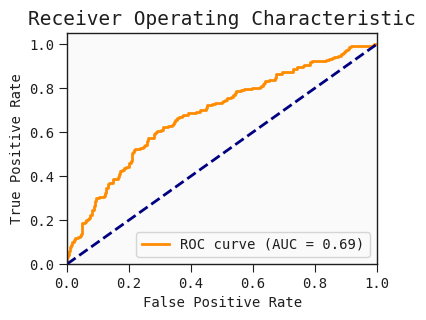

In [21]:
y_true_list_lr2_omics_APOE4_demoF_mrmr = extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoF_mrmr = extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoF_mrmr = extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoF_mrmr = extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoF_mrmr = extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoF_mrmr}, Median AUC: {median_auc_lr2_omics_APOE4_demoF_mrmr}, IQR : {iqr_auc_lr2_omics_APOE4_demoF_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoF_mrmr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_true'), extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_pred_prob'))

#### L2-Female correlation20

In [374]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoF_mrmr, overall_auc_lr2_omics_APOE4_demoF_mrmr, median_auc_lr2_omics_APOE4_demoF_mrmr, iqr_auc_lr2_omics_APOE4_demoF_mrmr, iqr13_auc_lr2_omics_APOE4_demoF_mrmr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:01<00:14,  1.23it/s]





 15%|█▌        | 3/20 [00:02<00:10,  1.67it/s]





 20%|██        | 4/20 [00:02<00:09,  1.72it/s]





 25%|██▌       | 5/20 [00:03<00:09,  1.66it/s]





 30%|███       | 6/20 [00:03<00:06,  2.01it/s]





 35%|███▌      | 7/20 [00:03<00:05,  2.34it/s]





 40%|████      | 8/20 [00:03<00:04,  2.55it/s]





 45%|████▌     | 9/20 [00:04<00:03,  2.82it/s]





 50%|█████     | 10/20 [00:04<00:03,  2.95it/s]





 55%|█████▌    | 11/20 [00:04<00:02,  3.15it/s]





 60%|██████    | 12/20 [00:05<00:02,  3.27it/s]





 65%|██████▌   | 13/20 [00:05<00:02,  3.32it/s]





 70%|███████   | 14/20 [00:05<00:01,  3.20it/s]





 75%|███████▌  | 15/20 [00:06<00:01,  3.17it/s]





 80%|████████  | 16/20 [00:06<00:01,  3.27it/s]





 85%|████████▌ | 17/20 [00:06<00:00,  3.36it/s]





 90%|█████████ | 18/20 [00:06<00:00,  3.45it/s]





 95%|█████████▌| 19/20 [00:07<00:00,  3.51it/s]





100%|████████

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:06<00:00,  3.20it/s]


Do MRMR feature selection


...



 15%|█▌        | 3/20 [00:00<00:05,  3.36it/s]





 20%|██        | 4/20 [00:01<00:06,  2.65it/s]





 25%|██▌       | 5/20 [00:01<00:05,  2.88it/s]





100%|██████████| 20/20 [00:06<00:00,  3.05it/s]







params      (0.1, l2, liblinear)
test_auc                  0.7625
Name: 2, dtype: object

 35%|███▌      | 7/20 [00:02<00:03,  3.42it/s]]

Do MRMR feature selection








 40%|████      | 8/20 [00:02<00:04,  2.47it/s]



100%|██████████| 20/20 [00:07<00:00,  2.84it/s]


 45%|████▌     | 9/20 [00:03<00:04,  2.52it/s]


 50%|█████     | 10/20 [00:03<00:03,  2.94it/s]


 55%|█████▌    | 11/20 [00:03<00:02,  3.17it/s]


 60%|██████    | 12/20 [00:03<00:02,  3.56it/s]


 65%|██████▌   | 13/20 [00:04<00:01,  3.69it/s]


 70%|███████   | 14/20 [00:04<00:01,  3.94it/s]


 75%|███████▌  | 15/20 [00:04<00:01,  4.11it/s]


 80%|████████  | 16/20 [00:04<00:00,  4.09it/s]


 85%|████████▌ | 17/20 [00:04<00:00,  4.39it/s]


 90%|█████████ | 18/20 [00:05<00:00,  4.25it/s]


 95%|█████████▌| 19/20 [00:05<00:00,  4.19it/s]


100%|██████████| 20/20 [00:05<00:00,  3.49it/s]







100%|██████████| 20/20 [00:04<00:00,  4.11it/s]






100%|██████████| 20/20 [00:03<00:00,  5.33it/s]


Overall AUC: 0.6864346349745332, Median AUC: 0.6901528013582343, IQR : 0.06876061120543298, IQ1-IQ3: (0.6595925297113752, 0.7283531409168081)


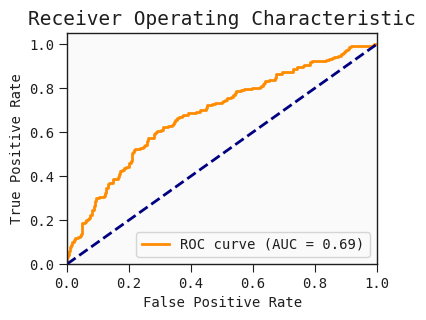

In [376]:
y_true_list_lr2_omics_APOE4_demoF_mrmr = extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoF_mrmr= extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoF_mrmr= extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoF_mrmr= extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoF_mrmr= extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoF_mrmr}, Median AUC: {median_auc_lr2_omics_APOE4_demoF_mrmr}, IQR : {iqr_auc_lr2_omics_APOE4_demoF_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoF_mrmr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_true'), extract_results(results_lr2_omics_APOE4_demoF_mrmr, 'y_pred_prob'))

#### L2-Male No feature selection

In [377]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoM, overall_auc_lr2_omics_APOE4_demoM, median_auc_lr2_omics_APOE4_demoM, iqr_auc_lr2_omics_APOE4_demoM, iqr13_auc_lr2_omics_APOE4_demoM = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, global_seed=42) 

params      (100, l2, liblinear)
test_auc                0.616667
Name: 12, dtype: object

params      (0.01, l2, liblinear)
test_auc                      0.5
Name: 0, dtype: object

params      (5, l2, liblinear)
test_auc              0.483333
Name: 8, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.433333
Name: 2, dtype: object

params      (10, l2, liblinear)
test_auc                    0.4
Name: 10, dtype: object

...

params      (5, l2, liblinear)
test_auc              0.519444
Name: 8, dtype: object

params      (1, l2, liblinear)
test_auc              0.319444
Name: 6, dtype: object

params      (0.01, l2, liblinear)
test_auc                    0.525
Name: 0, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.372222
Name: 2, dtype: object

params      (0.01, l2, liblinear)
test_auc                 0.519444
Name: 0, dtype: object

Overall AUC: 0.44752604166666665, Median AUC: 0.45442708333333337, IQR : 0.04036458333333337, IQ1-IQ3: (0.44270833333333326, 0.48307291666666663)


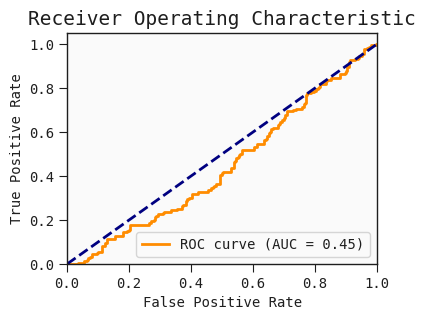

In [379]:
y_true_list_lr2_omics_APOE4_demoM = extract_results(results_lr2_omics_APOE4_demoM, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoM= extract_results(results_lr2_omics_APOE4_demoM, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoM= extract_results(results_lr2_omics_APOE4_demoM, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoM= extract_results(results_lr2_omics_APOE4_demoM, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoM= extract_results(results_lr2_omics_APOE4_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoM}, Median AUC: {median_auc_lr2_omics_APOE4_demoM}, IQR : {iqr_auc_lr2_omics_APOE4_demoM}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoM}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoM, 'y_true'), extract_results(results_lr2_omics_APOE4_demoM, 'y_pred_prob'))

#### L2-Male RFE20

In [380]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoM_rfe, overall_auc_lr2_omics_APOE4_demoM_rfe, median_auc_lr2_omics_APOE4_demoM_rfe, iqr_auc_lr2_omics_APOE4_demoM_rfe, iqr13_auc_lr2_omics_APOE4_demoM_rfe = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (5, l2, saga)
test_auc         0.533333
Name: 9, dtype: object


Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (100, l2, liblinear)
test_auc                0.941667
Name: 12, dtype: object

Do RFE feature Selection


...

Do RFE feature Selection


params      (0.1, l2, liblinear)
test_auc                0.769444
Name: 2, dtype: object

Do RFE feature SelectionDo RFE feature Selection



params      (10, l2, liblinear)
test_auc               0.858333
Name: 10, dtype: object

Do RFE feature Selection


Overall AUC: 0.7065364583333332, Median AUC: 0.6888020833333333, IQR : 0.12304687500000011, IQ1-IQ3: (0.6399739583333333, 0.7630208333333334)


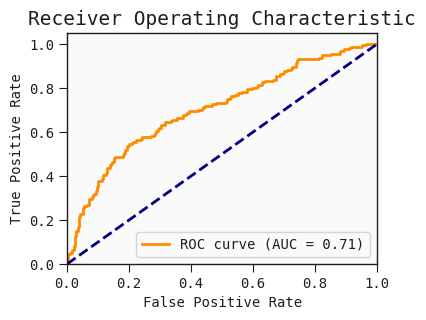

In [382]:
y_true_list_lr2_omics_APOE4_demoM_rfe = extract_results(results_lr2_omics_APOE4_demoM_rfe, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoM_rfe = extract_results(results_lr2_omics_APOE4_demoM_rfe, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoM_rfe = extract_results(results_lr2_omics_APOE4_demoM_rfe, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoM_rfe = extract_results(results_lr2_omics_APOE4_demoM_rfe, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoM_rfe = extract_results(results_lr2_omics_APOE4_demoM_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoM_rfe}, Median AUC: {median_auc_lr2_omics_APOE4_demoM_rfe}, IQR : {iqr_auc_lr2_omics_APOE4_demoM_rfe}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoM_rfe}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoM_rfe, 'y_true'), extract_results(results_lr2_omics_APOE4_demoM_rfe, 'y_pred_prob'))

#### L2-Male MRMR20

In [383]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoM_mrmr, overall_auc_lr2_omics_APOE4_demoM_mrmr, median_auc_lr2_omics_APOE4_demoM_mrmr, iqr_auc_lr2_omics_APOE4_demoM_mrmr, iqr13_auc_lr2_omics_APOE4_demoM_mrmr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20, global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:06,  2.59it/s]





 15%|█▌        | 3/20 [00:01<00:05,  3.00it/s]





 20%|██        | 4/20 [00:01<00:05,  3.12it/s]





 25%|██▌       | 5/20 [00:01<00:04,  3.35it/s]





 30%|███       | 6/20 [00:01<00:04,  3.39it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.49it/s]





 40%|████      | 8/20 [00:02<00:03,  3.52it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.63it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.47it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.48it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.58it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.60it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.37it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.39it/s]



 80%|████████  | 16/20 [00:04<00:01,  3.58it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.55it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.54it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.50it/s]





100%|██████████

Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


100%|██████████| 20/20 [00:05<00:00,  3.55it/s]

Do MRMR feature selection
Do MRMR feature selection


...

params      (10, l2, liblinear)
test_auc               0.683333
Name: 10, dtype: object

params      (0.1, l2, liblinear)
test_auc                0.741667
Name: 2, dtype: object

 90%|█████████ | 18/20 [00:04<00:00,  2.76it/s]

Do MRMR feature selectionDo MRMR feature selection


 95%|█████████▌| 19/20 [00:05<00:00,  2.60it/s]





100%|██████████| 20/20 [00:05<00:00,  3.43it/s]






































































































100%|██████████| 20/20 [00:04<00:00,  4.40it/s]






100%|██████████| 20/20 [00:04<00:00,  4.38it/s]


100%|██████████| 20/20 [00:04<00:00,  4.60it/s]



100%|██████████| 20/20 [00:04<00:00,  4.85it/s]


Overall AUC: 0.6560937499999999, Median AUC: 0.6471354166666667, IQR : 0.05143229166666674, IQ1-IQ3: (0.625, 0.6764322916666667)


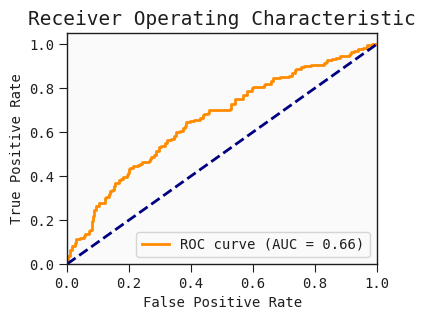

In [385]:
y_true_list_lr2_omics_APOE4_demoM_mrmr = extract_results(results_lr2_omics_APOE4_demoM_mrmr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoM_mrmr = extract_results(results_lr2_omics_APOE4_demoM_mrmr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoM_mrmr = extract_results(results_lr2_omics_APOE4_demoM_mrmr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoM_mrmr = extract_results(results_lr2_omics_APOE4_demoM_mrmr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoM_mrmr = extract_results(results_lr2_omics_APOE4_demoM_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoM_mrmr}, Median AUC: {median_auc_lr2_omics_APOE4_demoM_mrmr}, IQR : {iqr_auc_lr2_omics_APOE4_demoM_mrmr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoM_mrmr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoM_mrmr, 'y_true'), extract_results(results_lr2_omics_APOE4_demoM_mrmr, 'y_pred_prob'))

#### L2-Male correlation20

In [386]:
lr2_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l2'],  
    'solver': ['saga','liblinear']  
}
lr2_param_combinations = list(itertools.product(lr2_param_grid['C'], lr2_param_grid['penalty'], lr2_param_grid['solver']))
results_lr2_omics_APOE4_demoM_corr, overall_auc_lr2_omics_APOE4_demoM_corr, median_auc_lr2_omics_APOE4_demoM_corr, iqr_auc_lr2_omics_APOE4_demoM_corr, iqr13_auc_lr2_omics_APOE4_demoM_corr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'logistic_regression', lr2_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (10, l2, liblinear)
test_auc               0.791667
Name: 10, dtype: object

params      (100, l2, liblinear)
test_auc                   0.675
Name: 12, dtype: object

params      (5, l2, saga)
test_auc            0.625
Name: 9, dtype: object

Do Correlation-Based feature selectionDo Correlation-Based feature selection



...

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.588889
Name: 12, dtype: object

Do Correlation-Based feature selection


params      (100, l2, liblinear)
test_auc                0.747222
Name: 12, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.674296875, Median AUC: 0.6783854166666667, IQR : 0.12434895833333326, IQ1-IQ3: (0.62109375, 0.7454427083333333)


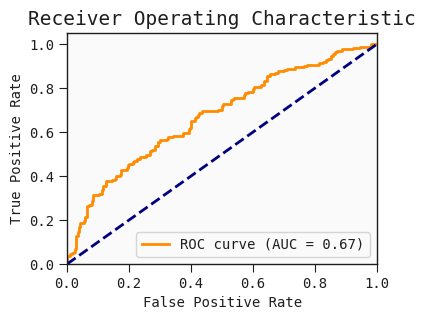

In [388]:
y_true_list_lr2_omics_APOE4_demoM_corr = extract_results(results_lr2_omics_APOE4_demoM_corr, 'y_true')
y_pred_prob_list_lr2_omics_APOE4_demoM_corr= extract_results(results_lr2_omics_APOE4_demoM_corr, 'y_pred_prob')
y_pred_list_lr2_omics_APOE4_demoM_corr= extract_results(results_lr2_omics_APOE4_demoM_corr, 'y_pred')
feature_selection_df_lr2_omics_APOE4_demoM_corr= extract_results(results_lr2_omics_APOE4_demoM_corr, 'feature_selection_df')
feature_sum_coef_df_lr2_omics_APOE4_demoM_corr= extract_results(results_lr2_omics_APOE4_demoM_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr2_omics_APOE4_demoM_corr}, Median AUC: {median_auc_lr2_omics_APOE4_demoM_corr}, IQR : {iqr_auc_lr2_omics_APOE4_demoM_corr}, IQ1-IQ3: {iqr13_auc_lr2_omics_APOE4_demoM_corr}") 
auc_plot(extract_results(results_lr2_omics_APOE4_demoM_corr, 'y_true'), extract_results(results_lr2_omics_APOE4_demoM_corr, 'y_pred_prob'))

### SVM

#### SVM-Full No feature selection

In [389]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_demo, overall_auc_svm_omics_APOE4_demo, median_auc_svm_omics_APOE4_demo, iqr_auc_svm_omics_APOE4_demo, iqr13_auc_svm_omics_APOE4_demo = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.01, linear, auto)
test_auc                0.494167
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.452778
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.463519
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.508426
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.614259
Name: 0, dtype: object

...

params      (0.01, linear, auto)
test_auc                0.522685
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.374815
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.405463
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.422407
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                 0.42463
Name: 0, dtype: object

Overall AUC: 0.4422805194805195, Median AUC: 0.44285714285714284, IQR : 0.0612987012987013, IQ1-IQ3: (0.39883116883116887, 0.46012987012987017)


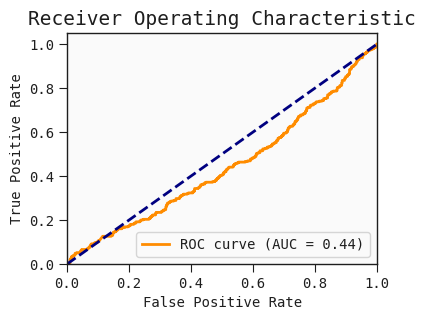

In [391]:
y_true_list_svm_omics_APOE4_demo = extract_results(results_svm_omics_APOE4_demo, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demo= extract_results(results_svm_omics_APOE4_demo, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demo= extract_results(results_svm_omics_APOE4_demo, 'y_pred')
feature_selection_df_svm_omics_APOE4_demo= extract_results(results_svm_omics_APOE4_demo, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demo= extract_results(results_svm_omics_APOE4_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demo}, Median AUC: {median_auc_svm_omics_APOE4_demo}, IQR : {iqr_auc_svm_omics_APOE4_demo}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demo}") 
auc_plot(extract_results(results_svm_omics_APOE4_demo, 'y_true'), extract_results(results_svm_omics_APOE4_demo, 'y_pred_prob'))

#### SVM-Full RFE20

In [392]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_APOE4_demo_rfe, overall_auc_svm_omics_APOE4_demo_rfe, median_auc_svm_omics_APOE4_demo_rfe, iqr_auc_svm_omics_APOE4_demo_rfe, iqr13_auc_svm_omics_APOE4_demo_rfe = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.640278
Name: 4, dtype: object

Do RFE feature Selection


params      (100, linear, auto)
test_auc               0.629537
Name: 8, dtype: object

Do RFE feature Selection


...

params      (0.1, linear, auto)
test_auc               0.508611
Name: 2, dtype: object

Do RFE feature Selection


params      (1, linear, auto)
test_auc               0.6975
Name: 4, dtype: object

params      (1, linear, auto)
test_auc             0.539537
Name: 4, dtype: object

Do RFE feature Selection
Do RFE feature Selection


Overall AUC: 0.4736, Median AUC: 0.4828571428571428, IQR : 0.05311688311688312, IQ1-IQ3: (0.44402597402597405, 0.49714285714285716)


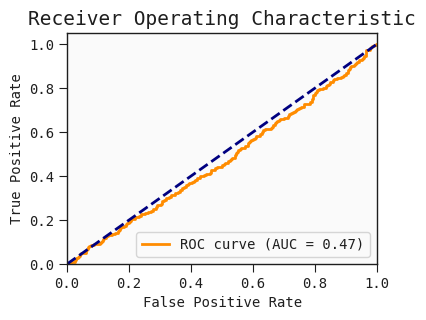

In [394]:
y_true_list_svm_omics_APOE4_demo_rfe = extract_results(results_svm_omics_APOE4_demo_rfe, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demo_rfe= extract_results(results_svm_omics_APOE4_demo_rfe, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demo_rfe= extract_results(results_svm_omics_APOE4_demo_rfe, 'y_pred')
feature_selection_df_svm_omics_APOE4_demo_rfe= extract_results(results_svm_omics_APOE4_demo_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demo_rfe= extract_results(results_svm_omics_APOE4_demo_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demo_rfe}, Median AUC: {median_auc_svm_omics_APOE4_demo_rfe}, IQR : {iqr_auc_svm_omics_APOE4_demo_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demo_rfe}") 
auc_plot(extract_results(results_svm_omics_APOE4_demo_rfe, 'y_true'), extract_results(results_svm_omics_APOE4_demo_rfe, 'y_pred_prob'))

#### SVM-Full MRMR20

In [22]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_APOE4_demo_mrmr, overall_auc_svm_omics_APOE4_demo_mrmr, median_auc_svm_omics_APOE4_demo_mrmr, iqr_auc_svm_omics_APOE4_demo_mrmr, iqr13_auc_svm_omics_APOE4_demo_mrmr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection
Do MRMR feature selection

Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.06it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.65it/s]



 20%|██        | 4/20 [00:01<00:05,  2.98it/s]


 25%|██▌       | 5/20 [00:01<00:04,  3.49it/s]





 30%|███       | 6/20 [00:01<00:03,  3.64it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.27it/s]





 40%|████      | 8/20 [00:02<00:03,  3.57it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.50it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.68it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.66it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.69it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.68it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.73it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.73it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.82it/s]





 85%|████████▌ | 17/20 [00:04<00:00,  3.76it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.81it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.82it/s]





100%|██████████| 2

Do MRMR feature selection


Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]

...

Do MRMR feature selection
Do MRMR feature selection


params      (100, linear, auto)
test_auc               0.605926
Name: 8, dtype: object




 10%|█         | 2/20 [00:00<00:03,  5.20it/s]

Do MRMR feature selection



 15%|█▌        | 3/20 [00:00<00:05,  3.31it/s]


 20%|██        | 4/20 [00:00<00:03,  4.09it/s]

 30%|███       | 6/20 [00:01<00:02,  4.91it/s]


 35%|███▌      | 7/20 [00:01<00:02,  4.65it/s]


 40%|████      | 8/20 [00:01<00:02,  4.92it/s]


 45%|████▌     | 9/20 [00:02<00:02,  4.91it/s]


 50%|█████     | 10/20 [00:02<00:02,  4.80it/s]


 55%|█████▌    | 11/20 [00:02<00:01,  4.95it/s]


 60%|██████    | 12/20 [00:02<00:01,  4.71it/s]


 65%|██████▌   | 13/20 [00:02<00:01,  4.76it/s]

 70%|███████   | 14/20 [00:03<00:01,  4.75it/s]


 75%|███████▌  | 15/20 [00:03<00:00,  5.14it/s]


 80%|████████  | 16/20 [00:03<00:00,  4.97it/s]


 85%|████████▌ | 17/20 [00:03<00:00,  4.88it/s]


 90%|█████████ | 18/20 [00:03<00:00,  4.84it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.55it/s]


100%|██████████| 20/20 [00:04<00:00,  4.65it/s]








100%|██████████| 20/20 [00:04<00:00,  4.61it/s]



100%|██████████| 20/20 [00:03<00:00,  5.09it/s]


Overall AUC: 0.4565090909090909, Median AUC: 0.4475324675324675, IQR : 0.08038961038961034, IQ1-IQ3: (0.42480519480519485, 0.5051948051948052)


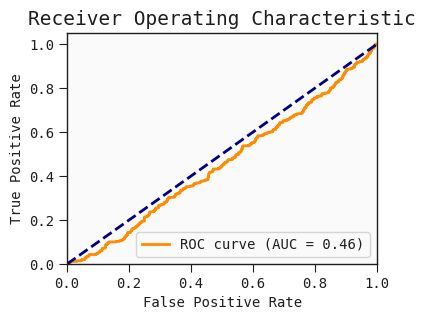

In [24]:
y_true_list_svm_omics_APOE4_demo_mrmr = extract_results(results_svm_omics_APOE4_demo_mrmr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demo_mrmr= extract_results(results_svm_omics_APOE4_demo_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demo_mrmr= extract_results(results_svm_omics_APOE4_demo_mrmr, 'y_pred')
feature_selection_df_svm_omics_APOE4_demo_mrmr= extract_results(results_svm_omics_APOE4_demo_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demo_mrmr= extract_results(results_svm_omics_APOE4_demo_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demo_mrmr}, Median AUC: {median_auc_svm_omics_APOE4_demo_mrmr}, IQR : {iqr_auc_svm_omics_APOE4_demo_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demo_mrmr}") 
auc_plot(extract_results(results_svm_omics_APOE4_demo_mrmr, 'y_true'), extract_results(results_svm_omics_APOE4_demo_mrmr, 'y_pred_prob'))

#### SVM-Full correlation20

In [25]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_demo_corr, overall_auc_svm_omics_APOE4_demo_corr, median_auc_svm_omics_APOE4_demo_corr, iqr_auc_svm_omics_APOE4_demo_corr, iqr13_auc_svm_omics_APOE4_demo_corr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.582315
Name: 0, dtype: object

params      (100, linear, auto)
test_auc               0.690648
Name: 8, dtype: object

Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc               0.686204
Name: 2, dtype: object

...

params      (1, linear, auto)
test_auc             0.541759
Name: 4, dtype: object

Do Correlation-Based feature selection


params      (10, linear, auto)
test_auc              0.667593
Name: 6, dtype: object

params      (0.01, linear, auto)
test_auc                0.663056
Name: 0, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.4727792207792208, Median AUC: 0.46285714285714286, IQR : 0.04272727272727278, IQ1-IQ3: (0.44597402597402597, 0.48870129870129875)


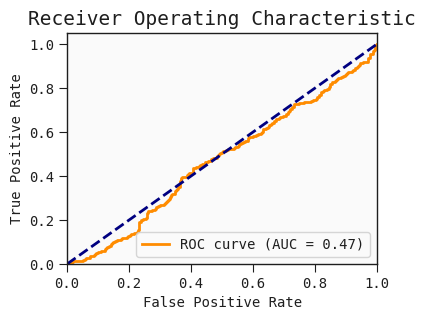

In [27]:
y_true_list_svm_omics_APOE4_demo_corr = extract_results(results_svm_omics_APOE4_demo_corr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demo_corr = extract_results(results_svm_omics_APOE4_demo_corr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demo_corr = extract_results(results_svm_omics_APOE4_demo_corr, 'y_pred')
feature_selection_df_svm_omics_APOE4_demo_corr = extract_results(results_svm_omics_APOE4_demo_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demo_corr = extract_results(results_svm_omics_APOE4_demo_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demo_corr}, Median AUC: {median_auc_svm_omics_APOE4_demo_corr}, IQR : {iqr_auc_svm_omics_APOE4_demo_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demo_corr}") 
auc_plot(extract_results(results_svm_omics_APOE4_demo_corr, 'y_true'), extract_results(results_svm_omics_APOE4_demo_corr, 'y_pred_prob'))

#### SVM-Female No feature selection

In [28]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_demoF, overall_auc_svm_omics_APOE4_demoF, median_auc_svm_omics_APOE4_demoF, iqr_auc_svm_omics_APOE4_demoF, iqr13_auc_svm_omics_APOE4_demoF = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.1, linear, auto)
test_auc               0.426667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.68
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.64
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.493333
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                   0.48
Name: 2, dtype: object

...

params      (0.1, linear, auto)
test_auc               0.348333
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                  0.725
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc               0.540833
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                  0.4875
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc                   0.74
Name: 2, dtype: object

Overall AUC: 0.47538200339558573, Median AUC: 0.46307300509337856, IQR : 0.06409168081494065, IQ1-IQ3: (0.43590831918505935, 0.5)


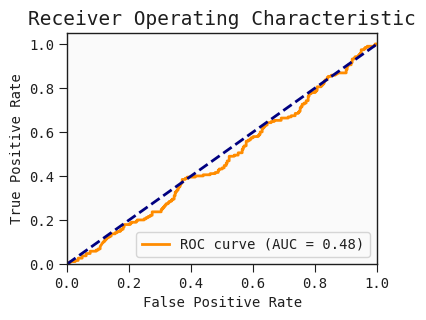

In [30]:
y_true_list_svm_omics_APOE4_demoF = extract_results(results_svm_omics_APOE4_demoF, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoF= extract_results(results_svm_omics_APOE4_demoF, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoF= extract_results(results_svm_omics_APOE4_demoF, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoF= extract_results(results_svm_omics_APOE4_demoF, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoF= extract_results(results_svm_omics_APOE4_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoF}, Median AUC: {median_auc_svm_omics_APOE4_demoF}, IQR : {iqr_auc_svm_omics_APOE4_demoF}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoF}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoF, 'y_true'), extract_results(results_svm_omics_APOE4_demoF, 'y_pred_prob'))

#### SVM-Female RFE20

In [31]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_APOE4_demoF_rfe, overall_auc_svm_omics_APOE4_demoF_rfe, median_auc_svm_omics_APOE4_demoF_rfe, iqr_auc_svm_omics_APOE4_demoF_rfe, iqr13_auc_svm_omics_APOE4_demoF_rfe = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature SelectionDo RFE feature Selection

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.1, linear, auto)
test_auc               0.813333
Name: 2, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.866667
Name: 4, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (1, linear, auto)
test_auc             0.738333
Name: 4, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, linear, auto)
test_auc                0.7525
Name: 6, dtype: object

Do RFE feature Selection


Overall AUC: 0.702546689303905, Median AUC: 0.7173174872665535, IQR : 0.057300509337860905, IQ1-IQ3: (0.6842105263157894, 0.7415110356536503)


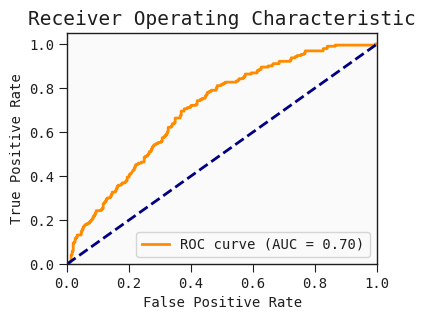

In [33]:
y_true_list_svm_omics_APOE4_demoF_rfe = extract_results(results_svm_omics_APOE4_demoF_rfe, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoF_rfe= extract_results(results_svm_omics_APOE4_demoF_rfe, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoF_rfe= extract_results(results_svm_omics_APOE4_demoF_rfe, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoF_rfe= extract_results(results_svm_omics_APOE4_demoF_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoF_rfe= extract_results(results_svm_omics_APOE4_demoF_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoF_rfe}, Median AUC: {median_auc_svm_omics_APOE4_demoF_rfe}, IQR : {iqr_auc_svm_omics_APOE4_demoF_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoF_rfe}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoF_rfe, 'y_true'), extract_results(results_svm_omics_APOE4_demoF_rfe, 'y_pred_prob'))

#### SVM-Female MRMR20

In [34]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_APOE4_demoF_mrmr, overall_auc_svm_omics_APOE4_demoF_mrmr, median_auc_svm_omics_APOE4_demoF_mrmr, iqr_auc_svm_omics_APOE4_demoF_mrmr, iqr13_auc_svm_omics_APOE4_demoF_mrmr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.15it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.66it/s]





 20%|██        | 4/20 [00:01<00:05,  2.94it/s]





 25%|██▌       | 5/20 [00:01<00:04,  3.08it/s]





 30%|███       | 6/20 [00:02<00:04,  3.17it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.39it/s]



 40%|████      | 8/20 [00:02<00:03,  3.60it/s]





 45%|████▌     | 9/20 [00:02<00:03,  3.61it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.81it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.87it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.75it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.73it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.42it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.41it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.59it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.53it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.54it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.63it/s]







100%|████████

Do MRMR feature selection
Do MRMR feature selection





100%|██████████| 20/20 [00:05<00:00,  3.76it/s]


Do MRMR feature selection
Do MRMR feature selection
Do MRMR feature selection


...

params      (1, linear, auto)
test_auc                 0.74
Name: 4, dtype: object

 55%|█████▌    | 11/20 [00:02<00:02,  3.99it/s]

Do MRMR feature selection


Do MRMR feature selection


 60%|██████    | 12/20 [00:03<00:02,  3.01it/s]





 65%|██████▌   | 13/20 [00:03<00:02,  3.12it/s]





 70%|███████   | 14/20 [00:03<00:01,  3.05it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.23it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.40it/s]





 85%|████████▌ | 17/20 [00:04<00:00,  3.52it/s]





 90%|█████████ | 18/20 [00:04<00:00,  3.63it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.64it/s]



100%|██████████| 20/20 [00:05<00:00,  3.84it/s]


100%|██████████| 20/20 [00:05<00:00,  3.70it/s]











100%|██████████| 20/20 [00:05<00:00,  3.67it/s]

























100%|██████████| 20/20 [00:04<00:00,  4.28it/s]



100%|██████████| 20/20 [00:04<00:00,  4.45it/s]


100%|██████████| 20/20 [00:04<00:00,  4.68it/s]


Overall AUC: 0.6997962648556875, Median AUC: 0.699490662139219, IQR : 0.08149405772495755, IQ1-IQ3: (0.6557724957555178, 0.7372665534804753)


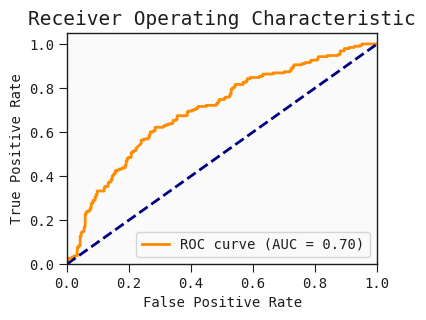

In [36]:
y_true_list_svm_omics_APOE4_demoF_mrmr = extract_results(results_svm_omics_APOE4_demoF_mrmr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoF_mrmr= extract_results(results_svm_omics_APOE4_demoF_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoF_mrmr= extract_results(results_svm_omics_APOE4_demoF_mrmr, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoF_mrmr= extract_results(results_svm_omics_APOE4_demoF_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoF_mrmr= extract_results(results_svm_omics_APOE4_demoF_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoF_mrmr}, Median AUC: {median_auc_svm_omics_APOE4_demoF_mrmr}, IQR : {iqr_auc_svm_omics_APOE4_demoF_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoF_mrmr}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoF_mrmr, 'y_true'), extract_results(results_svm_omics_APOE4_demoF_mrmr, 'y_pred_prob'))

#### SVM-Female correlation20

In [37]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_demoF_corr, overall_auc_svm_omics_APOE4_demoF_corr, median_auc_svm_omics_APOE4_demoF_corr, iqr_auc_svm_omics_APOE4_demoF_corr, iqr13_auc_svm_omics_APOE4_demoF_corr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selectionDo Correlation-Based feature selection

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc                 0.76
Name: 4, dtype: object

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc                 0.84
Name: 4, dtype: object

params      (0.1, linear, auto)
test_auc               0.773333
Name: 2, dtype: object

...

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc             0.746667
Name: 4, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.1, linear, auto)
test_auc                 0.6425
Name: 2, dtype: object

Do Correlation-Based feature selection


Overall AUC: 0.7049066213921902, Median AUC: 0.6876061120543293, IQR : 0.05560271646859083, IQ1-IQ3: (0.6706281833616299, 0.7262308998302207)


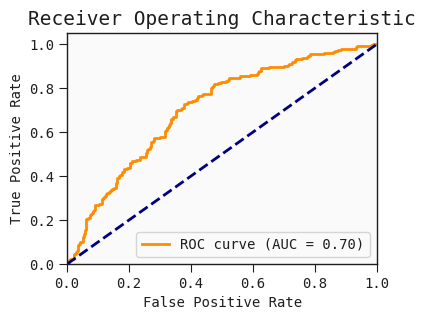

In [39]:
y_true_list_svm_omics_APOE4_demoF_corr = extract_results(results_svm_omics_APOE4_demoF_corr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoF_corr = extract_results(results_svm_omics_APOE4_demoF_corr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoF_corr = extract_results(results_svm_omics_APOE4_demoF_corr, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoF_corr = extract_results(results_svm_omics_APOE4_demoF_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoF_corr = extract_results(results_svm_omics_APOE4_demoF_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoF_corr}, Median AUC: {median_auc_svm_omics_APOE4_demoF_corr}, IQR : {iqr_auc_svm_omics_APOE4_demoF_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoF_corr}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoF_corr, 'y_true'), extract_results(results_svm_omics_APOE4_demoF_corr, 'y_pred_prob'))

#### SVM-Male No feature selection

In [40]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_demoM, overall_auc_svm_omics_APOE4_demoM, median_auc_svm_omics_APOE4_demoM, iqr_auc_svm_omics_APOE4_demoM, iqr13_auc_svm_omics_APOE4_demoM = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, global_seed=42) 

params      (0.1, linear, auto)
test_auc               0.516667
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                   0.575
Name: 0, dtype: object

params      (0.01, linear, auto)
test_auc                0.616667
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.533333
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.433333
Name: 0, dtype: object

...

params      (0.01, linear, auto)
test_auc                0.713889
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.441667
Name: 2, dtype: object

params      (0.1, linear, auto)
test_auc                  0.675
Name: 2, dtype: object

params      (0.01, linear, auto)
test_auc                0.369444
Name: 0, dtype: object

params      (0.1, linear, auto)
test_auc               0.488889
Name: 2, dtype: object

Overall AUC: 0.45496093750000005, Median AUC: 0.47395833333333337, IQR : 0.13997395833333331, IQ1-IQ3: (0.3971354166666667, 0.537109375)


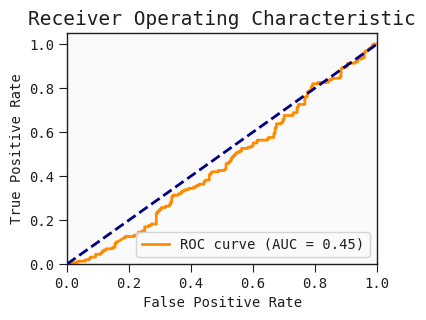

In [42]:
y_true_list_svm_omics_APOE4_demoM = extract_results(results_svm_omics_APOE4_demoM, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoM= extract_results(results_svm_omics_APOE4_demoM, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoM= extract_results(results_svm_omics_APOE4_demoM, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoM= extract_results(results_svm_omics_APOE4_demoM, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoM= extract_results(results_svm_omics_APOE4_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoM}, Median AUC: {median_auc_svm_omics_APOE4_demoM}, IQR : {iqr_auc_svm_omics_APOE4_demoM}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoM}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoM, 'y_true'), extract_results(results_svm_omics_APOE4_demoM, 'y_pred_prob'))

#### SVM-Male RFE20

In [43]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_APOE4_demoM_rfe, overall_auc_svm_omics_APOE4_demoM_rfe, median_auc_svm_omics_APOE4_demoM_rfe, iqr_auc_svm_omics_APOE4_demoM_rfe, iqr13_auc_svm_omics_APOE4_demoM_rfe = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='rfe', num_features=20, global_seed=42) 

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (10, linear, auto)
test_auc                   0.7
Name: 6, dtype: object

Do RFE feature SelectionDo RFE feature Selection



params      (0.01, linear, auto)
test_auc                0.708333
Name: 0, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


...

Do RFE feature Selection


params      (0.1, linear, auto)
test_auc               0.786111
Name: 2, dtype: object

Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection
Do RFE feature Selection


params      (0.01, linear, auto)
test_auc                0.561111
Name: 0, dtype: object

Do RFE feature Selection


Overall AUC: 0.6417708333333334, Median AUC: 0.6197916666666667, IQR : 0.12337239583333348, IQ1-IQ3: (0.5589192708333333, 0.6822916666666667)


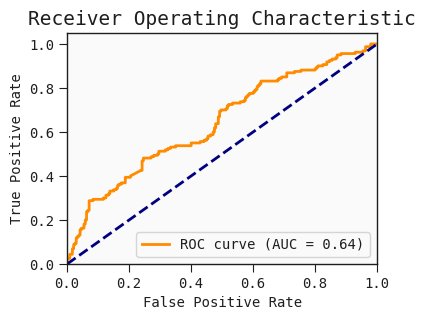

In [45]:
y_true_list_svm_omics_APOE4_demoM_rfe = extract_results(results_svm_omics_APOE4_demoM_rfe, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoM_rfe= extract_results(results_svm_omics_APOE4_demoM_rfe, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoM_rfe= extract_results(results_svm_omics_APOE4_demoM_rfe, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoM_rfe= extract_results(results_svm_omics_APOE4_demoM_rfe, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoM_rfe= extract_results(results_svm_omics_APOE4_demoM_rfe, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoM_rfe}, Median AUC: {median_auc_svm_omics_APOE4_demoM_rfe}, IQR : {iqr_auc_svm_omics_APOE4_demoM_rfe}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoM_rfe}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoM_rfe, 'y_true'), extract_results(results_svm_omics_APOE4_demoM_rfe, 'y_pred_prob'))

#### SVM-Male MRMR20

In [46]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))
results_svm_omics_APOE4_demoM_mrmr, overall_auc_svm_omics_APOE4_demoM_mrmr, median_auc_svm_omics_APOE4_demoM_mrmr, iqr_auc_svm_omics_APOE4_demoM_mrmr, iqr13_auc_svm_omics_APOE4_demoM_mrmr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='mrmr', num_features=20,global_seed=42) 

Do MRMR feature selectionDo MRMR feature selection

Do MRMR feature selection
Do MRMR feature selectionDo MRMR feature selection



  0%|          | 0/20 [00:00<?, ?it/s]


 10%|█         | 2/20 [00:00<00:08,  2.00it/s]





 15%|█▌        | 3/20 [00:01<00:06,  2.60it/s]





 20%|██        | 4/20 [00:01<00:05,  2.80it/s]





 25%|██▌       | 5/20 [00:01<00:05,  2.98it/s]





 30%|███       | 6/20 [00:02<00:04,  3.25it/s]





 35%|███▌      | 7/20 [00:02<00:03,  3.32it/s]



 40%|████      | 8/20 [00:02<00:03,  3.69it/s]





 45%|████▌     | 9/20 [00:02<00:02,  3.68it/s]





 50%|█████     | 10/20 [00:03<00:02,  3.54it/s]





 55%|█████▌    | 11/20 [00:03<00:02,  3.65it/s]





 60%|██████    | 12/20 [00:03<00:02,  3.74it/s]





 65%|██████▌   | 13/20 [00:03<00:01,  3.76it/s]





 70%|███████   | 14/20 [00:04<00:01,  3.54it/s]





 75%|███████▌  | 15/20 [00:04<00:01,  3.25it/s]





 80%|████████  | 16/20 [00:04<00:01,  3.38it/s]





 85%|████████▌ | 17/20 [00:05<00:00,  3.43it/s]





 90%|█████████ | 18/20 [00:05<00:00,  3.37it/s]





 95%|█████████▌| 19/20 [00:05<00:00,  3.51it/s]




100%|██████████|

Do MRMR feature selection





100%|██████████| 20/20 [00:06<00:00,  3.29it/s]

100%|██████████| 20/20 [00:05<00:00,  3.39it/s]


Do MRMR feature selection
Do MRMR feature selection


...

Do MRMR feature selection





 10%|█         | 2/20 [00:00<00:03,  5.37it/s]





100%|██████████| 20/20 [00:05<00:00,  3.42it/s]

 20%|██        | 4/20 [00:00<00:02,  5.59it/s]

params      (0.1, linear, auto)
test_auc               0.730556
Name: 2, dtype: object

Do MRMR feature selection


 25%|██▌       | 5/20 [00:01<00:03,  4.17it/s]


 30%|███       | 6/20 [00:01<00:03,  4.60it/s]


 35%|███▌      | 7/20 [00:01<00:03,  4.12it/s]


 40%|████      | 8/20 [00:01<00:02,  4.24it/s]


 45%|████▌     | 9/20 [00:01<00:02,  4.60it/s]


 50%|█████     | 10/20 [00:02<00:02,  4.62it/s]


 55%|█████▌    | 11/20 [00:02<00:01,  4.56it/s]


 60%|██████    | 12/20 [00:02<00:01,  4.54it/s]


 70%|███████   | 14/20 [00:02<00:01,  4.87it/s]


 75%|███████▌  | 15/20 [00:03<00:00,  5.03it/s]


 80%|████████  | 16/20 [00:03<00:00,  5.03it/s]


 85%|████████▌ | 17/20 [00:03<00:00,  4.69it/s]


 90%|█████████ | 18/20 [00:03<00:00,  4.82it/s]


 95%|█████████▌| 19/20 [00:04<00:00,  4.87it/s]




100%|██████████| 20/20 [00:04<00:00,  4.63it/s]






100%|██████████| 20/20 [00:04<00:00,  4.90it/s]


100%|██████████| 20/20 [00:03<00:00,  5.68it/s]


Overall AUC: 0.5946875, Median AUC: 0.6002604166666667, IQR : 0.11653645833333337, IQ1-IQ3: (0.5442708333333333, 0.6608072916666666)


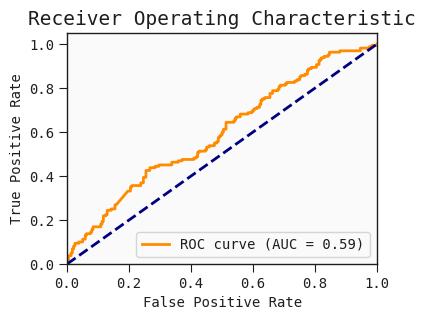

In [48]:
y_true_list_svm_omics_APOE4_demoM_mrmr = extract_results(results_svm_omics_APOE4_demoM_mrmr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoM_mrmr= extract_results(results_svm_omics_APOE4_demoM_mrmr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoM_mrmr= extract_results(results_svm_omics_APOE4_demoM_mrmr, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoM_mrmr= extract_results(results_svm_omics_APOE4_demoM_mrmr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoM_mrmr= extract_results(results_svm_omics_APOE4_demoM_mrmr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoM_mrmr}, Median AUC: {median_auc_svm_omics_APOE4_demoM_mrmr}, IQR : {iqr_auc_svm_omics_APOE4_demoM_mrmr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoM_mrmr}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoM_mrmr, 'y_true'), extract_results(results_svm_omics_APOE4_demoM_mrmr, 'y_pred_prob'))

#### SVM-Male correlation20

In [49]:
svm_rfe_param_grid = {
    'C': [0.1, 0.01, 1, 10, 100],
    'kernel': ['linear'],
    'gamma': ['scale', 'auto']
}
svm_rfe_param_combinations = list(itertools.product(svm_rfe_param_grid['C'], svm_rfe_param_grid['kernel'],
                                                svm_rfe_param_grid['gamma']))

results_svm_omics_APOE4_demoM_corr, overall_auc_svm_omics_APOE4_demoM_corr, median_auc_svm_omics_APOE4_demoM_corr, iqr_auc_svm_omics_APOE4_demoM_corr, iqr13_auc_svm_omics_APOE4_demoM_corr = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'svm', svm_rfe_param_combinations, n_runs=10, feature_selection_method='correlation', num_features=20, global_seed=42) 

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


params      (0.01, linear, auto)
test_auc                0.658333
Name: 0, dtype: object

params      (10, linear, auto)
test_auc                 0.675
Name: 6, dtype: object

params      (10, linear, auto)
test_auc                   0.7
Name: 6, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection
Do Correlation-Based feature selection


...

params      (100, linear, auto)
test_auc               0.538889
Name: 8, dtype: object

Do Correlation-Based feature selection


params      (1, linear, auto)
test_auc             0.691667
Name: 4, dtype: object

params      (1, linear, auto)
test_auc             0.669444
Name: 4, dtype: object

Do Correlation-Based feature selection
Do Correlation-Based feature selection


Overall AUC: 0.6043489583333332, Median AUC: 0.59765625, IQR : 0.11588541666666674, IQ1-IQ3: (0.5052083333333333, 0.62109375)


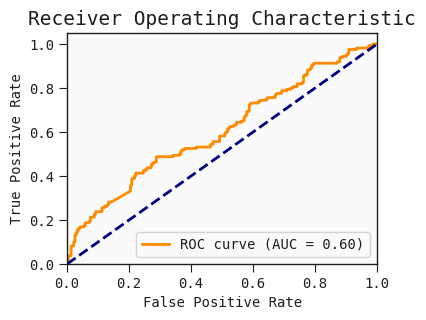

In [51]:
y_true_list_svm_omics_APOE4_demoM_corr = extract_results(results_svm_omics_APOE4_demoM_corr, 'y_true')
y_pred_prob_list_svm_omics_APOE4_demoM_corr = extract_results(results_svm_omics_APOE4_demoM_corr, 'y_pred_prob')
y_pred_list_svm_omics_APOE4_demoM_corr = extract_results(results_svm_omics_APOE4_demoM_corr, 'y_pred')
feature_selection_df_svm_omics_APOE4_demoM_corr = extract_results(results_svm_omics_APOE4_demoM_corr, 'feature_selection_df')
feature_sum_coef_df_svm_omics_APOE4_demoM_corr = extract_results(results_svm_omics_APOE4_demoM_corr, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_svm_omics_APOE4_demoM_corr}, Median AUC: {median_auc_svm_omics_APOE4_demoM_corr}, IQR : {iqr_auc_svm_omics_APOE4_demoM_corr}, IQ1-IQ3: {iqr13_auc_svm_omics_APOE4_demoM_corr}") 
auc_plot(extract_results(results_svm_omics_APOE4_demoM_corr, 'y_true'), extract_results(results_svm_omics_APOE4_demoM_corr, 'y_pred_prob'))

### Random Forest

#### RF-Full No feature selection

In [52]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_APOE4_demo, overall_auc_rf_omics_APOE4_demo, median_auc_rf_omics_APOE4_demo, iqr_auc_rf_omics_APOE4_demo, iqr13_auc_rf_omics_APOE4_demo = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (5, 5, 10, 4)
test_auc         0.521204
Name: 7, dtype: object

params      (50, 5, 10, 2)
test_auc          0.492315
Name: 18, dtype: object

params      (5, 3, 2, 2)
test_auc        0.513519
Name: 0, dtype: object

params      (5, 3, 2, 2)
test_auc        0.677639
Name: 0, dtype: object

params      (500, 3, 2, 2)
test_auc          0.504352
Name: 36, dtype: object

...

params      (5, 5, 2, 4)
test_auc        0.544769
Name: 5, dtype: object

params      (5, 5, 2, 4)
test_auc        0.493981
Name: 5, dtype: object

params      (5, 3, 2, 2)
test_auc        0.605926
Name: 0, dtype: object

params      (5, None, 2, 2)
test_auc            0.58787
Name: 8, dtype: object

params      (50, 3, 2, 4)
test_auc         0.640833
Name: 13, dtype: object

Overall AUC: 0.4562727272727272, Median AUC: 0.4512987012987013, IQR : 0.07772727272727281, IQ1-IQ3: (0.4136363636363636, 0.4913636363636364)


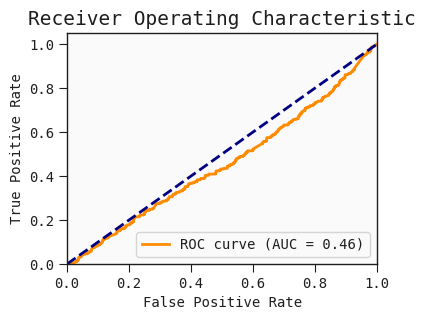

In [54]:
y_true_list_rf_omics_APOE4_demo = extract_results(results_rf_omics_APOE4_demo, 'y_true')
y_pred_prob_list_rf_omics_APOE4_demo= extract_results(results_rf_omics_APOE4_demo, 'y_pred_prob')
y_pred_list_rf_omics_APOE4_demo= extract_results(results_rf_omics_APOE4_demo, 'y_pred')
feature_selection_df_rf_omics_APOE4_demo= extract_results(results_rf_omics_APOE4_demo, 'feature_selection_df')
feature_sum_coef_df_rf_omics_APOE4_demo= extract_results(results_rf_omics_APOE4_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_APOE4_demo}, Median AUC: {median_auc_rf_omics_APOE4_demo}, IQR : {iqr_auc_rf_omics_APOE4_demo}, IQ1-IQ3: {iqr13_auc_rf_omics_APOE4_demo}") 
auc_plot(extract_results(results_rf_omics_APOE4_demo, 'y_true'), extract_results(results_rf_omics_APOE4_demo, 'y_pred_prob'))

#### RF-Female No feature selection

In [55]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_APOE4_demoF, overall_auc_rf_omics_APOE4_demoF, median_auc_rf_omics_APOE4_demoF, iqr_auc_rf_omics_APOE4_demoF, iqr13_auc_rf_omics_APOE4_demoF = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (100, None, 2, 4)
test_auc             0.706667
Name: 33, dtype: object

params      (100, 3, 2, 2)
test_auc          0.786667
Name: 24, dtype: object

params      (100, 5, 2, 4)
test_auc          0.773333
Name: 29, dtype: object

params      (50, 3, 10, 4)
test_auc              0.68
Name: 15, dtype: object

params      (50, None, 10, 4)
test_auc             0.653333
Name: 23, dtype: object

...

params      (500, None, 10, 4)
test_auc              0.775833
Name: 47, dtype: object

params      (50, None, 2, 4)
test_auc                 0.7
Name: 21, dtype: object

params      (5, None, 10, 2)
test_auc              0.6375
Name: 10, dtype: object

params      (5, 3, 10, 4)
test_auc         0.624167
Name: 3, dtype: object

params      (5, None, 2, 4)
test_auc           0.803333
Name: 9, dtype: object

Overall AUC: 0.6110526315789474, Median AUC: 0.5772495755517827, IQR : 0.10292869269949068, IQ1-IQ3: (0.5613327674023769, 0.6642614601018676)


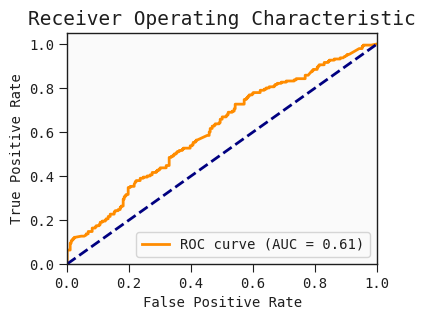

In [57]:
y_true_list_rf_omics_APOE4_demoF = extract_results(results_rf_omics_APOE4_demoF, 'y_true')
y_pred_prob_list_rf_omicsF = extract_results(results_rf_omics_APOE4_demoF, 'y_pred_prob')
y_pred_list_rf_omics_APOE4_demoF = extract_results(results_rf_omics_APOE4_demoF, 'y_pred')
feature_selection_df_rf_omics_APOE4_demoF = extract_results(results_rf_omics_APOE4_demoF, 'feature_selection_df')
feature_sum_coef_df_rf_omics_APOE4_demoF = extract_results(results_rf_omics_APOE4_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_APOE4_demoF}, Median AUC: {median_auc_rf_omics_APOE4_demoF}, IQR : {iqr_auc_rf_omics_APOE4_demoF}, IQ1-IQ3: {iqr13_auc_rf_omics_APOE4_demoF}") 
auc_plot(extract_results(results_rf_omics_APOE4_demoF, 'y_true'), extract_results(results_rf_omics_APOE4_demoF, 'y_pred_prob'))

#### RF-Male No feature selection

In [58]:
### random Forest
rf_param_grid = {
    'n_estimators': [5, 50, 100, 500],
    'max_depth': [None, 3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2, 4]
}

rf_param_combinations = list(itertools.product(rf_param_grid['n_estimators'], rf_param_grid['max_depth'],
                                               rf_param_grid['min_samples_split'], rf_param_grid['min_samples_leaf']))
results_rf_omics_APOE4_demoM, overall_auc_rf_omics_APOE4_demoM, median_auc_rf_omics_APOE4_demoM, iqr_auc_rf_omics_APOE4_demoM, iqr13_auc_rf_omics_APOE4_demoM = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'random_forest',  rf_param_combinations, n_runs=10, global_seed=42) 

params      (5, 5, 10, 4)
test_auc              0.6
Name: 7, dtype: object

params      (50, 3, 2, 2)
test_auc         0.591667
Name: 12, dtype: object

params      (100, 3, 10, 4)
test_auc           0.533333
Name: 27, dtype: object

params      (5, 3, 2, 4)
test_auc        0.491667
Name: 1, dtype: object

params      (5, 3, 10, 2)
test_auc         0.604167
Name: 2, dtype: object

...

params      (5, None, 10, 2)
test_auc            0.597222
Name: 10, dtype: object

params      (5, 3, 10, 2)
test_auc         0.484722
Name: 2, dtype: object

params      (5, 3, 2, 2)
test_auc        0.665278
Name: 0, dtype: object

params      (100, None, 10, 2)
test_auc              0.413889
Name: 34, dtype: object

params      (500, 3, 2, 4)
test_auc          0.508333
Name: 37, dtype: object

Overall AUC: 0.49003906249999996, Median AUC: 0.49739583333333337, IQR : 0.06933593750000006, IQ1-IQ3: (0.4563802083333333, 0.5257161458333334)


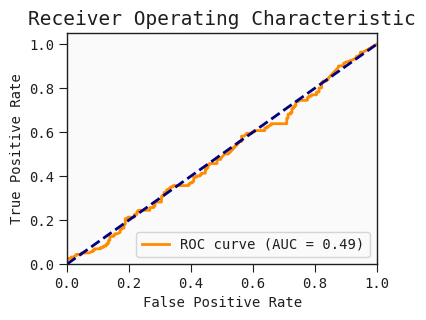

In [60]:
y_true_list_rf_omics_APOE4_demoM = extract_results(results_rf_omics_APOE4_demoM, 'y_true')
y_pred_prob_list_rf_omics_APOE4_demoM = extract_results(results_rf_omics_APOE4_demoM, 'y_pred_prob')
y_pred_list_rf_omics_APOE4_demoM = extract_results(results_rf_omics_APOE4_demoM, 'y_pred')
feature_selection_df_rf_omics_APOE4_demoM = extract_results(results_rf_omics_APOE4_demoM, 'feature_selection_df')
feature_sum_coef_df_rf_omics_APOE4_demoM = extract_results(results_rf_omics_APOE4_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_rf_omics_APOE4_demoM}, Median AUC: {median_auc_rf_omics_APOE4_demoM}, IQR : {iqr_auc_rf_omics_APOE4_demoM}, IQ1-IQ3: {iqr13_auc_rf_omics_APOE4_demoM}") 
auc_plot(extract_results(results_rf_omics_APOE4_demoM, 'y_true'), extract_results(results_rf_omics_APOE4_demoM, 'y_pred_prob'))

### QLattice

#### QLattice-Full No feature selection

In [67]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_APOE4_demo, overall_auc_ql_omics_APOE4_demo, median_auc_ql_omics_APOE4_demo, iqr_auc_ql_omics_APOE4_demo, iqr13_auc_ql_omics_APOE4_demo = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.5523064935064935, Median AUC: 0.5727272727272728, IQR : 0.12584415584415587, IQ1-IQ3: (0.49337662337662336, 0.6192207792207792)


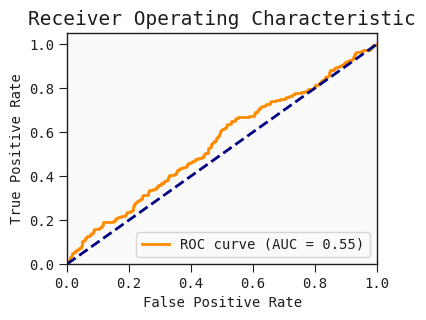

In [69]:
y_true_list_ql_omics_APOE4_demo = extract_results(results_ql_omics_APOE4_demo, 'y_true')
y_pred_prob_list_ql_omics_APOE4_demo = extract_results(results_ql_omics_APOE4_demo, 'y_pred_prob')
y_pred_list_ql_omics_APOE4_demo = extract_results(results_ql_omics_APOE4_demo, 'y_pred')
feature_selection_df_ql_omics_APOE4_demo = extract_results(results_ql_omics_APOE4_demo, 'feature_selection_df')
feature_sum_coef_df_ql_omics_APOE4_demo = extract_results(results_ql_omics_APOE4_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_APOE4_demo}, Median AUC: {median_auc_ql_omics_APOE4_demo}, IQR : {iqr_auc_ql_omics_APOE4_demo}, IQ1-IQ3: {iqr13_auc_ql_omics_APOE4_demo}") 
auc_plot(extract_results(results_ql_omics_APOE4_demo, 'y_true'), extract_results(results_ql_omics_APOE4_demo, 'y_pred_prob'))

#### QLattice-Female No feature selection

In [61]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_APOE4_demoF, overall_auc_ql_omics_APOE4_demoF, median_auc_ql_omics_APOE4_demoF, iqr_auc_ql_omics_APOE4_demoF, iqr13_auc_ql_omics_APOE4_demoF = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.7107215619694397, Median AUC: 0.7478777589134126, IQR : 0.19354838709677424, IQ1-IQ3: (0.5959252971137521, 0.7894736842105263)


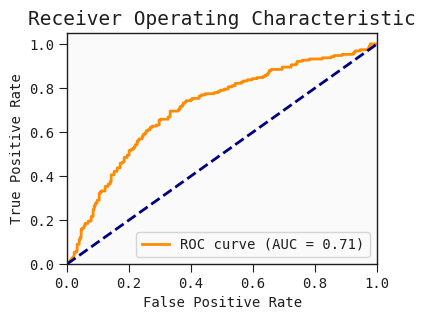

In [63]:
y_true_list_ql_omics_APOE4_demoF = extract_results(results_ql_omics_APOE4_demoF, 'y_true')
y_pred_prob_list_ql_omics_APOE4_demoF = extract_results(results_ql_omics_APOE4_demoF, 'y_pred_prob')
y_pred_list_ql_omics_APOE4_demoF= extract_results(results_ql_omics_APOE4_demoF, 'y_pred')
feature_selection_df_ql_omics_APOE4_demoF= extract_results(results_ql_omics_APOE4_demoF, 'feature_selection_df')
feature_sum_coef_df_ql_omics_APOE4_demoF= extract_results(results_ql_omics_APOE4_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_APOE4_demoF}, Median AUC: {median_auc_ql_omics_APOE4_demoF}, IQR : {iqr_auc_ql_omics_APOE4_demoF}, IQ1-IQ3: {iqr13_auc_ql_omics_APOE4_demoF}") 
auc_plot(extract_results(results_ql_omics_APOE4_demoF, 'y_true'), extract_results(results_ql_omics_APOE4_demoF, 'y_pred_prob'))

#### QLattice-Male No feature selection

In [64]:
ql_param_grid = {
    'n_epochs': [5, 20],  
    'max_complexity': [5, 20]  
}

ql_param_combinations = list(itertools.product(ql_param_grid['n_epochs'], ql_param_grid['max_complexity']))

results_ql_omics_APOE4_demoM, overall_auc_ql_omics_APOE4_demoM, median_auc_ql_omics_APOE4_demoM, iqr_auc_ql_omics_APOE4_demoM, iqr13_auc_ql_omics_APOE4_demoM = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'qlattice', ql_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.7323697916666666, Median AUC: 0.7565104166666667, IQR : 0.05761718749999989, IQ1-IQ3: (0.7184244791666667, 0.7760416666666666)


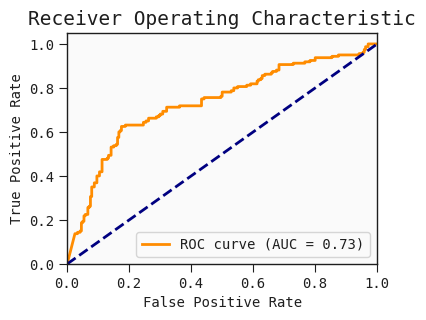

In [66]:
y_true_list_ql_omics_APOE4_demoM = extract_results(results_ql_omics_APOE4_demoM, 'y_true')
y_pred_prob_list_ql_omics_APOE4_demoM = extract_results(results_ql_omics_APOE4_demoM, 'y_pred_prob')
y_pred_list_ql_omics_APOE4_demoM = extract_results(results_ql_omics_APOE4_demoM, 'y_pred')
feature_selection_df_ql_omics_APOE4_demoM = extract_results(results_ql_omics_APOE4_demoM, 'feature_selection_df')
feature_sum_coef_df_ql_omics_APOE4_demoM = extract_results(results_ql_omics_APOE4_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_ql_omics_APOE4_demoM}, Median AUC: {median_auc_ql_omics_APOE4_demoM}, IQR : {iqr_auc_ql_omics_APOE4_demoM}, IQ1-IQ3: {iqr13_auc_ql_omics_APOE4_demoM}") 
auc_plot(extract_results(results_ql_omics_APOE4_demoM, 'y_true'), extract_results(results_ql_omics_APOE4_demoM, 'y_pred_prob'))